# Solace_Health_Modulprojekt_final

[![In Colab öffnen](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/drive/1olZ1NZiWcFBrg7MCE6c8U1vRZ-HvTZn7)

- **Dateiname:** Solace_Health_Modulprojekt_final.ipynb
- **Projekt:** Statistik – Solace Health Clinics (Datensatz: solace_visits.csv)
- **Ersteller:** Milomir Stevanovic
- **Datum:** 05.11.2026

- **Mindestdifferenz:** 5 Minuten (nachträglich festgelegt; siehe Checkpoint 3, Aufgabe 4g)

---

## Vorbereitung: zentrales Setup und Datenbasis

Bibliotheken, Konstanten und die CSV-Datei werden **einmal hier** geladen. Alle Checkpoints arbeiten danach mit denselben Objekten:

- `df_roh`: die Rohdaten genau so, wie sie in `solace_visits.csv` stehen.
- `df`: die **Datenbasis für alle Auswertungen**: Rohdaten ohne die exakten Duplikate. Warum und wie wir das prüfen, steht in Checkpoint 1, Aufgabe 5b. Die Wirkung der Bereinigung zeigt der Vergleich am Ende von Checkpoint 1 (roh gegen bereinigt).
- Nur dort, wo die Aufgabenstellung eine fertige Ausgabe auf den Rohdaten vorgibt (Checkpoint 3, Teil 0), rechnen wir bewusst mit `df_roh` nach, damit jede vorgegebene Zahl reproduziert wird.

**Woher kommt die CSV?** Das Setup sucht `solace_visits.csv` in dieser Reihenfolge:

1. **Lokal** im Ordner des Notebooks (z. B. VS Code, eigener Rechner).
2. **Google Drive:** Download aus dem freigegebenen Abgabeordner ([Link zum Ordner](https://drive.google.com/drive/folders/1RzSTNd-PTGBafNRH5L0ru8gtR_u2lFDQ?usp=drive_link)) mit dem Paket `gdown` (in Colab vorinstalliert, lokal ggf. `pip install gdown`). Voraussetzung: Der Ordner ist für „Jeder mit dem Link“ freigegeben und enthält `solace_visits.csv`.
3. **Upload in Colab** als letzte Möglichkeit.

Welche Quelle genutzt wurde, steht in der Ausgabe. Die Prüfung `assert` auf 1209 Roh- und 1200 bereinigte Zeilen stellt sicher, dass es die richtige Datei ist, egal woher sie kommt.

Jeder Checkpoint setzt unten nur noch sein Ausgabeformat und den Zufalls-Startwert (`seed = 42`). So bleiben alle Simulationen unabhängig von der Reihenfolge der Zellen reproduzierbar.

In [1]:
# ------------------------------------------------------------
# Zentrales Setup: Bibliotheken, Konstanten, CSV laden (einmal für das ganze Notebook)
# ------------------------------------------------------------
from pathlib import Path
import warnings

# Matplotlib 3.11 meldet bei boxplot(..., vert=False) nur eine Umbenennung (kein Fehler). Die Meldung wird ausgeblendet,
# damit sie nicht in den gespeicherten Ausgaben steht (dort stand ein lokaler Dateipfad).
warnings.filterwarnings("ignore", message=r".*vert.*deprecated.*")
import numpy as np  # Zahlen, Zufallszahlen, Simulationen
import pandas as pd  # Tabellen (DataFrames)
import matplotlib.pyplot as plt  # Diagramme
from scipy import stats  # Tests, Verteilungen
from scipy.optimize import (
    brentq,
)  # Nullstellensuche (kleinster nachweisbarer Effekt, Checkpoint 3)

ALPHA = 0.05  # Signifikanzniveau, vor jeder Auswertung festgelegt
CSV_DATEI = "solace_visits.csv"  # Dateiname laut Aufgabenstellung

# Freigegebener Google-Drive-Ordner der Projektabgabe (Freigabe: "Jeder mit dem Link")
DRIVE_ORDNER_URL = "https://drive.google.com/drive/folders/1RzSTNd-PTGBafNRH5L0ru8gtR_u2lFDQ?usp=drive_link"
DOWNLOAD_ORDNER = Path(
    "drive_download"
)  # Zielordner für den Download (wird bei Bedarf angelegt)


def csv_aus_drive_laden() -> Path | None:
    """Lädt CSV_DATEI aus dem Drive-Ordner herunter und gibt den lokalen Pfad zurück (None, wenn nicht möglich)."""
    # Schon einmal heruntergeladen? Dann nicht erneut laden.
    vorhanden = (
        sorted(DOWNLOAD_ORDNER.rglob(CSV_DATEI)) if DOWNLOAD_ORDNER.exists() else []
    )
    if vorhanden:
        return vorhanden[0]
    try:
        import gdown  # in Colab vorinstalliert, lokal: pip install gdown
    except ModuleNotFoundError:
        print("Paket gdown fehlt (pip install gdown) - Drive-Download übersprungen.")
        return None
    try:
        # Zuerst nur den Inhalt des Ordners auflisten und gezielt die CSV laden (gdown >= 5),
        # damit nicht der ganze Abgabeordner (Folien, PDFs ...) heruntergeladen wird.
        try:
            eintraege = (
                gdown.download_folder(
                    url=DRIVE_ORDNER_URL, skip_download=True, quiet=True
                )
                or []
            )
            csv_eintraege = [e for e in eintraege if Path(e.path).name == CSV_DATEI]
            if csv_eintraege:
                ziel = DOWNLOAD_ORDNER / CSV_DATEI
                ziel.parent.mkdir(parents=True, exist_ok=True)
                gdown.download(id=csv_eintraege[0].id, output=str(ziel), quiet=True)
        except TypeError:
            # ältere gdown-Version ohne skip_download: ganzen Ordner laden
            gdown.download_folder(
                url=DRIVE_ORDNER_URL, output=str(DOWNLOAD_ORDNER), quiet=True
            )
    except (
        Exception
    ) as fehler:  # kein Internet, Ordner nicht freigegeben, Drive-Limit ...
        print("Download aus Google Drive nicht möglich:", fehler)
        return None
    treffer = (
        sorted(DOWNLOAD_ORDNER.rglob(CSV_DATEI)) if DOWNLOAD_ORDNER.exists() else []
    )
    if not treffer:
        print(f"{CSV_DATEI} wurde im Drive-Ordner nicht gefunden.")
    return treffer[0] if treffer else None


# Datei suchen: 1. lokal, 2. Google-Drive-Ordner, 3. Upload in Google Colab
if Path(CSV_DATEI).is_file():
    CSV_PFAD, QUELLE = Path(CSV_DATEI), "lokal (Ordner des Notebooks)"
elif (drive_pfad := csv_aus_drive_laden()) is not None:
    CSV_PFAD, QUELLE = drive_pfad, "Google-Drive-Ordner (Download)"
else:
    try:
        from google.colab import files  # type: ignore # nur in Google Colab vorhanden

        print(f"{CSV_DATEI} nicht gefunden - bitte hochladen:")
        files.upload()
        CSV_PFAD, QUELLE = Path(CSV_DATEI), "Upload in Colab"
    except ModuleNotFoundError:
        raise FileNotFoundError(
            f"{CSV_DATEI} nicht gefunden. Datei in den Ordner des Notebooks legen, "
            f"den Drive-Ordner freigeben ({DRIVE_ORDNER_URL}) oder CSV_DATEI anpassen."
        )

print("Datenquelle:", QUELLE, "-", CSV_PFAD)
df_roh = pd.read_csv(CSV_PFAD)  # Rohdaten, unverändert
print("Rohdaten:", df_roh.shape[0], "Zeilen,", df_roh.shape[1], "Spalten")

# Datenbasis für alle Auswertungen: exakte Duplikate (alle Spalten identisch) entfernen, erste Kopie bleibt.
# Prüfung und Begründung: Checkpoint 1, Aufgabe 5b.
df = df_roh.drop_duplicates(keep="first").reset_index(drop=True)
print(
    f"Datenbasis df: {len(df)} Zeilen ({len(df_roh) - len(df)} exakte Duplikate entfernt)"
)
assert (len(df_roh), len(df)) == (1209, 1200)
df_roh.head()

Datenquelle: Google-Drive-Ordner (Download) - drive_download/solace_visits.csv
Rohdaten: 1209 Zeilen, 14 Spalten
Datenbasis df: 1200 Zeilen (9 exakte Duplikate entfernt)


,visit_id,patient_id,appointment_date,clinic_site,appointment_type,insurance_type,day_of_week,no_show,wait_time_min,patient_satisfaction,scheduled_duration_min,actual_duration_min,visit_cost,zip_code
0,R-00001,P-0001,2026-02-28,Downtown,Specialist,Private,Saturday,0,15.72,3.0,30,23.54,228.12,8540
1,R-00002,P-0002,2026-02-12,Northgate,Checkup,Private,Thursday,0,8.57,4.0,15,9.83,118.09,7030
2,R-00003,P-0139,2026-01-08,Downtown,Follow-up,Self-pay,Thursday,1,4.88,NaN,45,23.93,257.17,6510
3,R-00004,P-0004,2026-02-04,Eastview,Urgent,Medicare,Wednesday,0,3.77,NaN,10,10.09,108.58,8540
4,R-00005,P-0005,2026-03-02,Northgate,Checkup,Private,Monday,0,6.52,3.0,20,14.31,102.36,2134


# Checkpoint 1 – Kannst du diesen Daten vertrauen?
**Datensatz:** `solace_visits.csv` – eine Zeile pro Klinikbesuch, ein Quartal (05.01.–05.04.2026), vier Standorte.
**Ziel:** Das Besuchsprotokoll für das Operations-Team zusammenfassen – aber erst, nachdem die Zusammenfassungen fünf Fragen standhalten.

## Die Spielregeln (gelten für das ganze Notebook)
Damit Entscheidungen nachvollziehbar und reproduzierbar sind, gehen wir bei jeder Auswertung gleich vor:

1. **Frage und Hypothesen** formulieren (H₀ = „kein Effekt / kein Zusammenhang“, H₁ = „es gibt einen“).
2. **Voraussetzungen** des Verfahrens prüfen – *nicht* nur behaupten.
3. **Test durchführen** und den p-Wert berichten.
4. **Effektstärke** angeben. Ein kleiner p-Wert sagt nur, dass die Daten schlecht zu H₀ passen, nicht dass der Effekt „stark“ ist. Bei 1.200 Zeilen werden schon kleine Effekte signifikant.
5. **Robustheit prüfen** (Ergebnis mit anderer Methode / ohne auffällige Daten wiederholen).
6. **Interpretieren** – in Alltagssprache, mit Grenzen (Korrelation ≠ Kausalität).

**Signifikanzniveau:** α = 0,05 (festgelegt *vor* den Tests). Ist p < α, verwerfen wir H₀.
**Zufall:** Wo Zufallszahlen nötig sind (Bootstrap), ist der Startwert fest (`seed = 42`), damit die Ergebnisse jedes Mal gleich sind.

> 💡 **Merke:** Alles, was wir im Text *behaupten* („schief“, „kein Unterschied“, „Ausreißer“), prüfen wir auch im Code. Wo etwas nicht prüfbar ist (z. B. ob Werte *wirklich* Eingabefehler sind), sagen wir das offen.

In [2]:
# Checkpoint-1-Setup: Ausgabeformat und Zufalls-Startwert (Bibliotheken und Daten: siehe zentrales Setup oben)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
rng = np.random.default_rng(42)  # fester Startwert -> reproduzierbar
print("Datenbasis df:", df.shape)
df.head()

Datenbasis df: (1200, 14)


,visit_id,patient_id,appointment_date,clinic_site,appointment_type,insurance_type,day_of_week,no_show,wait_time_min,patient_satisfaction,scheduled_duration_min,actual_duration_min,visit_cost,zip_code
0,R-00001,P-0001,2026-02-28,Downtown,Specialist,Private,Saturday,0,15.720,3.000,30,23.540,228.120,8540
1,R-00002,P-0002,2026-02-12,Northgate,Checkup,Private,Thursday,0,8.570,4.000,15,9.830,118.090,7030
2,R-00003,P-0139,2026-01-08,Downtown,Follow-up,Self-pay,Thursday,1,4.880,NaN,45,23.930,257.170,6510
3,R-00004,P-0004,2026-02-04,Eastview,Urgent,Medicare,Wednesday,0,3.770,NaN,10,10.090,108.580,8540
4,R-00005,P-0005,2026-03-02,Northgate,Checkup,Private,Monday,0,6.520,3.000,20,14.310,102.360,2134


### Hilfsfunktionen
Wir definieren sie einmal und verwenden sie in mehreren Aufgaben, damit überall dieselbe Rechnung benutzt wird.

In [3]:
def iqr_flags(s, k=1.5):
    """Tukey-Regel: markiert Werte ausserhalb von [Q1 - k*IQR, Q3 + k*IQR]."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return (s < lo) | (s > hi), lo, hi


def cramers_v(tabelle):
    """Cramérs V: Staerke des Zusammenhangs zweier kategorialer Variablen (0 = keiner, 1 = perfekt)."""
    chi2 = stats.chi2_contingency(tabelle, correction=False)[0]
    n = np.asarray(tabelle).sum()
    return np.sqrt(chi2 / (n * (min(np.asarray(tabelle).shape) - 1)))


def pearson_ci(r, n, alpha=0.05):
    """Konfidenzintervall fuer r ueber die Fisher-z-Transformation."""
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
    zc = stats.norm.ppf(1 - alpha / 2)
    return np.tanh(z - zc * se), np.tanh(z + zc * se)


def bootstrap_ci(x, func, n_boot=5000, alpha=0.05):
    """Bootstrap-Konfidenzintervall (Perzentil-Methode) fuer eine beliebige Kennzahl."""
    x = np.asarray(x)
    stichproben = rng.choice(x, size=(n_boot, len(x)), replace=True)
    werte = func(stichproben, axis=1)
    return np.percentile(werte, [100 * alpha / 2, 100 * (1 - alpha / 2)])

## Überblick: Verteilungen der Variablen

Bevor wir rechnen, schauen wir uns die Daten an: **Dichteplots** für die metrischen Variablen und **Balkendiagramme** für die kategorialen. Beide Diagramme zeigen die bereinigte Datenbasis (ohne die 9 exakten Duplikate).

### Überblick 1: Dichteplots der metrischen Variablen

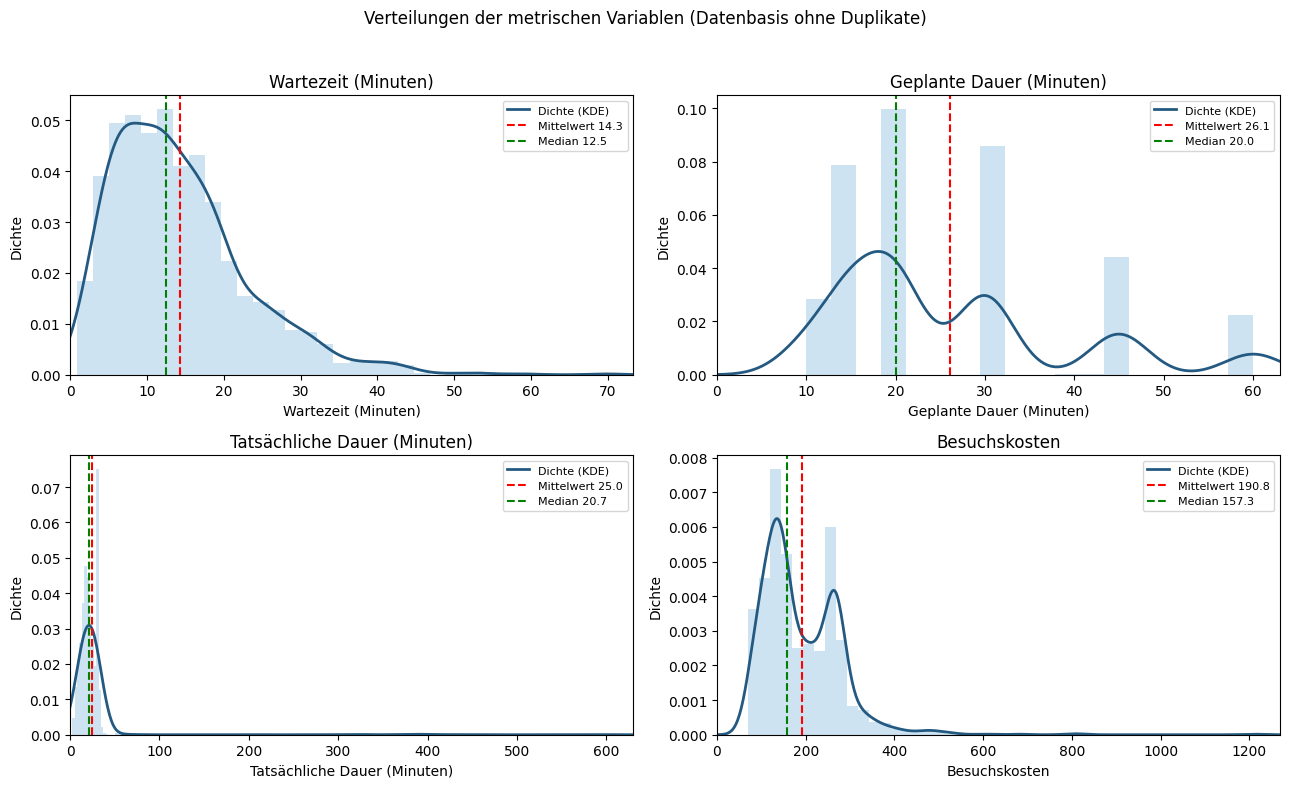

Tatsächliche Dauer, alle 1200 Besuche   : Mittelwert 25.0, Median 20.7, Schiefe 9.62
Ohne die 14 Besuche über dem 5-Fachen der Planung (max. 600 Min.): Mittelwert 21.1, Median 20.6, Schiefe 0.08
Geplante Dauer: 99.75 % der Besuche haben eines der Zeitfenster [10, 15, 20, 30, 45, 60]; verschiedene Werte insgesamt: 9


,n gültig,Mittelwert,Median,Maximum,Schiefe
Variable,,,,,
wait_time_min,1200,14.250,12.520,69.780,1.280
scheduled_duration_min,1200,26.100,20.000,60.000,1.100
actual_duration_min,1200,25.020,20.680,600.000,9.620
visit_cost,1200,190.830,157.280,"1,208.540",2.490


In [4]:
# ------------------------------------------------------------
# Überblick 1: Dichteplots der metrischen Variablen (auf Dichte skaliertes Histogramm + Kerndichte)
# Ziel: Verteilungsform sehen, BEVOR wir rechnen. Rot = Mittelwert, grün = Median.
# ------------------------------------------------------------
metrische_variablen = [
    "wait_time_min",
    "scheduled_duration_min",
    "actual_duration_min",
    "visit_cost",
]
namen = {
    "wait_time_min": "Wartezeit (Minuten)",
    "scheduled_duration_min": "Geplante Dauer (Minuten)",
    "actual_duration_min": "Tatsächliche Dauer (Minuten)",
    "visit_cost": "Besuchskosten",
}

fig, achsen = plt.subplots(2, 2, figsize=(13, 8))
zeilen = []
for ax, var in zip(achsen.flat, metrische_variablen):
    werte = df[var].dropna().to_numpy(dtype=float)
    x = np.linspace(0, werte.max() * 1.05, 600)
    ax.hist(
        werte, bins="fd", density=True, color="#b9d8ed", alpha=0.7
    )  # Histogramm (Dichte)
    ax.plot(
        x, stats.gaussian_kde(werte)(x), color="#245a81", lw=2, label="Dichte (KDE)"
    )
    ax.axvline(
        werte.mean(), color="red", ls="--", label=f"Mittelwert {werte.mean():.1f}"
    )
    ax.axvline(
        np.median(werte), color="green", ls="--", label=f"Median {np.median(werte):.1f}"
    )
    ax.set_title(namen[var])
    ax.set_xlabel(namen[var])
    ax.set_ylabel("Dichte")
    ax.set_xlim(0, werte.max() * 1.05)
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=8)
    zeilen.append(
        {
            "Variable": var,
            "n gültig": len(werte),
            "Mittelwert": werte.mean(),
            "Median": np.median(werte),
            "Maximum": werte.max(),
            "Schiefe": stats.skew(werte),
        }
    )
fig.suptitle("Verteilungen der metrischen Variablen (Datenbasis ohne Duplikate)")
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()
# --- Prüfung der Aussagen zur Verteilungsform (v11) ---
# Rechtsschief = langer Ausläufer nach rechts, Mittelwert über dem Median, positive Schiefe.
akt = df["actual_duration_min"]
verh = akt / df["scheduled_duration_min"]  # Verhältnis tatsächliche / geplante Dauer
extrem = verh > 5  # die klar abgesetzten Werte (siehe Aufgabe 4a-2)
rest = akt[~extrem]
print(
    f"Tatsächliche Dauer, alle {len(akt)} Besuche   : Mittelwert {akt.mean():.1f}, Median {akt.median():.1f}, Schiefe {stats.skew(akt):.2f}"
)
print(
    f"Ohne die {int(extrem.sum())} Besuche über dem 5-Fachen der Planung (max. {akt[extrem].max():.0f} Min.): Mittelwert {rest.mean():.1f}, Median {rest.median():.1f}, Schiefe {stats.skew(rest):.2f}"
)
assert (
    int(extrem.sum()) == 14 and stats.skew(akt) > 9 and abs(stats.skew(rest)) < 0.2
)  # Schiefe kommt von den 14 Werten
# Geplante Dauer: fast nur feste Zeitfenster (diskrete Größe, dennoch als metrisch behandelt)
fenster = [10, 15, 20, 30, 45, 60]
anteil_fenster = df["scheduled_duration_min"].isin(fenster).mean()
print(
    f"Geplante Dauer: {100 * anteil_fenster:.2f} % der Besuche haben eines der Zeitfenster {fenster}; verschiedene Werte insgesamt: {df['scheduled_duration_min'].nunique()}"
)
assert anteil_fenster > 0.99
pd.DataFrame(zeilen).set_index("Variable").round(2)

**Kernaussage:** Wartezeit (Schiefe 1,3), geplante Dauer (1,1) und Besuchskosten (2,5) sind rechtsschief: Der Mittelwert liegt jeweils über dem Median (Kosten: 190,8 gegenüber 157,3). Rechtsschief heißt: Der Ausläufer der Verteilung reicht nach rechts zu den hohen Werten, die Schiefe ist positiv. Die geplante Dauer nimmt fast nur sechs feste Werte an (10, 15, 20, 30, 45 und 60 Minuten); wir behandeln sie trotzdem als metrisch, Dichte und Schiefe sind dafür nur Näherungen. Bei der tatsächlichen Dauer konzentrieren sich die meisten Besuche auf Werte um 20 Minuten. Die starke Rechtsschiefe (Schiefe = 9,6) kommt allein von 14 Besuchen mit mehr als dem 5-Fachen der geplanten Dauer (bis 600 Minuten): Sie heben den Mittelwert (25,0) deutlich über den Median (20,7). Ohne diese 14 Besuche ist die Verteilung nahezu symmetrisch (Schiefe 0,08; Mittelwert 21,1, Median 20,6). Diese Werte prüfen wir in Aufgabe 4.

### Überblick 2: Häufigkeiten der kategorialen Variablen

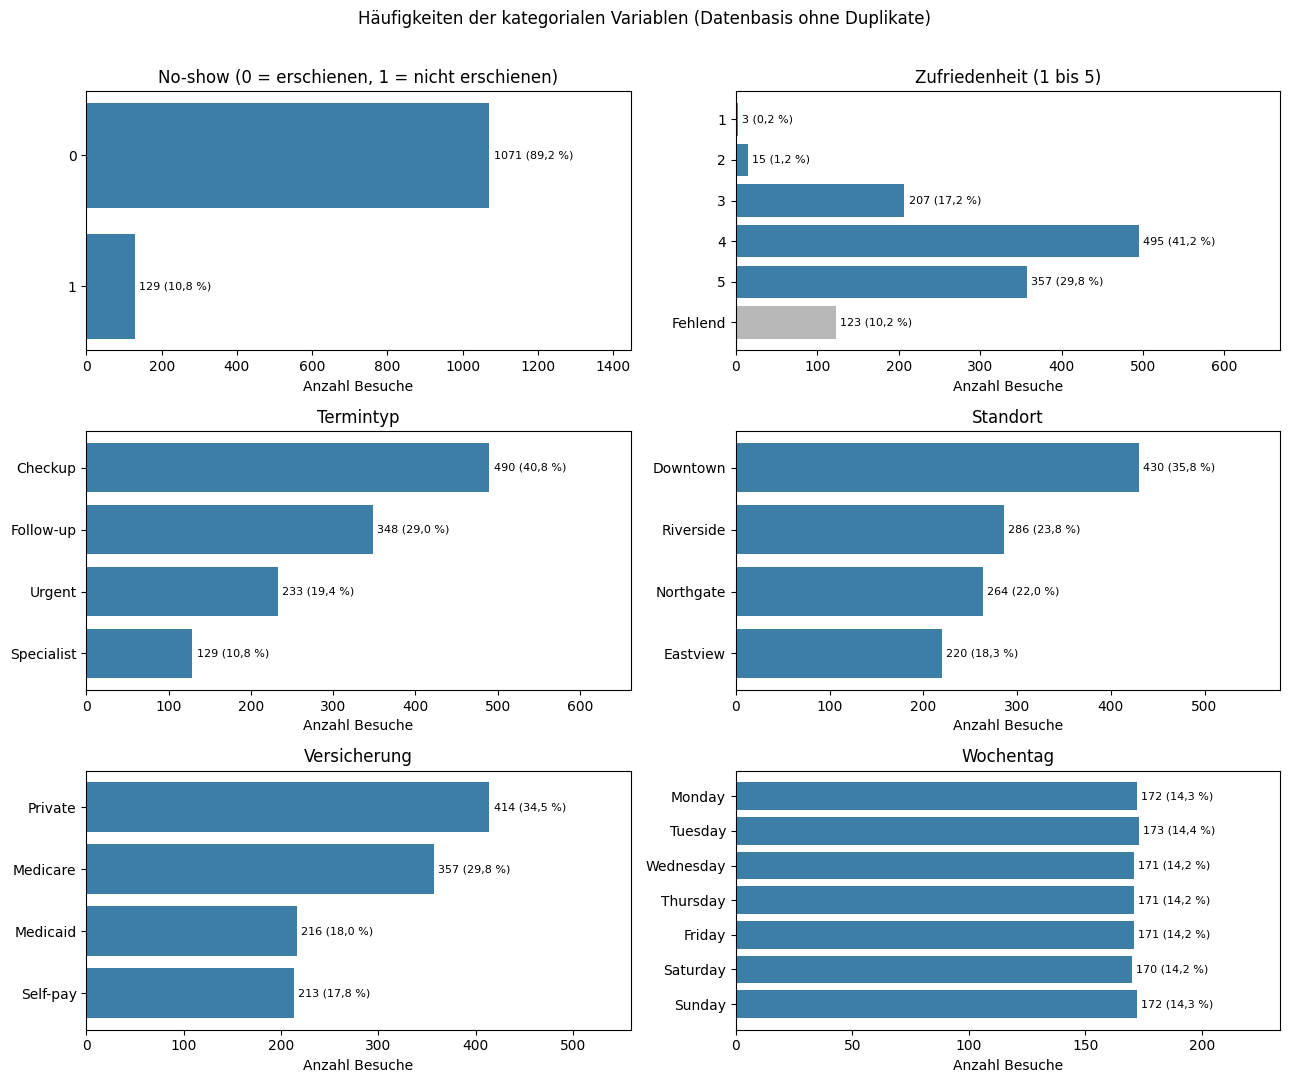

No-show (0 = erschienen, 1 = nicht erschienen): {'0': 89.2, '1': 10.8} (Anteile in %)
Zufriedenheit (1 bis 5): {'1': 0.2, '2': 1.2, '3': 17.2, '4': 41.2, '5': 29.8, 'Fehlend': 10.2} (Anteile in %)
Standort: {'Downtown': 35.8, 'Riverside': 23.8, 'Northgate': 22.0, 'Eastview': 18.3} (Anteile in %)
Termintyp: {'Checkup': 40.8, 'Follow-up': 29.0, 'Urgent': 19.4, 'Specialist': 10.8} (Anteile in %)
Zufriedenheit 4 oder 5: 852 (71.00 %), 1 bis 3: 225 (18.75 %), fehlt: 123 (10.25 %)
Schiefe der Zufriedenheit (ohne fehlende Werte): -0.51  (negativ = linksschief)
Kernaussage: alle Zahlen stimmen mit den Daten überein.


In [5]:
# ------------------------------------------------------------
# Überblick 2: Häufigkeiten der kategorialen Variablen (Balkendiagramme, fehlende Werte als eigener Balken)
# ------------------------------------------------------------
kategoriale = [
    "no_show",
    "patient_satisfaction",
    "appointment_type",
    "clinic_site",
    "insurance_type",
    "day_of_week",
]
titel = {
    "no_show": "No-show (0 = erschienen, 1 = nicht erschienen)",
    "patient_satisfaction": "Zufriedenheit (1 bis 5)",
    "appointment_type": "Termintyp",
    "clinic_site": "Standort",
    "insurance_type": "Versicherung",
    "day_of_week": "Wochentag",
}
wochentage = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

fig, achsen = plt.subplots(3, 2, figsize=(13, 11))
anteile = {}
for ax, var in zip(achsen.flat, kategoriale):
    serie = df[var]
    if var == "patient_satisfaction":
        serie = serie.astype("Int64")  # 1..5 statt 1.0..5.0
    serie = serie.astype("string").fillna("Fehlend")
    h = serie.value_counts()
    if var == "day_of_week":
        h = h.reindex(wochentage)
    elif var in ("no_show", "patient_satisfaction"):
        h = h.sort_index(
            key=lambda s: s.map(lambda v: 99 if v == "Fehlend" else int(v))
        )
    else:
        h = h.sort_values(ascending=False)
    anteile[var] = (100 * h / len(df)).round(1)
    farben = ["#b8b8b8" if k == "Fehlend" else "#3d7ea6" for k in h.index]
    bars = ax.barh(h.index.astype(str), h.values, color=farben)
    ax.bar_label(
        bars,
        labels=[f"{n} ({100 * n / len(df):.1f} %)".replace(".", ",") for n in h.values],
        padding=3,
        fontsize=8,
    )
    ax.invert_yaxis()
    ax.set_xlim(0, h.max() * 1.35)
    ax.set_title(titel[var])
    ax.set_xlabel("Anzahl Besuche")
fig.suptitle("Häufigkeiten der kategorialen Variablen (Datenbasis ohne Duplikate)")
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()
for var in ("no_show", "patient_satisfaction", "clinic_site", "appointment_type"):
    print(
        f"{titel[var]}:",
        {k: float(v) for k, v in anteile[var].items()},
        "(Anteile in %)",
    )

# --- Prüfung der Zahlen in der Kernaussage (v11): alles wird aus den Daten neu berechnet ---
n = len(df)
zuf = df["patient_satisfaction"]
n_45, n_13, n_fehlt = (
    int((zuf >= 4).sum()),
    int(((zuf >= 1) & (zuf <= 3)).sum()),
    int(zuf.isna().sum()),
)
assert n_45 + n_13 + n_fehlt == n
print(
    f"Zufriedenheit 4 oder 5: {n_45} ({100 * n_45 / n:.2f} %), 1 bis 3: {n_13} ({100 * n_13 / n:.2f} %), fehlt: {n_fehlt} ({100 * n_fehlt / n:.2f} %)"
)
print(
    f"Schiefe der Zufriedenheit (ohne fehlende Werte): {stats.skew(zuf.dropna()):.2f}  (negativ = linksschief)"
)
assert stats.skew(zuf.dropna()) < 0  # linksschief
assert round(100 * n_45 / n, 1) == 71.0  # 71,0 %
assert (
    abs(100 * n_13 / n - 18.75) < 1e-9
)  # 18,75 % -> 18,8 % (nicht 18,6 %: das wäre die Summe gerundeter Balkenwerte)
assert (
    abs(100 * n_fehlt / n - 10.25) < 1e-9
)  # 10,25 % -> im Text 10,2 %, wie in den Diagrammbeschriftungen (Python rundet .25 auf die gerade Stelle)
rang_standort = df["clinic_site"].value_counts()
assert list(rang_standort.index[:2]) == [
    "Downtown",
    "Riverside",
]  # meiste und zweitmeiste Besuche
assert (
    round(100 * rang_standort.iloc[0] / n, 1) == 35.8
    and round(100 * rang_standort.iloc[1] / n, 1) == 23.8
)
rang_typ = df["appointment_type"].value_counts()
assert rang_typ.index[0] == "Checkup" and round(100 * rang_typ.iloc[0] / n, 1) == 40.8
assert (
    round(100 * rang_typ["Urgent"] / n, 1) == 19.4 and int(df["no_show"].sum()) == 129
)
print("Kernaussage: alle Zahlen stimmen mit den Daten überein.")

**Kernaussage:** Von 1.200 Besuchen sind 129 (10,8 %) nicht erschienen. Die Zufriedenheit ist linksschief: 71,0 % der Besuche liegen bei 4 oder 5, nur 18,8 % bei 1 bis 3, und bei 10,2 % fehlt die Angabe. Linksschief heißt: Die meisten Werte liegen bei den hohen Noten, der Ausläufer reicht nach links zu den niedrigen (die Verteilung ist rechtssteil). Downtown verzeichnet mit 35,8 % die meisten Besuche, Riverside mit 23,8 % die zweitmeisten. Der häufigste Termintyp ist Checkup (40,8 %), Urgent-Termine machen 19,4 % der Besuche aus.

## Aufgabe 1 – Fünf-Zahlen-Zusammenfassung plus Mittelwert (`visit_cost`)

**Frage:** Welche Form hat die Verteilung der Besuchskosten?
**Vorgehen:** Fünf Kennzahlen + Mittelwert, dann die Form *messen* (nicht nur ansehen): Abstände, Schiefe, Normalitätstests – und ein feines Histogramm.

In [6]:
vc = df["visit_cost"]
q0, q1, med, q3, q4 = vc.quantile([0, 0.25, 0.5, 0.75, 1])
mean = vc.mean()

print(
    pd.Series(
        {
            "Minimum": q0,
            "Q1": q1,
            "Median": med,
            "Q3": q3,
            "Maximum": q4,
            "Mittelwert": mean,
        }
    ).round(2)
)
print()
print(f"Abstand Q1 -> Median : {med - q1:7.2f}")
print(f"Abstand Median -> Q3 : {q3 - med:7.2f}")
print(f"Abstand Median -> Max: {q4 - med:7.2f}   (Median -> Min: {med - q0:.2f})")
print(f"Mittelwert - Median  : {mean - med:7.2f}")

Minimum         70.860
Q1             130.130
Median         157.280
Q3             263.730
Maximum      1,208.540
Mittelwert     190.830
dtype: float64

Abstand Q1 -> Median :   27.15
Abstand Median -> Q3 :  106.45
Abstand Median -> Max: 1051.25   (Median -> Min: 86.42)
Mittelwert - Median  :   33.55


**Was die Abstände sagen:** Bei einer symmetrischen Verteilung wären Q1→Median und Median→Q3 gleich lang und der Mittelwert läge auf dem Median. Hier ist Median→Q3 etwa viermal so lang wie Q1→Median, der Mittelwert liegt über dem Median, und das Maximum ist über 1.000 vom Median entfernt, das Minimum nur ca. 86. → **rechtsschief**.

Die grafische Einschätzung prüfen wir nun mit zwei quantitativen Schiefemaßen:
- **Bowley-Schiefe** nutzt nur die Quartile: (Q3 + Q1 − 2·Median) / (Q3 − Q1). 0 = symmetrisch, +1 = maximal rechtsschief.
- **Momenten-Schiefe** (`skew`) reagiert stark auf Extremwerte; > 1 gilt als deutlich schief.

In [7]:
bowley = (q3 + q1 - 2 * med) / (q3 - q1)
print(f"Bowley-Schiefe (Quartile)      : {bowley:.2f}")
print(f"Momenten-Schiefe (skew)        : {vc.skew():.2f}")

# Formale Normalitaetstests.  H0: die Daten stammen aus einer Normalverteilung.
w, p_sw = stats.shapiro(vc)
k2, p_dp = stats.normaltest(vc)
print(f"\nShapiro-Wilk   : W = {w:.3f}, p = {p_sw:.2g}")
print(f"D'Agostino K^2 : K2 = {k2:.1f}, p = {p_dp:.2g}")
print(
    f"-> p < {ALPHA}: Die Nullhypothese, die Daten stammten aus einer Normalverteilung, wird verworfen."
)
print(
    f"\nSchiefe nach Log-Transformation: {np.log(vc).skew():.2f}  (deutlich naeher an 0)"
)

Bowley-Schiefe (Quartile)      : 0.59
Momenten-Schiefe (skew)        : 2.49

Shapiro-Wilk   : W = 0.834, p = 1.5e-33
D'Agostino K^2 : K2 = 749.6, p = 1.7e-163
-> p < 0.05: Die Nullhypothese, die Daten stammten aus einer Normalverteilung, wird verworfen.

Schiefe nach Log-Transformation: 0.21  (deutlich naeher an 0)


> 💡 **Lernhinweis Normalitätstests:** Bei 1.200 Werten lehnen Shapiro-Wilk & Co. schon *leichte* Abweichungen ab. Hier ist die Ablehnung aber nicht nur „statistisch“, sondern auch inhaltlich klar (Schiefe 2,5). Entscheidend ist immer das Bild *plus* die Zahl.

Jetzt das Histogramm – mit **feinen Klassen (Breite 10)**. Grobe Klassen können Strukturen verstecken.

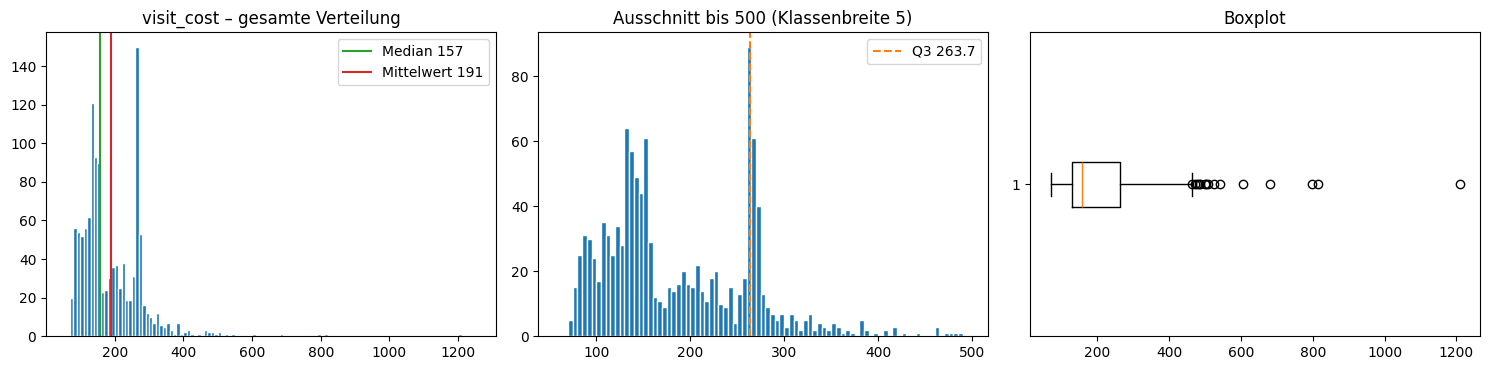

Besuche zwischen 263,73 und 300: 218 von 1200 (18.2%)
Besuche ueber 300             : 83 (6.9%)


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(vc, bins=np.arange(60, 1260, 10), edgecolor="white")
ax[0].axvline(med, color="tab:green", label=f"Median {med:.0f}")
ax[0].axvline(mean, color="tab:red", label=f"Mittelwert {mean:.0f}")
ax[0].set_title("visit_cost – gesamte Verteilung")
ax[0].legend()

ax[1].hist(vc[vc < 500], bins=np.arange(60, 500, 5), edgecolor="white")
ax[1].axvline(q3, color="tab:orange", linestyle="--", label=f"Q3 {q3:.1f}")
ax[1].set_title("Ausschnitt bis 500 (Klassenbreite 5)")
ax[1].legend()

ax[2].boxplot(vc, vert=False)
ax[2].set_title("Boxplot")
plt.tight_layout()
plt.show()

plateau = vc.between(263.73, 300)
print(
    f"Besuche zwischen 263,73 und 300: {plateau.sum()} von {len(vc)} ({plateau.mean():.1%})"
)
print(f"Besuche ueber 300             : {(vc > 300).sum()} ({(vc > 300).mean():.1%})")

**Kernaussage:** Die Besuchskosten sind rechtsschief mit einer ausgeprägten Häufung bei etwa 264 Geldeinheiten (18 % der Besuche liegen zwischen 263,73 und 300), und wenige sehr teure Besuche ziehen den Mittelwert (191) deutlich über den Median (157).

#### Antwort Aufgabe 1 – Interpretation

- **Form:** deutlich **rechtsschief** (Abstände, Bowley, Schiefe, Normalitätstests stimmen überein). Der Mittelwert liegt über dem Median, weil wenige sehr teure Besuche (bis ≈ 1.209) ihn nach oben ziehen.
- **Überraschung im feinen Histogramm:** Die Verteilung hat **keine glatte Form**. Es gibt einen großen Block bei ca. 80–160, und bei ≈ 263,7 beginnt abrupt eine zweite Häufung (nahezu ein Fünftel aller Besuche liegt zwischen 263,73 und 300). Q3 landet genau am Anfang dieser Häufung – deshalb ist der Abstand Median → Q3 so groß. Die Fünf-Punkte-Zusammenfassung bildet diese Zweiteilung nicht ab. Die Daten weisen auf eine mögliche Mischung zweier Teilgruppen hin; einen formalen Nachweis (z. B. Clusteranalyse oder Mischverteilungsmodell) haben wir nicht geführt.
- Warum es diese Häufung gibt, lässt sich mit den Daten nicht klären (siehe Aufgabe 5, Abschnitt 5g; sie hängt nicht mit Termintyp, Standort oder Versicherung zusammen). Das muss beim Datenlieferanten erfragt werden.

> 💡 **Merke:** Sechs Zahlen beschreiben die Lage und grob die Schiefe – aber nicht jede Besonderheit. Immer auch ein feines Histogramm ansehen.

## Aufgabe 2 – Welche einzelne Zahl beschreibt `visit_cost` am besten?

**Frage:** Mittelwert oder Median für die Folie des Operations-Teams?
**Prüfungen:** (1) Summeneigenschaft des Mittelwerts, (2) Robustheit gegenüber Extremwerten, (3) Unsicherheit beider Zahlen (Bootstrap-Konfidenzintervall).

Beim **Bootstrap** ziehen wir 5.000-mal mit Zurücklegen eine Zufallsstichprobe gleicher Größe aus unseren Daten und berechnen jedes Mal die Kennzahl. Die mittleren 95 % dieser Werte zeigen, wie stark die Kennzahl bei einer anderen Stichprobe schwanken würde.

In [9]:
print(f"Median     : {med:8.2f}")
print(f"Mittelwert : {mean:8.2f}")
print(
    f"\nSummenprobe: n * Mittelwert = {len(vc) * mean:,.2f}   |   Summe = {vc.sum():,.2f}"
)

# Robustheit: die 15 groessten Werte entfernen (das sind genau die Werte ueber der IQR-Grenze, siehe Aufgabe 4)
ohne_top = vc.sort_values().iloc[:-15]
print(
    f"\nOhne die 15 groessten Werte: Median {ohne_top.median():.2f} (vorher {med:.2f}), "
    f"Mittelwert {ohne_top.mean():.2f} (vorher {mean:.2f})"
)

ci_mean = bootstrap_ci(vc, np.mean)
ci_med = bootstrap_ci(vc, np.median)
print(
    f"\n95%-Bootstrap-KI Mittelwert: [{ci_mean[0]:.1f}, {ci_mean[1]:.1f}]   Breite {ci_mean[1]-ci_mean[0]:.1f}"
)
print(
    f"95%-Bootstrap-KI Median    : [{ci_med[0]:.1f}, {ci_med[1]:.1f}]   Breite {ci_med[1]-ci_med[0]:.1f}"
)

# Warum ist das Median-KI so breit?  Wie viele Besuche liegen rund um den Median?
print("\nAnzahl Besuche in 20er-Klassen rund um den Median:")
print(
    pd.cut(vc, [120, 140, 160, 180, 200, 220]).value_counts().sort_index().to_string()
)

# Prüfung zur Aussage "Das Median-KI ist deutlich breiter": Verhältnis der KI-Breiten
breite_mean = ci_mean[1] - ci_mean[0]
breite_med = ci_med[1] - ci_med[0]
print(
    f"\nVerhältnis der KI-Breiten (Median / Mittelwert): {breite_med / breite_mean:.2f}"
)

Median     :   157.28
Mittelwert :   190.83

Summenprobe: n * Mittelwert = 229,000.58   |   Summe = 229,000.58

Ohne die 15 groessten Werte: Median 156.38 (vorher 157.28), Mittelwert 185.60 (vorher 190.83)

95%-Bootstrap-KI Mittelwert: [186.0, 196.1]   Breite 10.1
95%-Bootstrap-KI Median    : [154.1, 173.6]   Breite 19.6

Anzahl Besuche in 20er-Klassen rund um den Median:
visit_cost
(120, 140]    182
(140, 160]    183
(160, 180]     47
(180, 200]     66
(200, 220]     62

Verhältnis der KI-Breiten (Median / Mittelwert): 1.93


#### Antwort Aufgabe 2 – Median oder Mittelwert für die Folie

**Was die Prüfungen zeigen:**
1. **Summenprobe:** n · Mittelwert ergibt exakt die Gesamtsumme. Das kann nur der Mittelwert.
2. **Robustheit:** Ohne die 15 teuersten Besuche bewegt sich der Median kaum (um ca. 0,9), der Mittelwert dagegen um ca. 5,2. Der Median reagiert also deutlich weniger empfindlich auf extreme Einzelwerte als der Mittelwert.
3. **Unsicherheit:** Hier kommt eine **Einschränkung**, die wir ohne Test nicht gesehen hätten: Das Bootstrap-Intervall des **Medians ist deutlich breiter** als das des Mittelwerts; der Median ist damit statistisch unsicherer bestimmt. Grund: Direkt oberhalb des Medians (Klasse 160–180) liegen nur wenige Besuche im Vergleich zur Klasse davor (siehe Zählung oben; Lücke zwischen den beiden Blöcken aus Aufgabe 1) – kleine Änderungen in der Stichprobe lassen den Median daher „springen“.

**Entscheidung: Für die Präsentationsfolie verwenden wir den Median (ca. 157)**, da er den *typischen* Besuch trotz extremer Einzelwerte besser beschreibt (Entfernen der 15 größten Werte verschiebt ihn nur um ca. 0,9, den Mittelwert um ca. 5,2). **Einschränkung:** Unempfindlich gegenüber Extremwerten heißt nicht sicher bestimmt – wegen der Lücke bei 160–180 ist der Median selbst *unsicherer*; sein Bootstrap-Intervall ist etwa doppelt so breit wie das des Mittelwerts (Verhältnis siehe letzte Ausgabezeile oben). Zusätzlich empfehle ich auf der Folie das **Quartilsintervall** („die mittleren 50 % der Besuche kosten zwischen ca. 130 und 264“), weil eine einzelne Zahl hier die Zweigipfligkeit nicht ausdrücken kann.

**Frage, für die der verworfene Mittelwert richtig wäre:** *„Wie hoch sind die Gesamtkosten des Quartals?“* bzw. *„Welches Budget brauchen wir für N solcher Besuche?“* – nur Mittelwert × Anzahl ergibt die Gesamtsumme.

## Aufgabe 3 – Zusammenhänge: quantitativ und kategorial

### 3a) `wait_time_min` ↔ `patient_satisfaction` (zwei quantitative Variablen)

**Hypothesen:** H₀: Es gibt keinen (monotonen/linearen) Zusammenhang (ρ = 0). H₁: Es gibt einen (ρ ≠ 0). α = 0,05.

**Entscheidung vor der Berechnung – fehlende Werte:** `patient_satisfaction` fehlt bei 123 Zeilen. Ein Korrelationskoeffizient braucht beide Werte; wir verwenden **paarweisen Ausschluss** (nur Zeilen, in denen beide Variablen vorhanden sind). Mittelwert-Imputation würde die Streuung künstlich verkleinern und die Korrelation Richtung 0 ziehen. Ob die Lücken die Aussage verzerren, prüfen wir weiter unten (Subgruppen) und in Aufgabe 5.

**Voraussetzungen prüfen:** Pearson verlangt (1) metrische Daten, (2) ungefähr linearen Zusammenhang, (3) keine starken Ausreißer, (4) für Tests/KI annähernd normalverteilte Variablen. Spearman verlangt nur eine Rangordnung und einen monotonen Zusammenhang.

In [10]:
pair = df[["wait_time_min", "patient_satisfaction"]].dropna()
print("Verwendete Zeilen:", len(pair), "von", len(df))

print("\n(1) Skala der Zufriedenheit:")
print(df.patient_satisfaction.value_counts().sort_index().to_string())
print(
    "-> nur 5 ganzzahlige Stufen: ordinal; Spearman ist angemessener, Pearson nur als Zusatz."
)

print("\n(4) Normalverteilung?")
for c in ["wait_time_min", "patient_satisfaction"]:
    w, p = stats.shapiro(pair[c])
    print(f"   {c:22s} Schiefe {pair[c].skew():5.2f}   Shapiro p = {p:.2g}")
print("-> beide Variablen nicht normalverteilt (Wartezeit rechtsschief).")

Verwendete Zeilen: 1077 von 1200

(1) Skala der Zufriedenheit:
patient_satisfaction
1.000      3
2.000     15
3.000    207
4.000    495
5.000    357
-> nur 5 ganzzahlige Stufen: ordinal; Spearman ist angemessener, Pearson nur als Zusatz.

(4) Normalverteilung?
   wait_time_min          Schiefe  1.28   Shapiro p = 7.7e-24
   patient_satisfaction   Schiefe -0.51   Shapiro p = 1.2e-32
-> beide Variablen nicht normalverteilt (Wartezeit rechtsschief).


               mean  count
wait_time_min             
(0, 5]        4.600    127
(5, 10]       4.350    265
(10, 15]      4.100    262
(15, 20]      3.940    207
(20, 30]      3.730    147
(30, 80]      3.520     69


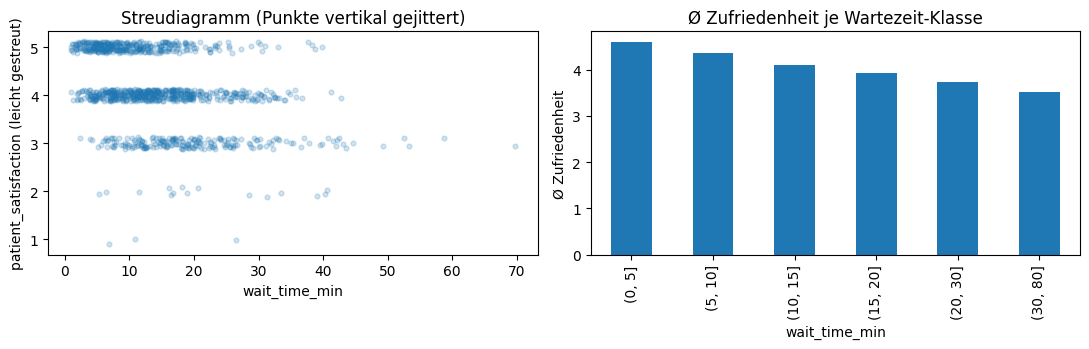

In [11]:
# (2) und (3): Linearitaet und Ausreisser -> Bild
klassen = pd.cut(pair.wait_time_min, [0, 5, 10, 15, 20, 30, 80])
mittel = pair.groupby(klassen, observed=True).patient_satisfaction.agg(
    ["mean", "count"]
)
print(mittel.round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].scatter(
    pair.wait_time_min,
    pair.patient_satisfaction + rng.uniform(-0.12, 0.12, len(pair)),
    alpha=0.2,
    s=12,
)
ax[0].set_xlabel("wait_time_min")
ax[0].set_ylabel("patient_satisfaction (leicht gestreut)")
ax[0].set_title("Streudiagramm (Punkte vertikal gejittert)")
mittel["mean"].plot.bar(ax=ax[1])
ax[1].set_title("Ø Zufriedenheit je Wartezeit-Klasse")
ax[1].set_ylabel("Ø Zufriedenheit")
plt.tight_layout()
plt.show()

**Kernaussage:** Bei längerer Wartezeit ist die durchschnittliche Zufriedenheit niedriger – von 4,60 bei höchstens 5 Minuten auf 3,52 bei über 30 Minuten –, wobei die Einzelwerte stark streuen.

In [12]:
# Zusammenhang berechnen: drei Masse + Konfidenzintervall + Kontrolle mit log(Wartezeit)
r, p_r = stats.pearsonr(pair.wait_time_min, pair.patient_satisfaction)
rho, p_rho = stats.spearmanr(pair.wait_time_min, pair.patient_satisfaction)
tau, p_tau = stats.kendalltau(pair.wait_time_min, pair.patient_satisfaction)
r_log, p_log = stats.pearsonr(np.log(pair.wait_time_min), pair.patient_satisfaction)
lo, hi = pearson_ci(r, len(pair))

print(
    f"Pearson  r     = {r:.3f}   95%-KI [{lo:.3f}, {hi:.3f}]   p = {p_r:.2g}   r^2 = {r**2:.3f}"
)
print(f"Spearman rho   = {rho:.3f}   p = {p_rho:.2g}")
print(f"Kendall  tau-b = {tau:.3f}   p = {p_tau:.2g}")
print(f"Pearson mit log(Wartezeit) = {r_log:.3f}   p = {p_log:.2g}")

# Prüfung (v11): Auch die schwächste mit den Daten vereinbare Korrelation (KI-Grenze nahe 0) ist noch mäßig
print(
    f"Schwächste mit den Daten vereinbare Korrelation: |r| = {abs(hi):.3f}  ->  {'mindestens mäßig (>= 0,3)' if abs(hi) >= 0.3 else 'schwach (< 0,3)'}"
)
assert lo < hi < 0 and abs(hi) >= 0.3

Pearson  r     = -0.388   95%-KI [-0.438, -0.336]   p = 4.4e-40   r^2 = 0.151
Spearman rho   = -0.403   p = 2.5e-43
Kendall  tau-b = -0.317   p = 2.8e-41
Pearson mit log(Wartezeit) = -0.392   p = 8.4e-41
Schwächste mit den Daten vereinbare Korrelation: |r| = 0.336  ->  mindestens mäßig (>= 0,3)


**Robustheit (Subgruppen):** Wir prüfen, ob der Zusammenhang in jedem Termintyp und an jedem Standort ähnlich ist. So erkennen wir, ob er nur ein Mischeffekt ist (Simpson-Paradoxon) – und ob die fehlenden Zufriedenheitswerte bei Urgent das Ergebnis verfälschen könnten.

In [13]:
def korr_je_gruppe(spalte):
    zeilen = []
    for name, g in df.groupby(spalte):
        q = g[["wait_time_min", "patient_satisfaction"]].dropna()
        zeilen.append(
            {
                spalte: name,
                "n Paare": len(q),
                "Pearson r": stats.pearsonr(q.wait_time_min, q.patient_satisfaction)[0],
                "Spearman rho": stats.spearmanr(
                    q.wait_time_min, q.patient_satisfaction
                )[0],
            }
        )
    return pd.DataFrame(zeilen).set_index(spalte)


print(korr_je_gruppe("appointment_type").round(3), "\n")
print(korr_je_gruppe("clinic_site").round(3))

# Standortunterschiede in Wartezeit und Zufriedenheit
print("\nKennzahlen je Standort:")
je_standort = df.groupby("clinic_site").agg(
    n=("visit_id", "size"),
    wartezeit_median=("wait_time_min", "median"),
    wartezeit_mittel=("wait_time_min", "mean"),
    zufriedenheit_mittel=("patient_satisfaction", "mean"),
)
print(je_standort.round(2))

h_w, p_w = stats.kruskal(
    *[g.wait_time_min.values for _, g in df.groupby("clinic_site")]
)
h_s, p_s = stats.kruskal(
    *[g.patient_satisfaction.dropna().values for _, g in df.groupby("clinic_site")]
)
print(f"\nKruskal-Wallis Wartezeit ~ Standort    : H = {h_w:.1f}, p = {p_w:.2g}")
print(f"Kruskal-Wallis Zufriedenheit ~ Standort: H = {h_s:.1f}, p = {p_s:.2g}")

ohne_rs = df[df.clinic_site != "Riverside"][
    ["wait_time_min", "patient_satisfaction"]
].dropna()
print(
    f"\nOhne Riverside: Spearman rho = {stats.spearmanr(ohne_rs.wait_time_min, ohne_rs.patient_satisfaction)[0]:.3f}"
)

                  n Paare  Pearson r  Spearman rho
appointment_type                                  
Checkup               464     -0.418        -0.436
Follow-up             331     -0.340        -0.381
Specialist            123     -0.454        -0.424
Urgent                159     -0.351        -0.348 

             n Paare  Pearson r  Spearman rho
clinic_site                                  
Downtown         387     -0.399        -0.421
Eastview         197     -0.296        -0.297
Northgate        239     -0.425        -0.441
Riverside        254     -0.253        -0.231

Kennzahlen je Standort:
               n  wartezeit_median  wartezeit_mittel  zufriedenheit_mittel
clinic_site                                                               
Downtown     430            10.400            12.180                 4.190
Eastview     220            11.260            12.620                 4.190
Northgate    264            10.240            11.950                 4.150
Riverside    286

#### Antwort Aufgabe 3a – Interpretation

- **Richtung und Stärke:** Alle Maße sind negativ und liegen eng beieinander (Pearson ≈ −0,39; Spearman ≈ −0,40; Kendall ≈ −0,32). Das 95 %-KI für r (ca. −0,44 bis −0,34) enthält die 0 nicht, und selbst die schwächste mit den Daten vereinbare Korrelation (−0,34) liegt im Betrag noch über 0,3, wäre also ebenfalls mäßig; Der p-Wert liegt deutlich unter dem Signifikanzniveau von α = 0,05; die Nullhypothese (kein Zusammenhang) wird daher verworfen, der Zusammenhang ist statistisch signifikant. Nach der üblichen Faustregel ist der Zusammenhang **mäßig**: Mit längerer Wartezeit geht eine niedrigere Zufriedenheit einher. r² ≈ 0,15: etwa 15 % der Streuung der Zufriedenheit hängen linear mit der Wartezeit zusammen.
- **Linearität/Ausreißer:** Die Klassenmittel sinken gleichmäßig von ≈ 4,6 (Wartezeit bis 5 Minuten) auf ≈ 3,5 (über 30 Minuten) – der Verlauf ist grob linear/monoton, einzelne Ausreißer bestimmen das Ergebnis nicht.
- **Hauptaussage und Robustheit:** Die Aufgabe verlangt die Korrelation zweier quantitativer Variablen; wir berichten deshalb **Pearson r mit 95 %-Konfidenzintervall** als Hauptaussage (die fünfstufige Zufriedenheit wird dabei näherungsweise als metrisch aufgefasst). Weil die Zufriedenheit eigentlich ordinal und die Wartezeit schief ist, prüfen wir mit Spearman, Kendall und Pearson mit log(Wartezeit) nach: Alle liefern praktisch dasselbe Bild. Das Ergebnis erweist sich damit gegenüber unterschiedlichen Verfahren und Annahmen als stabil.
- **Subgruppen:** In jedem Termintyp und an jedem Standort ist der Zusammenhang negativ (ca. −0,23 bis −0,45). Er ist also kein reiner Mischeffekt. Bei **Urgent** (die meisten fehlenden Werte) ist er mit ca. −0,35 ähnlich groß wie sonst – die Lücken verändern die Aussage hier nicht erkennbar.
- **Neuer Befund:** **Riverside** hat deutlich längere Wartezeiten (Median ca. 19 Minuten gegenüber ca. 10–11 an den anderen drei Standorten) und eine niedrigere mittlere Zufriedenheit (ca. 3,9 gegenüber ca. 4,2). Beide Unterschiede sind laut Kruskal-Wallis statistisch signifikant. Dieser Befund ist für operative Entscheidungen besonders relevant, da Riverside sowohl längere Wartezeiten als auch eine geringere Zufriedenheit aufweist.
- **Grenze:** Aus der beobachteten Korrelation allein lässt sich keine Ursache-Wirkungs-Beziehung ableiten; beide Variablen könnten gemeinsam von weiteren Einflussfaktoren (z. B. Überlastung) abhängen.

### 3b) `appointment_type` ↔ `no_show` (zwei kategoriale Variablen)

Ein Korrelationskoeffizient braucht zwei numerische Variablen. Für zwei Kategorien verwenden wir Kreuztabelle + **Chi-Quadrat-Unabhängigkeitstest**.

**Hypothesen:** H₀: Termintyp und No-show sind unabhängig (die No-show-Rate ist in allen Typen gleich). H₁: Sie sind nicht unabhängig. α = 0,05.

**Voraussetzungen:** (1) Häufigkeiten statt Anteile, (2) jede Beobachtung nur einmal in der Tabelle, (3) **erwartete** Häufigkeiten ≥ 5 in (fast) allen Zellen, (4) unabhängige Beobachtungen.

In [14]:
ct = pd.crosstab(df.appointment_type, df.no_show)
ct.columns = ["erschienen (0)", "no-show (1)"]
ct["no-show-Rate"] = ct["no-show (1)"] / (ct["erschienen (0)"] + ct["no-show (1)"])
print(ct.round(3), "\n")

roh = pd.crosstab(df.appointment_type, df.no_show)
chi2, p, dof, erwartet = stats.chi2_contingency(roh)
erw = pd.DataFrame(
    erwartet, index=roh.index, columns=["erwartet erschienen", "erwartet no-show"]
)
print(erw.round(1))
print(
    f"\nVoraussetzung (3): kleinste erwartete Haeufigkeit = {erwartet.min():.1f}  ->  {'erfuellt (>= 5)' if erwartet.min() >= 5 else 'NICHT erfuellt'}"
)

# Voraussetzung (4): Unabhaengigkeit - wie oft kommt ein Patient mehrfach vor?
besuche_je_patient = df.drop_duplicates().patient_id.value_counts()
print(
    f"Patienten: {df.patient_id.nunique()}, davon mit mehr als einer Zeile (nach Entfernen exakter Duplikate): {(besuche_je_patient > 1).sum()}"
)

                  erschienen (0)  no-show (1)  no-show-Rate
appointment_type                                           
Checkup                      445           45         0.092
Follow-up                    313           35         0.101
Specialist                   120            9         0.070
Urgent                       193           40         0.172 

                  erwartet erschienen  erwartet no-show
appointment_type                                       
Checkup                       437.300            52.700
Follow-up                     310.600            37.400
Specialist                    115.100            13.900
Urgent                        208.000            25.000

Voraussetzung (3): kleinste erwartete Haeufigkeit = 13.9  ->  erfuellt (>= 5)
Patienten: 1180, davon mit mehr als einer Zeile (nach Entfernen exakter Duplikate): 20


In [15]:
v = cramers_v(roh)
print(f"chi2 = {chi2:.2f}, Freiheitsgrade = {dof}, p = {p:.4f}")
print(
    f"Cramers V = {v:.3f}   (Faustregel bei 2 Spalten: 0,1 klein | 0,3 mittel | 0,5 gross)"
)

# Welche Zellen weichen ab?  Standardisierte Residuen (Beobachtet - Erwartet) / Wurzel(Erwartet)
res = (roh.values - erwartet) / np.sqrt(erwartet)
res = pd.DataFrame(res, index=roh.index, columns=["erschienen", "no-show"])
schwelle_einzeln = stats.norm.isf(ALPHA / 2)  # 1,96
schwelle_bonf = stats.norm.isf(ALPHA / 8 / 2)  # 8 Zellen -> Bonferroni
print("\nStandardisierte Residuen:")
print(res.round(2))
print(
    f"\nSchwelle ohne Korrektur: |z| > {schwelle_einzeln:.2f};  mit Bonferroni-Korrektur fuer 8 Zellen: |z| > {schwelle_bonf:.2f}"
)

chi2 = 13.34, Freiheitsgrade = 3, p = 0.0040
Cramers V = 0.105   (Faustregel bei 2 Spalten: 0,1 klein | 0,3 mittel | 0,5 gross)

Standardisierte Residuen:
                  erschienen  no-show
appointment_type                     
Checkup                0.370   -1.060
Follow-up              0.140   -0.390
Specialist             0.450   -1.310
Urgent                -1.040    2.990

Schwelle ohne Korrektur: |z| > 1.96;  mit Bonferroni-Korrektur fuer 8 Zellen: |z| > 2.73


Die Residuen sind eine **Mehrfach-Auswertung** (8 Zellen gleichzeitig). Bei vielen gleichzeitigen Tests fällt irgendwo zufällig etwas „auffällig“ aus; die **Bonferroni-Korrektur** verschärft deshalb die Schwelle. Nun der Folgetest: Ist wirklich nur *Urgent* anders?

In [16]:
# Folgetest 1: Urgent gegen alle anderen (2 x 2)
urg = df.appointment_type == "Urgent"
t22 = pd.crosstab(
    urg, df.no_show
).values  # Zeilen: nicht-Urgent, Urgent; Spalten: erschienen, no-show
chi_ohne, p_ohne, _, _ = stats.chi2_contingency(t22, correction=False)
chi_mit, p_mit, _, _ = stats.chi2_contingency(t22, correction=True)  # Yates-Korrektur
_, p_fisher = stats.fisher_exact(t22)

a, b, c_, d = t22[1, 1], t22[1, 0], t22[0, 1], t22[0, 0]
or_ = (a * d) / (b * c_)
se = np.sqrt(1 / a + 1 / b + 1 / c_ + 1 / d)
or_lo, or_hi = np.exp(np.log(or_) + np.array([-1, 1]) * stats.norm.ppf(0.975) * se)

print(f"No-show-Rate Urgent: {a/(a+b):.1%}   uebrige Typen: {c_/(c_+d):.1%}")
print(f"chi2 ohne Korrektur: {chi_ohne:.2f}, p = {p_ohne:.4f}")
print(f"chi2 mit Yates      : {chi_mit:.2f}, p = {p_mit:.4f}")
print(f"Fisher exakt        : p = {p_fisher:.4f}")
print(f"Odds Ratio = {or_:.2f}   95%-KI [{or_lo:.2f}, {or_hi:.2f}]")

# Folgetest 2: Unterscheiden sich die drei uebrigen Typen untereinander?
rest = df[df.appointment_type != "Urgent"]
chi_r, p_r2, dof_r, _ = stats.chi2_contingency(
    pd.crosstab(rest.appointment_type, rest.no_show)
)
print(
    f"\nNur Checkup/Follow-up/Specialist: chi2 = {chi_r:.2f}, df = {dof_r}, p = {p_r2:.3f}"
)

# Robustheit (Unabhaengigkeit): pro Patient nur der erste Besuch
erster = (
    df.drop_duplicates().sort_values("appointment_date").drop_duplicates("patient_id")
)
chi_e, p_e, dof_e, _ = stats.chi2_contingency(
    pd.crosstab(erster.appointment_type, erster.no_show)
)
print(
    f"\nNur 1 Besuch je Patient (n={len(erster)}): chi2 = {chi_e:.2f}, df = {dof_e}, p = {p_e:.4f}, V = {cramers_v(pd.crosstab(erster.appointment_type, erster.no_show)):.3f}"
)

No-show-Rate Urgent: 17.2%   uebrige Typen: 9.2%
chi2 ohne Korrektur: 12.41, p = 0.0004
chi2 mit Yates      : 11.59, p = 0.0007
Fisher exakt        : p = 0.0009
Odds Ratio = 2.04   95%-KI [1.36, 3.06]

Nur Checkup/Follow-up/Specialist: chi2 = 1.07, df = 2, p = 0.586

Nur 1 Besuch je Patient (n=1180): chi2 = 12.16, df = 3, p = 0.0069, V = 0.102


#### Antwort Aufgabe 3b – Interpretation

- **Test:** χ² ≈ 13,3 bei 3 Freiheitsgraden, p ≈ 0,004 liegt deutlich unter α = 0,05; H₀ (Unabhängigkeit) wird verworfen, der Zusammenhang ist statistisch signifikant. Das ist eine Aussage über die Grundgesamtheit hinter den 1.200 Besuchen: Termintyp und No-show sind dort nicht unabhängig. Alle erwarteten Häufigkeiten liegen über 5 (kleinster Wert ≈ 13,9), die Voraussetzung ist erfüllt.
- **Stärke:** Cramérs V ≈ 0,105 → **schwacher** Zusammenhang (Grenze für „klein“ ist 0,1). Der p-Wert allein hätte „stark“ suggeriert; die Effektstärke relativiert das. (Ein kleiner p-Wert bedeutet *nicht* einen starken Zusammenhang.)
- **Wo liegt die Abweichung?** Nur bei **Urgent**: 40 no-shows statt erwarteter ≈ 25; das Residuum (≈ 3,0) übersteigt sogar die strenge Bonferroni-Schwelle (≈ 2,7). Alle anderen Zellen sind unauffällig.
- **Folgetests:** Urgent hat eine No-show-Rate von ≈ 17 % gegenüber ≈ 9 % bei den übrigen Terminen; das Odds Ratio ≈ 2,0 (95 %-KI ca. 1,4 bis 3,1; der Wert 1 = „kein Unterschied“ liegt nicht darin). Mit und ohne Yates-Korrektur sowie nach Fisher kommt dasselbe heraus. Die **drei übrigen Typen unterscheiden sich untereinander nicht** (p ≈ 0,6).
- **Alltagssprache:** Wer einen dringenden Termin hat, erscheint etwa doppelt so oft nicht (im Chancenverhältnis); bei Checkup, Follow-up und Specialist ist das Verhalten ähnlich.
- **Unabhängigkeit:** Die 1.200 Besuche stammen von 1.180 Patienten, nur 20 Patienten kommen mehrfach vor (siehe Aufgabe 5, Duplikate). Nimmt man pro Patient nur einen Besuch, bleibt das Ergebnis signifikant (p ≈ 0,007). Die Aussage ist also robust.

## Aufgabe 4 – Ausreißer in drei Variablen

**Regel (vor der Anwendung festgelegt):** Tukey-Regel mit **1,5 × IQR** – markiert wird, was unter `Q1 − 1,5·IQR` oder über `Q3 + 1,5·IQR` liegt. „Das sieht zu groß aus“ wäre nicht reproduzierbar.

**Wichtig:** Die Regel *markiert* nur ungewöhnliche Werte. Ob sie **Fehler**, **echte Extremwerte** oder der **normale Rand** einer breiten Verteilung sind, entscheiden wir danach mit inhaltlichen Prüfungen.

In [17]:
spalten = ["actual_duration_min", "visit_cost", "wait_time_min"]
zeilen = []
for c in spalten:
    flag, lo, hi = iqr_flags(df[c])
    zeilen.append(
        {
            "Variable": c,
            "untere Grenze": lo,
            "obere Grenze": hi,
            "markiert": int(flag.sum()),
            "Anteil %": 100 * flag.mean(),
            "davon unten": int((df[c] < lo).sum()),
            "davon oben": int((df[c] > hi).sum()),
        }
    )
pd.DataFrame(zeilen).set_index("Variable").round(2)

,untere Grenze,obere Grenze,markiert,Anteil %,davon unten,davon oben
Variable,,,,,,
actual_duration_min,-5.990,51.280,17,1.420,0,17
visit_cost,-70.260,464.130,15,1.250,0,15
wait_time_min,-9.500,35.770,32,2.670,0,32


**Sensitivität:** Die Zahl der „Ausreißer“ hängt von der Regel ab. Wir vergleichen fünf gängige Regeln, damit klar wird, wie robust unsere Aussage ist:
- **1,5 × IQR** (Standard), **3 × IQR** (nur „weit draußen“),
- **|z| > 3** (Abstand vom Mittelwert in Standardabweichungen – selbst von Ausreißern beeinflusst),
- **modifizierter z-Wert > 3,5** (nutzt Median und MAD, robuster),
- **1,5 × IQR auf logarithmierten Werten** (sinnvoll bei rechtsschiefen Daten).

In [18]:
def regeln_vergleich(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    mad = np.median(np.abs(s - s.median()))
    mod_z = 0.6745 * (s - s.median()) / mad
    ls = np.log(s)
    flag_log, _, _ = iqr_flags(ls)
    return {
        "1,5 x IQR": int(iqr_flags(s, 1.5)[0].sum()),
        "3 x IQR": int(iqr_flags(s, 3.0)[0].sum()),
        "|z| > 3": int((np.abs(stats.zscore(s)) > 3).sum()),
        "mod. z > 3,5": int((mod_z.abs() > 3.5).sum()),
        "log + 1,5 x IQR": int(flag_log.sum()),
        "Schiefe roh": s.skew(),
        "Schiefe log": ls.skew(),
    }


pd.DataFrame({c: regeln_vergleich(df[c]) for c in spalten}).T.round(2)

,"1,5 x IQR",3 x IQR,|z| > 3,"mod. z > 3,5","log + 1,5 x IQR",Schiefe roh,Schiefe log
actual_duration_min,17.000,14.000,13.000,15.000,36.000,9.630,0.780
visit_cost,15.000,4.000,16.000,19.000,3.000,2.490,0.210
wait_time_min,32.000,3.000,16.000,18.000,17.000,1.290,-0.610


### 4a) `actual_duration_min` – was wurde markiert?
Ein Wert allein sagt wenig; wir vergleichen jeden Wert mit der **geplanten Dauer** desselben Besuchs (Verhältnis ist/geplant) und fragen, ob die Größenordnung physisch plausibel ist.

visit_id appointment_type  scheduled_duration_min  actual_duration_min  ratio
 R-00666          Checkup                      30              399.000 13.300
 R-00313          Checkup                      30              324.000 10.800
 R-00960        Follow-up                      30              306.000 10.200
 R-00965          Checkup                      60              600.000 10.000
 R-01105          Checkup                      45              418.500  9.300
 R-00202          Checkup                      45              391.500  8.700
 R-00797        Follow-up                      60              456.000  7.600
 R-01144          Checkup                      45              333.000  7.400
 R-00426          Checkup                      30              204.000  6.800
 R-00633          Checkup                      60              396.000  6.600
 R-00149           Urgent                      60              384.000  6.400
 R-00828           Urgent                      60              3

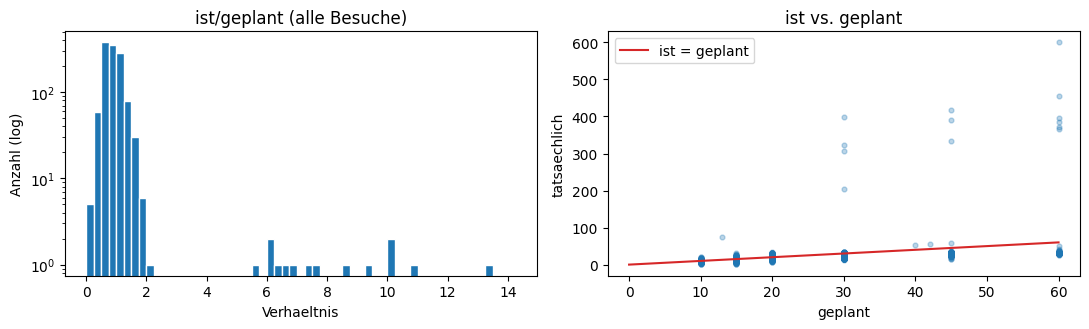

In [19]:
df["ratio"] = df.actual_duration_min / df.scheduled_duration_min
flag_d, lo_d, hi_d = iqr_flags(df.actual_duration_min)

markiert = df.loc[
    flag_d,
    [
        "visit_id",
        "appointment_type",
        "scheduled_duration_min",
        "actual_duration_min",
        "ratio",
    ],
]
print(markiert.sort_values("ratio", ascending=False).round(2).to_string(index=False))

nicht = df.loc[~flag_d, "ratio"]
print(
    f"\nNicht markierte Besuche: Verhaeltnis Median {nicht.median():.2f}, Maximum {nicht.max():.2f}"
)

# Gibt es eine natuerliche Luecke?  Verteilung des Verhaeltnisses ist/geplant ueber alle Besuche
klassen = [0, 0.5, 1, 1.5, 2, 3, 5, 10, 15]
print("\nVerteilung des Verhaeltnisses ist/geplant (alle Besuche):")
print(pd.cut(df.ratio, klassen, right=False).value_counts().sort_index().to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(df.ratio, bins=np.arange(0, 14.5, 0.25), edgecolor="white")
ax[0].set_title("ist/geplant (alle Besuche)")
ax[0].set_xlabel("Verhaeltnis")
ax[0].set_yscale("log")
ax[0].set_ylabel("Anzahl (log)")
ax[1].scatter(df.scheduled_duration_min, df.actual_duration_min, alpha=0.3, s=12)
ax[1].plot([0, 60], [0, 60], color="tab:red", label="ist = geplant")
ax[1].legend()
ax[1].set_xlabel("geplant")
ax[1].set_ylabel("tatsaechlich")
ax[1].set_title("ist vs. geplant")
plt.tight_layout()
plt.show()

**Kernaussage:** Fast alle Besuche dauern höchstens gut das Doppelte der geplanten Zeit, doch 14 Besuche liegen beim 5,7- bis 13-Fachen und es gibt keinen einzigen Besuch dazwischen – das spricht für Fehler und nicht für echte Extremwerte.

#### Antwort Aufgabe 4a – Urteil: überwiegend Fehler
- Die Regel markiert 17 Werte (Grenze ≈ 51 Minuten). **14 davon liegen beim 5,7- bis 13-Fachen der geplanten Dauer** (bis zu 600 Minuten bei 60 geplanten). Ein ambulanter Besuch von 10 Stunden ist physisch nicht plausibel.
- **Prüfung:** Zwischen dem 2,1-Fachen und dem 5,7-Fachen gibt es **keinen einzigen Besuch**; alle anderen Besuche liegen im Verhältnis bei höchstens ≈ 2,1 (Median 0,87). Die 14 Werte sind also keine Fortsetzung der normalen Streuung, sondern eine **abgesetzte Gruppe** – das spricht für einen systematischen Fehler (z. B. Einheitenverwechslung oder Eingabefehler; die Probe dazu folgt direkt unten in 4a-2).
- Die übrigen **3 Markierten** liegen bei nur ≈ 1,3-fachen der Planung (52–58 Minuten) – das ist ein normaler, nur wegen der schmalen Verteilung markierter Rand.
- **Grenze der Aussage:** „Fehler“ ist hier eine **begründete Vermutung**, kein Beweis. Die Schwelle (5 × geplant) haben wir *nach* Ansicht der Daten gewählt, weil dort die Lücke liegt. Bestätigen kann das nur der Datenlieferant.
- **Sensitivität:** Je nach Regel schwankt die Zahl (13–17 bei den Standardregeln); die Kernaussage (die 13–14 Extremwerte sind markiert) bleibt. Die Log-Regel markiert mit 36 Werten deutlich mehr; bei dieser Variable ist sie weniger aussagekräftig, weil hier nicht Schiefe, sondern eine abgesetzte Fehlergruppe das Problem ist.

### 4a-2) Probe: Passt ein Dezimalfehler (Faktor 10)?
In 4a steht, die 14 Werte könnten ein Einheiten- oder Eingabefehler sein. Das prüfen wir jetzt, statt es nur zu behaupten.

**Hypothese:** Bei den 14 abgesetzten Werten ist die Dezimalstelle verrutscht, sie sind um den Faktor 10 zu groß erfasst.
**Vorhersage:** Teilt man das Verhältnis ist/geplant durch 10, muss es aussehen wie bei den normalen Besuchen (nicht markierte Besuche: Median ≈ 0,87, Bereich ≈ 0,18 bis 2,08).
**Kontrollen:** (1) Gilt das auch für andere Faktoren? Wenn viele Faktoren passen würden, wäre „10“ nichts Besonderes. (2) Die 3 mild markierten Werte (Verhältnis ≈ 1,3) lagen schon vorher im Normalbereich; nach „/10“ dürften sie *nicht* mehr passen.

Zum Vergleich der Verteilungen nutzen wir den **Kolmogorov-Smirnov-Test** (H₀: beide Gruppen stammen aus derselben Verteilung; α = 0,05). Hier ist ein **großes p das gewünschte Ergebnis**: es heißt „nicht unterscheidbar von normalen Besuchen“. Das ist ein Plausibilitätscheck, kein Beweis.

In [20]:
# 4a-2) Probe: Faktor-Hypothese für die 14 abgesetzten Dauerwerte
verdacht = df.ratio > 5  # die 14 abgesetzten Werte (Schwelle aus 4a)
mild = flag_d & ~verdacht  # die 3 mild markierten Werte (Verhältnis ca. 1,3)
normal = df.loc[~flag_d, "ratio"]  # Verhältnis ist/geplant der nicht markierten Besuche
print(f"verdacht: {verdacht.sum()} Werte | mild: {mild.sum()} Werte")
print(
    f"Normale Besuche: Median {normal.median():.2f}, Bereich {normal.min():.2f} bis {normal.max():.2f}\n"
)

# (1) Welche Faktoren machen die 14 Werte 'normal'?  Verhältnis / Faktor gegen normale Besuche testen
zeilen = []
for f in [5, 6, 7, 8, 9, 10, 11, 12, 14, 20, 60]:
    r = df.loc[verdacht, "ratio"] / f  # Wert / Faktor, relativ zur Planung
    ks = stats.ks_2samp(r, normal)  # Zwei-Stichproben-KS-Test
    zeilen.append(
        {
            "Faktor": f,
            "Median Verhältnis": r.median(),
            "im Bereich normaler Besuche (von 14)": int(
                ((r >= normal.min()) & (r <= normal.max())).sum()
            ),
            "KS-Statistik": ks.statistic,
            "p": ks.pvalue,
            "unterscheidbar (p < 0,05)": ks.pvalue < ALPHA,
        }
    )
print(pd.DataFrame(zeilen).set_index("Faktor").round(3).to_string())

# (2) Gegenprobe: die 3 mild markierten Werte nach '/10'
r_mild = (df.loc[mild, "actual_duration_min"] / 10) / df.loc[
    mild, "scheduled_duration_min"
]
print(
    "\nMild markierte Werte nach /10, Verhältnis ist/geplant:", r_mild.round(2).tolist()
)
print(
    "   davon im Bereich normaler Besuche:",
    int(((r_mild >= normal.min()) & (r_mild <= normal.max())).sum()),
    "von",
    mild.sum(),
)

# Konkret: die 14 Werte vor und nach /10 (Auszug)
beispiel = df.loc[
    verdacht, ["visit_id", "scheduled_duration_min", "actual_duration_min"]
].copy()
beispiel["actual / 10"] = beispiel.actual_duration_min / 10
beispiel["Verhältnis nach /10"] = (
    beispiel["actual / 10"] / beispiel.scheduled_duration_min
)
print()
print(
    beispiel.sort_values("actual_duration_min", ascending=False)
    .head(5)
    .round(2)
    .to_string(index=False)
)

verdacht: 14 Werte | mild: 3 Werte
Normale Besuche: Median 0.87, Bereich 0.18 bis 2.08

        Median Verhältnis  im Bereich normaler Besuche (von 14)  KS-Statistik     p  unterscheidbar (p < 0,05)
Faktor                                                                                                        
5                   1.500                                    12         0.844 0.000                       True
6                   1.250                                    13         0.642 0.000                       True
7                   1.071                                    14         0.445 0.005                       True
8                   0.938                                    14         0.327 0.081                      False
9                   0.833                                    14         0.197 0.592                      False
10                  0.750                                    14         0.190 0.632                      False
11                  0.68

**Ergebnis 4a-2 (Zahlen siehe Ausgabe oben):**
- **Faktor 10 passt:** Nach „/10“ liegen alle 14 Werte im Bereich normaler Besuche (Verhältnis ca. 0,57 bis 1,33), und der KS-Test kann sie nicht von normalen Besuchen unterscheiden (p ≈ 0,6). Beispiel: 600 Minuten bei 60 geplanten werden zu 60 Minuten.
- **Aber nicht nur 10:** Auch die Faktoren 9 (und knapp 8 und 11) sind nicht unterscheidbar. Die Daten sagen also „Faktor ungefähr 10“, nicht „genau 10“. Ausgeschlossen sind dagegen kleine Faktoren (5 bis 7) und der Faktor 60 (Sekunden statt Minuten, p ≈ 0 und nur 2 von 14 im Normalbereich).
- **Gegenprobe bestanden:** Die 3 mild markierten Werte liegen nach „/10“ bei ≈ 0,13 und damit *außerhalb* des Normalbereichs. Sie waren schon vorher normal (oberer Rand) und sind keine Faktor-10-Fälle.
- **Folgerung:** Die Vermutung „Dezimalfehler um den Faktor 10“ ist mit den Daten **gut vereinbar**, aber nicht bewiesen (ein Test kann eine Hypothese nur stützen). **Wir korrigieren deshalb nicht selbst**, sondern markieren weiter (`duration_suspect`, siehe 5e) und fragen beim Datenlieferanten nach (offene Frage 1).

### 4b) `visit_cost` und `wait_time_min`
Auch hier fragen wir, ob die markierten Werte eher auf Fehler oder auf echte Extremwerte hindeuten.

In [21]:
flag_v, lo_v, hi_v = iqr_flags(df.visit_cost)
flag_w, lo_w, hi_w = iqr_flags(df.wait_time_min)

print(
    f"visit_cost : {flag_v.sum()} markiert (Grenze > {hi_v:.1f}); Bereich der markierten: {df.visit_cost[flag_v].min():.1f} bis {df.visit_cost[flag_v].max():.1f}"
)
print(
    f"wait_time  : {flag_w.sum()} markiert (Grenze > {hi_w:.1f}); Bereich der markierten: {df.wait_time_min[flag_w].min():.1f} bis {df.wait_time_min[flag_w].max():.1f}"
)

print("\n--- visit_cost: Sind die markierten Werte Folgefehler der Dauer-Fehler? ---")
print("Ueberschneidung mit den 14 Dauer-Fehlern:", int((flag_v & (df.ratio > 5)).sum()))
print(
    "Median actual_duration: markierte Kosten",
    round(df.actual_duration_min[flag_v].median(), 1),
    "| alle",
    round(df.actual_duration_min.median(), 1),
)

print(
    "\nmarkierte visit_cost nach Versicherung (Anteil an allen Besuchen in Klammern):"
)
anteil_ins = df.insurance_type.value_counts(normalize=True)
for k, n in df.loc[flag_v, "insurance_type"].value_counts().items():
    print(
        f"   {k:9s} {n:2d} von {flag_v.sum()}  ({n/flag_v.sum():.0%}; Anteil in den Daten {anteil_ins[k]:.0%})"
    )
bt = stats.binomtest(
    int((df.loc[flag_v, "insurance_type"] == "Private").sum()),
    int(flag_v.sum()),
    anteil_ins["Private"],
)
print(
    f"Binomialtest 'Private ist unter den markierten ueberrepraesentiert': p = {bt.pvalue:.3f}"
)

print("\n--- wait_time: Sind die markierten Werte gleichmaessig verteilt? ---")
ct_w = pd.crosstab(df.clinic_site, flag_w)
ct_w.columns = ["nicht markiert", "markiert"]
ct_w["Anteil markiert %"] = 100 * ct_w["markiert"] / ct_w.sum(axis=1)
print(ct_w.round(1))
chi_w, p_w2, dof_w, erw_w = stats.chi2_contingency(pd.crosstab(df.clinic_site, flag_w))
print(
    f"chi2 = {chi_w:.1f}, df = {dof_w}, p = {p_w2:.4f};  kleinste erwartete Haeufigkeit {erw_w.min():.1f}"
)

visit_cost : 15 markiert (Grenze > 464.1); Bereich der markierten: 464.7 bis 1208.5
wait_time  : 32 markiert (Grenze > 35.8); Bereich der markierten: 35.9 bis 69.8

--- visit_cost: Sind die markierten Werte Folgefehler der Dauer-Fehler? ---
Ueberschneidung mit den 14 Dauer-Fehlern: 0
Median actual_duration: markierte Kosten 22.9 | alle 20.7

markierte visit_cost nach Versicherung (Anteil an allen Besuchen in Klammern):
   Private   10 von 15  (67%; Anteil in den Daten 34%)
   Medicaid   3 von 15  (20%; Anteil in den Daten 18%)
   Self-pay   1 von 15  (7%; Anteil in den Daten 18%)
   Medicare   1 von 15  (7%; Anteil in den Daten 30%)
Binomialtest 'Private ist unter den markierten ueberrepraesentiert': p = 0.013

--- wait_time: Sind die markierten Werte gleichmaessig verteilt? ---
             nicht markiert  markiert  Anteil markiert %
clinic_site                                             
Downtown                422         8              1.900
Eastview                216         4  

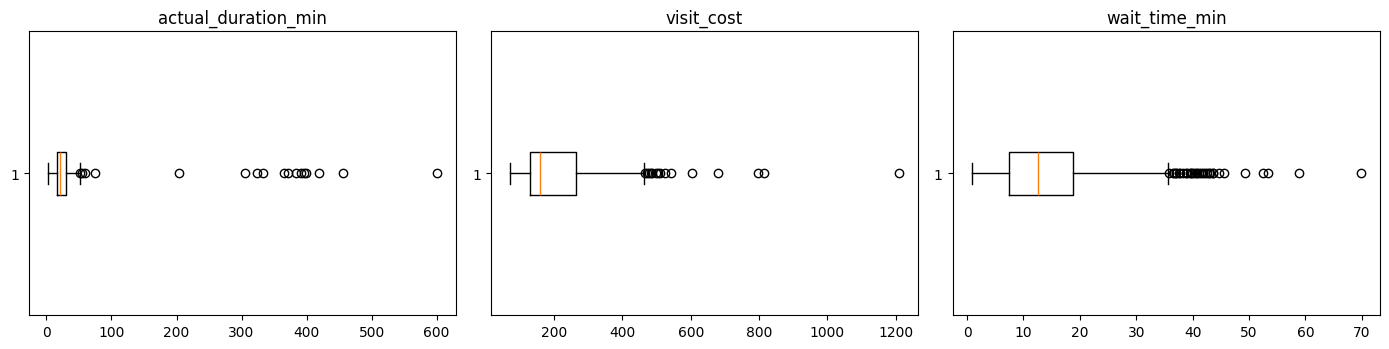

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, c in zip(ax, spalten):
    a.boxplot(df[c], vert=False)
    a.set_title(c)
plt.tight_layout()
plt.show()

**Kernaussage:** Die 1,5-×-IQR-Regel markiert 17 Werte bei der Dauer, 15 bei den Kosten und 32 bei der Wartezeit, alle am oberen Ende; bei der Dauer sind 14 der 17 weit vom Rest abgesetzt, bei der Wartezeit schließen die markierten Werte dagegen als durchgehender Rand an die Verteilung an.

#### Antwort Aufgabe 4b – `visit_cost`: eher echte Extremwerte (mit Vorbehalt)
- 15 Werte (≈ 1,2 %) liegen über ≈ 464 (bis ≈ 1.209), der Median ist ≈ 157.
- **Prüfungen:** (1) Keiner der 15 ist zugleich ein Dauer-Fehler – also keine Folgefehler. (2) Auf der Log-Skala ist die Verteilung fast symmetrisch (Schiefe ≈ 0,2), und die Regel markiert dort nur 3 Werte: Der Großteil der 15 ist also ein *normaler Rand* einer rechtsschiefen Kostenverteilung. Bei der strengen 3×IQR-Regel bleiben 4 Werte, am extremsten ist ≈ 1.209.
- **Auffällig:** Unter den 15 sind auffallend viele Privatversicherte (Details in der Ausgabe; 10 von 15 = 67 % bei einem Anteil von 34 %; Binomialtest p ≈ 0,013, also mit Zufall allein schwer zu erklären). Bei nur 15 Fällen ist das ein Hinweis, kein Beleg.
- **Entscheidung:** nicht löschen, aber gegen die Abrechnung prüfen; bei Kennzahlen den Median verwenden.

#### Antwort Aufgabe 4b – `wait_time_min`: normaler oberer Rand einer breiten Streuung – mit Standort-Effekt.
- 32 Werte (≈ 2,7 %) liegen über ≈ 35,8 Minuten; das Maximum ist ≈ 70. Wartezeiten sind nach unten durch 0 begrenzt und nach oben offen; Werte ab ca. 36 Minuten sind unangenehm, aber **physisch plausibel** → keine Fehler.
- **Prüfung der Verteilung:** Sie sind nicht gleichmäßig verteilt: **Riverside** stellt etwa die Hälfte der markierten Werte (17 von 32), obwohl dort nur ≈ 24 % der Besuche stattfinden; der Chi-Quadrat-Test (p ≈ 0,001, alle erwarteten Häufigkeiten ≥ 5) bestätigt, dass das kein Zufall ist. Das passt zum Befund aus 3a (Riverside hat insgesamt längere Wartezeiten).
- **Urteil:** keine Fehler und nicht löschen; aber ein **systematisches Muster** am Standort Riverside, das das Operations-Team interessieren dürfte.
- **Sensitivität:** Bei 3×IQR bleiben nur 3 Werte; bei |z| > 3 sind es 16. Das Ergebnis „viele moderate, wenige extreme“ ist typisch für eine rechtsschiefe Verteilung.

## Aufgabe 5 – Datenqualität
Drei Prüfungen, drei Werkzeuge: fehlende Werte → **Aufschlüsselung und Tests**, Duplikate → **Definition von „derselbe Besuch“**, Datentypen → **`dtypes` gegen Bedeutung**. Dazu kommen Plausibilitätsprüfungen (Wertebereiche, Logik).

### 5a) Fehlende Werte
**Frage:** Fehlen die Werte *zufällig* – oder hängt das Fehlen mit etwas anderem zusammen?
Drei Mechanismen, die man unterscheidet:
- **MCAR** (völlig zufällig): Fehlen hängt von nichts ab → Weglassen verzerrt kaum.
- **MAR** (zufällig gegeben andere Variablen): Fehlen hängt von *beobachteten* Variablen ab (hier z. B. Termintyp) → Auswertung nach dieser Variable getrennt oder gewichtet.
- **MNAR** (nicht zufällig): Fehlen hängt vom fehlenden Wert selbst ab (z. B. unzufriedene Patienten antworten nicht) → mit den vorhandenen Daten **nicht prüfbar**.

**H₀ (je Test):** Die Fehlquote ist in allen Gruppen gleich. α = 0,05.

In [23]:
fehl = df.isna().sum()
print(fehl[fehl > 0].to_string(), "\n")
print(
    f"Gesamtrate fehlende Zufriedenheit: {df.patient_satisfaction.isna().mean():.1%}\n"
)

df["sat_fehlt"] = df.patient_satisfaction.isna()
zeilen = []
for col in [
    "appointment_type",
    "clinic_site",
    "insurance_type",
    "no_show",
    "day_of_week",
]:
    t = pd.crosstab(df[col], df.sat_fehlt)
    chi2_m, p_m, dof_m, erw_m = stats.chi2_contingency(t)
    rate = (t[True] / t.sum(axis=1) * 100).round(1)
    zeilen.append(
        {
            "Spalte": col,
            "Fehlquote je Gruppe %": rate.to_dict(),
            "chi2": round(chi2_m, 2),
            "df": dof_m,
            "p": round(p_m, 4),
            "Cramers V": round(cramers_v(t), 3),
            "min. erwartet": round(erw_m.min(), 1),
        }
    )
pd.DataFrame(zeilen).set_index("Spalte")

patient_satisfaction    123 

Gesamtrate fehlende Zufriedenheit: 10.2%



,Fehlquote je Gruppe %,chi2,df,p,Cramers V,min. erwartet
Spalte,,,,,,
appointment_type,"{'Checkup': 5.3, 'Follow-up': 4.9, 'Specialist...",145.490,3,0.000,0.348,13.200
clinic_site,"{'Downtown': 10.0, 'Eastview': 10.5, 'Northgat...",0.490,3,0.921,0.020,22.600
insurance_type,"{'Medicaid': 10.2, 'Medicare': 10.4, 'Private'...",0.010,3,1.000,0.003,21.800
no_show,"{0: 9.7, 1: 14.7}",2.630,1,0.105,0.051,13.200
day_of_week,"{'Friday': 7.6, 'Monday': 5.8, 'Saturday': 10....",11.770,6,0.067,0.099,17.400


**Harmlose Erklärung 1 ausschließen – liegt es nur an der Gruppengröße?** Wäre Urgent einfach eine kleine Gruppe, könnten wenige Datensätze und größere Zufallsschwankungen die hohe Fehlquote erklären. Wir stellen deshalb Gruppengröße und Fehlquote nebeneinander (sortiert nach Größe).

In [24]:
y = "patient_satisfaction"
for col in ["appointment_type", "clinic_site", "insurance_type"]:
    t = (
        df.groupby(col)[y]
        .agg(n="size", fehlquote_pct=lambda s: 100 * s.isna().mean())
        .sort_values("n")
    )
    print(f"--- {col} (nach Groesse sortiert) ---")
    print(t.round(1), "\n")

--- appointment_type (nach Groesse sortiert) ---
                    n  fehlquote_pct
appointment_type                    
Specialist        129          4.700
Urgent            233         31.800
Follow-up         348          4.900
Checkup           490          5.300 

--- clinic_site (nach Groesse sortiert) ---
               n  fehlquote_pct
clinic_site                    
Eastview     220         10.500
Northgate    264          9.500
Riverside    286         11.200
Downtown     430         10.000 

--- insurance_type (nach Groesse sortiert) ---
                  n  fehlquote_pct
insurance_type                    
Self-pay        213         10.300
Medicaid        216         10.200
Medicare        357         10.400
Private         414         10.100 



**Ergebnis:** Urgent hat 233 Besuche, die **kleinste** Gruppe ist Specialist mit nur 129 Besuchen – und sie hat mit 4,7 % eine der **niedrigsten** Fehlquoten. Die Fehlquote folgt also **nicht** der Gruppengröße. Bei Standort und Versicherung liegen alle Fehlquoten bei ca. 9–11 %, unabhängig von der Größe: **Auch die zweite Spalte erklärt das Muster nicht** (siehe auch die Tests oben). Das Muster gehört zum Termintyp selbst.

In [25]:
# Gilt der Unterschied nur wegen Urgent?  Dieselben Tests NUR fuer Nicht-Urgent-Besuche
nu = df[df.appointment_type != "Urgent"]
print(f"Fehlquote bei Nicht-Urgent: {nu.sat_fehlt.mean():.1%}")
for col in [
    "appointment_type",
    "clinic_site",
    "insurance_type",
    "no_show",
    "day_of_week",
]:
    print(
        f"   {col:17s} p = {stats.chi2_contingency(pd.crosstab(nu[col], nu.sat_fehlt))[1]:.3f}"
    )

# Haengt das Fehlen mit der Wartezeit zusammen?  (Mann-Whitney-U, ohne Normalverteilungsannahme)
u1 = stats.mannwhitneyu(df.wait_time_min[df.sat_fehlt], df.wait_time_min[~df.sat_fehlt])
urg = df[df.appointment_type == "Urgent"]
u2 = stats.mannwhitneyu(
    urg.wait_time_min[urg.sat_fehlt], urg.wait_time_min[~urg.sat_fehlt]
)
print(f"\nWartezeit: fehlend vs. vorhanden (alle)   p = {u1.pvalue:.3f}")
print(f"Wartezeit: fehlend vs. vorhanden (Urgent) p = {u2.pvalue:.3f}")

# Praktische Folge fuer den Mittelwert der Zufriedenheit
vorhanden = df.patient_satisfaction.dropna()
je_typ = df.groupby("appointment_type").patient_satisfaction.mean()
gewicht = df.appointment_type.value_counts(normalize=True)
print(f"\nMittelwert (nur vorhandene Werte)        : {vorhanden.mean():.3f}")
print(f"Mittelwert nach Termintyp gewichtet     : {(je_typ * gewicht).sum():.3f}")
print("\nMittlere Zufriedenheit je Termintyp:\n", je_typ.round(2).to_string())

Fehlquote bei Nicht-Urgent: 5.1%
   appointment_type  p = 0.938
   clinic_site       p = 0.986
   insurance_type    p = 0.931
   no_show           p = 0.129
   day_of_week       p = 0.708

Wartezeit: fehlend vs. vorhanden (alle)   p = 0.485
Wartezeit: fehlend vs. vorhanden (Urgent) p = 0.071

Mittelwert (nur vorhandene Werte)        : 4.103
Mittelwert nach Termintyp gewichtet     : 4.101

Mittlere Zufriedenheit je Termintyp:
 appointment_type
Checkup      4.110
Follow-up    4.110
Specialist   4.110
Urgent       4.060


#### Antwort Aufgabe 5a – Befund

- 123 von 1.200 Werten (10,2 %) fehlen, ausschließlich in `patient_satisfaction`.
- Die Fehlquote ist **nicht gleichmäßig**: bei **Urgent ≈ 32 %**, bei allen anderen Typen ≈ 5 %. Der Test ist statistisch signifikant (χ² ≈ 145, p ≈ 10⁻³¹), und Cramérs V ≈ 0,35 zeigt: nicht nur signifikant, sondern auch ein **kräftiger** Zusammenhang.
- **Standort, Versicherung und No-show** zeigen keinen signifikanten Zusammenhang mit dem Fehlen (alle p > 0,05). Beim **Wochentag** liegt p knapp über 0,05 (≈ 0,07; V ≈ 0,10) – kein signifikanter Beleg; ohne Urgent verschwindet jeder Effekt (p ≈ 0,7). Außerhalb von Urgent ist das Fehlen also gleichmäßig verteilt.
- Das Fehlen hängt nicht erkennbar mit der Wartezeit zusammen (p ≈ 0,49; bei Urgent p ≈ 0,07 – kein signifikanter Beleg).
- **Mechanismus:** Das Fehlen ist **nicht MCAR**, denn es hängt klar vom Termintyp ab. Ob es **MAR** ist (hängt nur vom beobachteten Termintyp ab) oder **MNAR** (z. B. antworten unzufriedene Urgent-Patienten seltener – das Fehlen hängt dann vom fehlenden Wert selbst ab), lässt sich mit diesen Daten **nicht unterscheiden**.
- **Praktische Folge:** Die mittlere Zufriedenheit je Termintyp ist fast gleich (≈ 4,1); der Gesamtmittelwert ändert sich durch Gewichten kaum (4,103 gegenüber 4,101). **Falls** das Fehlen nur vom Termintyp abhängt, ist der Mittelwert also praktisch unverzerrt – aber für Urgent liegen deutlich weniger Antworten vor (159 von 233), die Aussagen über Urgent sind daher unsicherer.

**Kann man das gefahrlos ignorieren?** Nein, aber der Schaden ist begrenzt: Wer „die Zufriedenheit“ berichtet, sollte offenlegen, dass Urgent-Besuche seltener bewertet wurden.

**Korrektur:** Keine Imputation (das würde Zufriedenheit erfinden). Zeilen **behalten**, Fehlen mit `satisfaction_missing` kennzeichnen, bei Analysen paarweise ausschließen, im Bericht die Lücke bei Urgent nennen, Zufriedenheit nach Termintyp getrennt berichten.

### 5a-2) Entfernen, auffüllen oder markieren? – die drei ehrlichen Optionen
Jetzt vergleichen wir die Optionen, statt nur eine zu behaupten:
1. **Entfernen:** Mittelwert über die vorhandenen Werte (so macht es `mean()` automatisch, ohne dass jemand es entscheidet).
2. **Auffüllen:** fehlende Werte durch den Mittelwert ihrer Kategorie ersetzen. (Auffüllen mit dem *Gesamt*mittelwert ändert den Mittelwert nie – das zeigen wir zur Kontrolle ebenfalls.)
3. **Markieren:** keine neue Berechnung, sondern eine **Berichtsentscheidung**: Mittelwert *zusammen mit* Rücklaufquote je Kategorie ausweisen.

In [26]:
y, g = "patient_satisfaction", "appointment_type"

entfernen = df[y].mean()  # NaN wird automatisch uebersprungen
auffuellen_gruppe = (
    df[y].fillna(df.groupby(g)[y].transform("mean")).mean()
)  # Mittelwert der eigenen Kategorie
auffuellen_gesamt = df[y].fillna(df[y].mean()).mean()  # Kontrolle: aendert nichts

print(f"Option 1 entfernen             : {entfernen:.4f}")
print(
    f"Option 2 auffuellen (Kategorie): {auffuellen_gruppe:.4f}   (Differenz zu Option 1: {auffuellen_gruppe - entfernen:+.4f})"
)
print(
    f"Kontrolle auffuellen (gesamt)  : {auffuellen_gesamt:.4f}   (identisch mit Option 1)"
)

# Option 3: Markierungsspalte und Bericht mit Ruecklaufquote in DERSELBEN Tabelle
df["satisfaction_missing"] = df[y].isna()
bericht = df.groupby(g).agg(
    n=("visit_id", "size"),
    mit_antwort=(y, "count"),
    durchschnitt=(y, "mean"),
    fehlquote_pct=("satisfaction_missing", lambda s: 100 * s.mean()),
)
bericht["ruecklaufquote_pct"] = 100 - bericht["fehlquote_pct"]
print("\nBericht (Option 3):")
print(bericht.round(2).sort_values("fehlquote_pct", ascending=False))

Option 1 entfernen             : 4.1031
Option 2 auffuellen (Kategorie): 4.1009   (Differenz zu Option 1: -0.0022)
Kontrolle auffuellen (gesamt)  : 4.1031   (identisch mit Option 1)

Bericht (Option 3):
                    n  mit_antwort  durchschnitt  fehlquote_pct  \
appointment_type                                                  
Urgent            233          159         4.060         31.760   
Checkup           490          464         4.110          5.310   
Follow-up         348          331         4.110          4.890   
Specialist        129          123         4.110          4.650   

                  ruecklaufquote_pct  
appointment_type                      
Urgent                        68.240  
Checkup                       94.690  
Follow-up                     95.110  
Specialist                    95.350  


**Ergebnis und Lehre:**
- **Die Richtung ist die eigentliche Lektion:** Beim Entfernen ist Urgent wegen der vielen Lücken *unterrepräsentiert*; das Auffüllen mit dem Kategorienmittel gibt Urgent sein volles Gewicht zurück, und der Gesamtmittelwert wandert ein Stück in Richtung des (niedrigeren) Urgent-Niveaus (4,103 → 4,101).
- **In diesen Daten ist der Unterschied winzig** (0,002), weil der Durchschnitt aller Termintypen fast gleich ist (≈ 4,06–4,11). Das ist ein Befund, keine Entwarnung: Eine Verzerrung wäre nur **innerhalb von Urgent** möglich, falls die nicht erfassten Werte dort systematisch niedriger sind (MNAR). Beide berechneten Optionen würden diese Verzerrung **nicht** beheben – und sie lässt sich mit den Daten nicht prüfen.
- **Option 3 (markieren)** liefert keine dritte Zahl, sondern den ehrlichen Bericht: Durchschnitt Urgent ≈ 4,06 **zusammen mit** einer Rücklaufquote von ≈ 68,2 % (gegenüber ≈ 95 % bei den anderen Typen). Die Quote steht in derselben Tabelle wie der Mittelwert, nicht in einer Fußnote – dann liefert die Zahl ihren eigenen Vorbehalt mit.
- **Entscheidung:** Option 3 (markieren und berichten); Option 1 geschieht dabei automatisch, wird aber offengelegt. Auffüllen mit Mittelwerten würde Werte „erfinden“, ohne das eigentliche Problem zu lösen.

### 5b) Doppelte Datensätze
**Definition (vor dem Löschen):** „Derselbe Besuch zweimal“ = gleiche `visit_id` **und** alle übrigen Spalten identisch. Die `visit_id` ist ein Besuchsschlüssel und darf nur einmal vorkommen. Zwei Besuche derselben Person am selben Tag sind *nicht* automatisch dasselbe.

In [27]:
print("Komplett identische Zeilen            :", df_roh.duplicated().sum())
print("Doppelte visit_id                      :", df_roh.visit_id.duplicated().sum())
print(
    "Gleiche patient_id + appointment_date  :",
    df_roh.duplicated(["patient_id", "appointment_date"]).sum(),
)
print(
    "Gleiche patient_id + Datum + Standort + Typ, aber andere visit_id (versteckte Duplikate?):",
    int(
        (
            df_roh.duplicated(
                ["patient_id", "appointment_date", "clinic_site", "appointment_type"],
                keep=False,
            )
            & ~df_roh.duplicated(keep=False)
        ).sum()
    ),
)
ids = df_roh.visit_id.str[2:].astype(int)
print(
    f"visit_id ist lueckenlos von {ids.min()} bis {ids.max()}: {ids.nunique()} verschiedene IDs"
)

Komplett identische Zeilen            : 9
Doppelte visit_id                      : 9
Gleiche patient_id + appointment_date  : 29
Gleiche patient_id + Datum + Standort + Typ, aber andere visit_id (versteckte Duplikate?): 0
visit_id ist lueckenlos von 1 bis 1200: 1200 verschiedene IDs


**Die Dedup-Regel mit ihren zwei Kennzahlen.** Ein Deduplizierungsschritt für die Pipeline muss zwei Zahlen berichten können: wie viele Zeilen er entfernt – und wie viele *unterschiedliche* Datensätze eine bequemere, nur auf dem Schlüssel (Patient + Datum) beruhende Regel zerstört hätte.

In [28]:
basis = df_roh  # Prüfung der Duplikat-Regeln auf den Rohdaten


def dedup_vollzeile(d):
    # Richtige Regel: JEDE Spalte muss uebereinstimmen; die erste Kopie bleibt erhalten.
    return d.drop_duplicates(keep="first")


exakt_alle = basis.duplicated(keep=False)  # alle Zeilen eines exakten Paars
schluessel_alle = basis.duplicated(["patient_id", "appointment_date"], keep=False)

entfernt = len(basis) - len(dedup_vollzeile(basis))
markiert_schluessel = int(schluessel_alle.sum())
zerstoert = markiert_schluessel - int(exakt_alle.sum())

print(f"Exakte Duplikat-Zeilen (9 Paare)                 : {int(exakt_alle.sum())}")
print(
    f"Richtige Regel entfernt                          : {entfernt} Zeilen (je eine Kopie)"
)
print(
    f"Nur-Schluessel-Regel (Patient+Datum) markiert    : {markiert_schluessel} Zeilen"
)
print(f"  davon unterschiedliche Datensaetze (zerstoert)  : {zerstoert}")
print(
    f"  Anteil der markierten Zeilen, die falsch waeren : {zerstoert / markiert_schluessel:.0%}"
)

Exakte Duplikat-Zeilen (9 Paare)                 : 18
Richtige Regel entfernt                          : 9 Zeilen (je eine Kopie)
Nur-Schluessel-Regel (Patient+Datum) markiert    : 58 Zeilen
  davon unterschiedliche Datensaetze (zerstoert)  : 40
  Anteil der markierten Zeilen, die falsch waeren : 69%


Die 29 Zeilen mit gleichem Patient + Datum bestehen aus den **9 exakten Duplikaten** und **20 weiteren Paaren** mit *verschiedener* `visit_id`. Diese 20 Paare schauen wir uns genauer an.

In [29]:
exakt = df_roh.duplicated(keep=False)
paare = df_roh[
    df_roh.duplicated(["patient_id", "appointment_date"], keep=False) & ~exakt
]
g = paare.groupby(["patient_id", "appointment_date"])
print("Paare mit gleichem Patient + Datum und verschiedener visit_id:", g.ngroups)
print(
    "  davon mit verschiedenem Termintyp    :",
    int((g.appointment_type.nunique() > 1).sum()),
)
print(
    "  davon mit verschiedener Versicherung :",
    int((g.insurance_type.nunique() > 1).sum()),
)
print("  davon mit verschiedener Postleitzahl :", int((g.zip_code.nunique() > 1).sum()))
print(
    "  davon an verschiedenem Standort      :", int((g.clinic_site.nunique() > 1).sum())
)
paare.sort_values(["patient_id", "visit_id"])[
    [
        "patient_id",
        "visit_id",
        "appointment_date",
        "clinic_site",
        "appointment_type",
        "insurance_type",
        "zip_code",
    ]
].head(8)

Paare mit gleichem Patient + Datum und verschiedener visit_id: 20
  davon mit verschiedenem Termintyp    : 20
  davon mit verschiedener Versicherung : 15
  davon mit verschiedener Postleitzahl : 18
  davon an verschiedenem Standort      : 14


,patient_id,visit_id,appointment_date,clinic_site,appointment_type,insurance_type,zip_code
2,P-0139,R-00003,2026-01-08,Downtown,Follow-up,Self-pay,6510
138,P-0139,R-00139,2026-01-08,Downtown,Checkup,Private,7001
174,P-0174,R-00174,2026-02-28,Northgate,Checkup,Medicare,2445
430,P-0174,R-00430,2026-02-28,Downtown,Follow-up,Private,2139
181,P-0181,R-00181,2026-01-08,Downtown,Checkup,Private,7030
959,P-0181,R-00952,2026-01-08,Downtown,Follow-up,Self-pay,7001
211,P-0211,R-00211,2026-03-12,Eastview,Follow-up,Medicaid,7030
1118,P-0211,R-01111,2026-03-12,Northgate,Urgent,Private,2445


#### Antwort Aufgabe 5b – Befund

- **9 komplett identische Zeilen** (gleiche visit_id, alle Werte gleich) → echte Duplikate, vermutlich Doppelerfassung. **Gefahrlos ignorierbar? Nein** (sie zählen Besuche und Kosten doppelt). **Korrektur:** nur diese exakten Duplikate entfernen.
- **Keine versteckten Duplikate:** Es gibt keine Zeilen mit gleichem Patient, Datum, Standort und Termintyp, aber anderer visit_id. Die visit_id ist lückenlos 1 bis 1.200 – nach Entfernen der 9 Doppelten ist sie eindeutig.
- **20 Paare** haben gleichen Patienten und gleiches Datum, aber verschiedene `visit_id` – und in **allen 20** einen **unterschiedlichen Termintyp** (in 14 sogar einen anderen Standort). Das sind **getrennte, echte Besuche**; sie werden **nicht gelöscht**.
- **Warum die Unterscheidung zählt:** Hätten wir nur Patient + Datum als Regel benutzt, wären 58 Zeilen markiert und **40 echte Besuche zerstört** worden (69 % der markierten Zeilen wären falsch gewesen). Jede Anzahl, Summe und jeder Mittelwert danach wäre zu niedrig – ohne jeden Hinweis, dass etwas fehlt. Ein Dedup-Schritt, der die zweite Zahl (zerstörte Datensätze) nicht berichten kann, sollte nicht ausgeliefert werden.
- **Nebenbeobachtung (keine Löschentscheidung):** In 15 der 20 Paare unterscheidet sich auch die Versicherung, in 18 die Postleitzahl. Bei derselben Person am selben Tag wäre das ungewöhnlich; es kann an der Erfassung liegen (z. B. doppelt vergebene `patient_id`). Das ist **nur ein Hinweis**; die Zeilen bleiben und werden mit `same_day_repeat` gekennzeichnet, damit man beim Datenlieferanten nachfragen kann.

In [30]:
df_clean = df_roh.copy()  # Ausgangspunkt: Rohdaten
vorher = len(df_clean)
df_clean = df_clean.drop_duplicates(keep="first").reset_index(drop=True)
print(
    f"Zeilen vorher {vorher}, nachher {len(df_clean)} (entfernt: {vorher - len(df_clean)}); visit_id eindeutig: {df_clean.visit_id.is_unique}"
)

df_clean["satisfaction_missing"] = df_clean.patient_satisfaction.isna()
df_clean["same_day_repeat"] = df_clean.duplicated(
    ["patient_id", "appointment_date"], keep=False
)
print("Markiert same_day_repeat:", int(df_clean.same_day_repeat.sum()), "Zeilen")

Zeilen vorher 1209, nachher 1200 (entfernt: 9); visit_id eindeutig: True
Markiert same_day_repeat: 40 Zeilen


### 5c) Datentypen
**Frage:** Passt der gespeicherte Typ zu dem, was die Spalte *darstellen soll*?

In [31]:
print(df_clean.dtypes, "\n")
print("zip_code, Werte:", sorted(int(x) for x in df_clean.zip_code.unique()))
print("Anzahl Stellen:", sorted(df_clean.zip_code.astype(str).str.len().unique()))
print(
    "Postleitzahlen < 10000 (so gespeichert):",
    int((df_clean.zip_code < 10000).sum()),
    "von",
    len(df_clean),
)
print(
    "Laengste gespeicherte PLZ:",
    df_clean.zip_code.astype(str).str.len().max(),
    "Stellen -> nie mehr als 5, daher ist zfill(5) sicher",
)

print(
    "\nKategoriale Spalten ausdruecklich pruefen (Werte, Leerzeichen, Gross-/Kleinschreibung):"
)
for col in ["clinic_site", "appointment_type", "insurance_type", "day_of_week"]:
    werte = df_clean[col].astype(str)
    print(f"  {col:17s} {werte.nunique()} Werte: {sorted(werte.unique())}")
    print(
        f"  {'':17s} Leerzeichen am Rand: {(werte.str.strip() != werte).any()} | "
        f"Gross-/Klein-Dubletten: {werte.str.lower().nunique() != werte.nunique()}"
    )

print("\nBeispiel: so wuerde zip_code als Zahl in describe() behandelt:")
print(df_clean.zip_code.describe().round(1).to_string())

visit_id                   object
patient_id                 object
appointment_date           object
clinic_site                object
appointment_type           object
insurance_type             object
day_of_week                object
no_show                     int64
wait_time_min             float64
patient_satisfaction      float64
scheduled_duration_min      int64
actual_duration_min       float64
visit_cost                float64
zip_code                    int64
satisfaction_missing         bool
same_day_repeat              bool
dtype: object 

zip_code, Werte: [2134, 2139, 2445, 6510, 7001, 7030, 8540]
Anzahl Stellen: [np.int64(4)]
Postleitzahlen < 10000 (so gespeichert): 1200 von 1200
Laengste gespeicherte PLZ: 4 Stellen -> nie mehr als 5, daher ist zfill(5) sicher

Kategoriale Spalten ausdruecklich pruefen (Werte, Leerzeichen, Gross-/Kleinschreibung):
  clinic_site       4 Werte: ['Downtown', 'Eastview', 'Northgate', 'Riverside']
                    Leerzeichen am Rand: Fal

#### Antwort Aufgabe 5c – Befund

- **`zip_code` ist eine Zahl (int64), aber eine Kennung.** Rechnen mit Postleitzahlen ist sinnlos (siehe `describe()`: ein „Mittelwert“ der PLZ), und die **führende Null ging verloren**: Alle Werte haben 4 statt 5 Stellen (2134 statt `02134`). **Nicht ignorierbar** (falsche Auswertungen, Verknüpfung mit anderen Tabellen scheitert). Korrektur: als Text mit 5 Stellen.
- `appointment_date` ist ein Text → in `datetime` umwandeln (Sortierung, Zeitreihen).
- `patient_satisfaction` ist float (nur weil `NaN` es erzwingt; inhaltlich ganzzahlig 1–5) – unproblematisch.
- `no_show` (0/1) als Zahl ist als Indikator in Ordnung.
- **Kategoriale Spalten ausdrücklich geprüft** (nicht nur angenommen): `clinic_site`, `appointment_type`, `insurance_type`, `day_of_week` haben genau 4, 4, 4 und 7 verschiedene Werte, ohne Leerzeichen am Rand und ohne Groß-/Klein-Dubletten. Die bloße Ausgabe der Werte hätte „C1“ und „C1 “ nicht unterscheiden können – deshalb die direkte Prüfung. Sie sind sauber und werden als Kategorien gespeichert.
- Die Korrektur `zfill(5)` ist **sicher**, weil keine gespeicherte Postleitzahl mehr als 5 Stellen hat (höchstens 4 vorhanden).

In [32]:
df_clean["zip_code"] = df_clean["zip_code"].astype(str).str.zfill(5)
df_clean["appointment_date"] = pd.to_datetime(df_clean["appointment_date"])
for c in ["appointment_type", "clinic_site", "insurance_type", "day_of_week"]:
    df_clean[c] = df_clean[c].astype("category")

konsistent = (
    df_clean.appointment_date.dt.day_name() == df_clean.day_of_week.astype(str)
).mean()
print(f"day_of_week passt zum Datum in {konsistent:.1%} der Zeilen")
print(
    f"Datumsbereich: {df_clean.appointment_date.min().date()} bis {df_clean.appointment_date.max().date()}, "
    f"{df_clean.appointment_date.nunique()} verschiedene Tage"
)
print(df_clean.zip_code.value_counts().to_string())

day_of_week passt zum Datum in 100.0% der Zeilen
Datumsbereich: 2026-01-05 bis 2026-04-05, 91 verschiedene Tage
zip_code
02139    252
08540    244
02445    173
06510    162
07030    159
07001    126
02134     84


### 5d) Plausibilität: Wertebereiche und Logik
Auch Spalten mit richtigem Datentyp können unmögliche Werte enthalten. Wir prüfen Wertebereiche und innere Widersprüche.

In [33]:
print("Wertebereiche:")
print(
    f"   wait_time_min     min {df_clean.wait_time_min.min():.2f}   (negativ? {(df_clean.wait_time_min < 0).any()})"
)
print(
    f"   visit_cost        min {df_clean.visit_cost.min():.2f}   (<= 0? {(df_clean.visit_cost <= 0).any()})"
)
print(
    f"   actual_duration   min {df_clean.actual_duration_min.min():.2f}   (<= 0? {(df_clean.actual_duration_min <= 0).any()})"
)
sat = df_clean.patient_satisfaction.dropna()
print(
    f"   satisfaction      {sat.min():.0f} bis {sat.max():.0f}, nur ganzzahlig: {(sat % 1 == 0).all()}"
)

print("\nGeplante Dauer (Haeufigkeit je Wert):")
print(df_clean.scheduled_duration_min.value_counts().sort_index().to_string())

# Logik: Ein Besuch, der nicht stattfand (no_show = 1), sollte keine Dauer, keine Wartezeit, keine Kosten haben.
ns = df_clean[df_clean.no_show == 1]
print(f"\nno_show = 1: {len(ns)} Zeilen")
print(f"   davon mit Wartezeit    : {ns.wait_time_min.notna().sum()}")
print(f"   davon mit actual_duration > 0: {(ns.actual_duration_min > 0).sum()}")
print(f"   davon mit visit_cost > 0     : {(ns.visit_cost > 0).sum()}")
print(f"   davon mit Zufriedenheitswert  : {ns.patient_satisfaction.notna().sum()}")
print(
    f"   Median Kosten no-show vs. erschienen: {ns.visit_cost.median():.1f} vs. {df_clean[df_clean.no_show==0].visit_cost.median():.1f}"
)

Wertebereiche:
   wait_time_min     min 0.87   (negativ? False)
   visit_cost        min 70.86   (<= 0? False)
   actual_duration   min 2.40   (<= 0? False)
   satisfaction      1 bis 5, nur ganzzahlig: True

Geplante Dauer (Haeufigkeit je Wert):
scheduled_duration_min
10     95
13      1
15    261
20    333
30    286
40      1
42      1
45    147
60     75

no_show = 1: 129 Zeilen
   davon mit Wartezeit    : 129
   davon mit actual_duration > 0: 129
   davon mit visit_cost > 0     : 129
   davon mit Zufriedenheitswert  : 110
   Median Kosten no-show vs. erschienen: 195.3 vs. 156.2


#### Antwort Aufgabe 5d – Befund

- **Wertebereiche sind in Ordnung** (keine negativen oder Null-Werte; Zufriedenheit nur 1–5, ganzzahlig).
- **Seltene geplante Dauern:** Üblich sind 10, 15, 20, 30, 45 und 60 Minuten. Die Werte 13, 40 und 42 kommen nur je einmal vor. Auffällig, aber keine Löschentscheidung; wir geben den Hinweis weiter (drei dieser Zeilen gehören zu den Markierten aus Aufgabe 4a).
- **Logischer Widerspruch bei `no_show`:** Alle 129 no-show-Besuche haben trotzdem Wartezeit, tatsächliche Dauer und Kosten, 110 sogar eine Zufriedenheitsbewertung. Ein nicht stattgefundener Besuch kann nicht gewartet, gedauert oder bewertet worden sein. **Nicht gefahrlos ignorierbar**: Kosten- und Dauer-Auswertungen enthalten dann „Geisterbesuche“. Wir können aus den Daten nicht entscheiden, welche Spalte falsch ist (das Flag `no_show` oder die Messwerte). **Korrektur:** nicht löschen (Ursache unbekannt); für Dauer-/Kosten-/Wartezeit-Auswertungen eine Sensitivitätsrechnung ohne no-show mitführen und beim Datenlieferanten klären, wie `no_show` definiert ist.

### 5e) Beschreibende Statistik

Kennzahlen der Wartezeit je Standort und über alle Besuche sowie der Besuchskosten: Fallzahl, Mittelwert, Median, Standardabweichung, Minimum, Q1, Q3 und Maximum. Dazu ein Diagramm der Wartezeit für Downtown und Riverside (Histogramm und Dichte) mit einer Beschreibung der Beobachtung. Die letzte Zelle berechnet jede dieser Zahlen neu und prüft sie, denn sie werden auch in der Präsentation (Folien 4 bis 6) verwendet.

In [34]:
# ------------------------------------------------------------
# 5e) Beschreibende Statistik: Wartezeit je Standort und Besuchskosten
# Datenbasis: df (ohne die 9 exakten Duplikate), dieselbe Basis wie in allen Checkpoints
# ------------------------------------------------------------
def summary_tabelle(gruppen):
    # Kennzahlen je Gruppe: Fallzahl, Mittelwert, Median, Standardabweichung, Minimum, Q1, Q3, Maximum
    zeilen = {}
    for name, s in gruppen.items():
        s = s.dropna()
        zeilen[name] = {
            "n": len(s),
            "Mittelwert": s.mean(),
            "Median": s.median(),
            "SD": s.std(ddof=1),  # Stichproben-SD (durch n-1)
            "Min": s.min(),
            "Q1": s.quantile(0.25),
            "Q3": s.quantile(0.75),
            "Max": s.max(),
        }
    return pd.DataFrame(zeilen).T


# Wartezeit: je Standort und über alle Besuche gemeinsam
wartezeit = {standort: g["wait_time_min"] for standort, g in df.groupby("clinic_site")}
wartezeit["Alle Standorte"] = df["wait_time_min"]
tab_wartezeit = summary_tabelle(wartezeit)
print("Wartezeit in Minuten:")
print(tab_wartezeit.round(2).to_string())

# Besuchskosten (alle Besuche)
tab_kosten = summary_tabelle({"Besuchskosten": df["visit_cost"]})
print("\nBesuchskosten:")
print(tab_kosten.round(2).to_string())

Wartezeit in Minuten:
                       n  Mittelwert  Median    SD   Min     Q1     Q3    Max
Downtown         430.000      12.180  10.400 8.120 0.870  6.530 15.780 69.780
Eastview         220.000      12.620  11.260 8.240 1.840  6.350 16.630 52.480
Northgate        264.000      11.950  10.240 7.770 0.940  6.480 15.760 43.120
Riverside        286.000      20.760  18.800 8.400 7.720 14.620 25.530 53.290
Alle Standorte 1,200.000      14.250  12.520 8.900 0.870  7.480 18.800 69.780

Besuchskosten:
                      n  Mittelwert  Median     SD    Min      Q1      Q3       Max
Besuchskosten 1,200.000     190.830 157.280 90.440 70.860 130.130 263.730 1,208.540


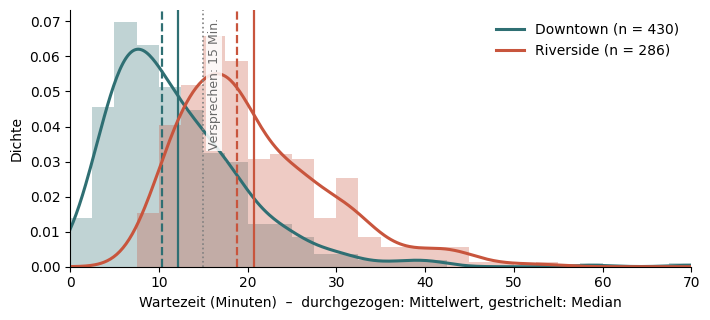

In [35]:
# ------------------------------------------------------------
# Diagramm: Wartezeit Downtown gegen Riverside (Histogramm auf Dichte skaliert + Kerndichte)
# Ziel: VOR dem Welch-Test die deskriptiven Unterschiede zeigen (Lage, Streuung, Form).
# Durchgezogene Linie = Mittelwert, gestrichelt = Median.
# ------------------------------------------------------------
from pathlib import Path

farben = {
    "Downtown": "#2F6F73",
    "Riverside": "#C8553D",
}  # feste Farben je Standort (wie in den übrigen Diagrammen zu Downtown und Riverside)
gitter = np.linspace(0, 70, 400)  # x-Achse für die Kerndichte

fig, ax = plt.subplots(figsize=(7.2, 3.3))
for standort, farbe in farben.items():
    werte = df.loc[df["clinic_site"] == standort, "wait_time_min"].dropna()
    ax.hist(
        werte, bins=np.arange(0, 72, 2.5), density=True, alpha=0.30, color=farbe
    )  # Histogramm als Dichte
    ax.plot(
        gitter,
        stats.gaussian_kde(werte)(gitter),
        color=farbe,
        lw=2.2,
        label=f"{standort} (n = {len(werte)})",
    )  # geglättete Dichte (Kerndichteschätzer)
    ax.axvline(werte.mean(), color=farbe, lw=1.6)  # Mittelwert
    ax.axvline(werte.median(), color=farbe, lw=1.6, ls="--")  # Median
ax.axvline(15, color="grey", lw=1.2, ls=":")  # Serviceversprechen: 15 Minuten
ax.text(
    15.5,
    ax.get_ylim()[1] * 0.97,
    "Versprechen: 15 Min.",
    color="dimgrey",
    fontsize=9,
    rotation=90,
    va="top",
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1),
)  # Beschriftung am Rand der 15-Min.-Linie
ax.set_xlabel("Wartezeit (Minuten)  –  durchgezogen: Mittelwert, gestrichelt: Median")
ax.set_ylabel("Dichte")
ax.set_xlim(0, 70)
ax.legend(frameon=False)
for kante in ("top", "right"):
    ax.spines[kante].set_visible(False)
plt.tight_layout()

plt.show()

**Was die Tabellen und das Diagramm zeigen:** Die Wartezeit ist über alle Standorte rechtsschief (Mittelwert 14,25 über Median 12,52; Maximum 69,78 Minuten). Downtown (Mittelwert 12,18) und Riverside (20,76) streuen ähnlich (SD 8,12 gegenüber 8,40), aber die gesamte Verteilung von Riverside liegt weiter rechts: Der Median beträgt 18,80 gegenüber 10,40 Minuten, und das untere Quartil von Riverside (14,62) liegt fast beim oberen Quartil von Downtown (15,78). Das ist eine **beschreibende** Beobachtung; ob der Unterschied über den Zufall hinausgeht, entscheidet erst der Welch-Test in Checkpoint 3.


In [36]:
# ------------------------------------------------------------
# Prüfung: Alle Zahlen aus 5e (auch auf den Folien 4, 5 und 6 der Präsentation) werden hier neu berechnet
# (assert bricht bei Abweichung ab). Toleranz 0,0051: Folienzahlen sind auf 2 Nachkommastellen gerundet.
# ------------------------------------------------------------
def gleich(ist, soll, tol=0.0051):
    # True, wenn alle Werte höchstens tol vom Sollwert abweichen (Rundungsreserve)
    return all(abs(float(a) - b) <= tol for a, b in zip(ist, soll))


dt = df.loc[df["clinic_site"] == "Downtown", "wait_time_min"]
rv = df.loc[df["clinic_site"] == "Riverside", "wait_time_min"]

# Folie 4: Wartezeit alle Standorte (Mittelwert, Median, SD, Min, Q1, Q3, Max)
w = df["wait_time_min"]
assert len(w) == 1200
assert gleich(
    [
        w.mean(),
        w.median(),
        w.std(),
        w.min(),
        w.quantile(0.25),
        w.quantile(0.75),
        w.max(),
    ],
    [14.25, 12.52, 8.90, 0.87, 7.48, 18.80, 69.78],
)

# Folie 4: Besuchskosten (Min, Q1, Median, Q3, Max, Mittelwert, SD)
k = df["visit_cost"]
assert gleich(
    [
        k.min(),
        k.quantile(0.25),
        k.median(),
        k.quantile(0.75),
        k.max(),
        k.mean(),
        k.std(),
    ],
    [70.86, 130.13, 157.28, 263.73, 1208.54, 190.83, 90.44],
)

# Folie 5: Downtown (Mittelwert, Median, SD, Min, Q1, Q3, Max)
assert len(dt) == 430
assert gleich(
    [
        dt.mean(),
        dt.median(),
        dt.std(),
        dt.min(),
        dt.quantile(0.25),
        dt.quantile(0.75),
        dt.max(),
    ],
    [12.18, 10.40, 8.12, 0.87, 6.53, 15.78, 69.78],
)

# Folie 6: Riverside und Anteile mit mehr als 15 Minuten Wartezeit
assert len(rv) == 286
assert gleich(
    [
        rv.mean(),
        rv.median(),
        rv.std(),
        rv.min(),
        rv.quantile(0.25),
        rv.quantile(0.75),
        rv.max(),
    ],
    [20.76, 18.80, 8.40, 7.72, 14.62, 25.53, 53.29],
)
assert gleich([100 * (dt > 15).mean(), 100 * (rv > 15).mean()], [27.9, 72.7], tol=0.051)

print("Alle Zahlen auf den Folien 4, 5 und 6 stimmen mit den Daten überein.")

Alle Zahlen auf den Folien 4, 5 und 6 stimmen mit den Daten überein.


### 5f) Die Dauer-Fehler aus Aufgabe 4

In [37]:
df_clean["ratio"] = df_clean.actual_duration_min / df_clean.scheduled_duration_min
df_clean["duration_suspect"] = (
    df_clean.ratio > 5
)  # Schwelle aus Aufgabe 4a (Luecke 2,1 -> 5,7)
print("Besuche mit actual > 5 x scheduled:", int(df_clean.duration_suspect.sum()))

Besuche mit actual > 5 x scheduled: 14


Diese Werte werden **gekennzeichnet** (`duration_suspect`), nicht gelöscht. Für Auswertungen der Dauer ausschließen; für Kosten und Wartezeit können die Zeilen bleiben, weil dort kein Hinweis auf Fehler besteht (siehe Überschneidungsprüfung in 4b). Die Schwelle 5 × geplant haben wir *nach* Ansicht der Daten gewählt. Die Faktor-Probe aus 4a-2 spricht für einen Dezimalfehler (Faktor ≈ 10); eine Korrektur der Werte erfolgt erst, wenn der Datenlieferant das bestätigt.

### 5g) Auffälligkeit in `visit_cost`: die Häufung ab ≈ 263,7
Im feinen Histogramm (Aufgabe 1) fiel eine Häufung auf. Wir prüfen, ob sie mit einer anderen Variablen zusammenhängt (H₀ je Test: Anteil in der Häufung ist in allen Gruppen gleich).

In [38]:
vc2 = df_clean.visit_cost
print("Die haeufigsten exakten Werte:")
print(vc2.round(2).value_counts().head(4).to_string())

df_clean["cost_cluster"] = vc2.between(263.73, 300)
print(
    f"\nBesuche zwischen 263,73 und 300: {df_clean.cost_cluster.sum()} ({df_clean.cost_cluster.mean():.1%})"
)

zeilen = []
for col in [
    "appointment_type",
    "clinic_site",
    "insurance_type",
    "day_of_week",
    "scheduled_duration_min",
    "no_show",
]:
    t = pd.crosstab(df_clean[col], df_clean.cost_cluster)
    t = t[
        t.sum(axis=1) >= 10
    ]  # sehr kleine Gruppen weglassen (Voraussetzung erwartete H. >= 5)
    zeilen.append(
        {
            "Spalte": col,
            "chi2": stats.chi2_contingency(t)[0],
            "p": stats.chi2_contingency(t)[1],
            "Anteil je Gruppe %": (100 * t[True] / t.sum(axis=1)).round(0).to_dict(),
        }
    )
pd.DataFrame(zeilen).set_index("Spalte").round(3)

Die haeufigsten exakten Werte:
visit_cost
263.730    8
263.740    8
263.750    5
132.080    3

Besuche zwischen 263,73 und 300: 218 (18.2%)


,chi2,p,Anteil je Gruppe %
Spalte,,,
appointment_type,5.373,0.146,"{'Checkup': 21.0, 'Follow-up': 15.0, 'Speciali..."
clinic_site,4.691,0.196,"{'Downtown': 15.0, 'Eastview': 21.0, 'Northgat..."
insurance_type,1.032,0.794,"{'Medicaid': 18.0, 'Medicare': 19.0, 'Private'..."
day_of_week,5.173,0.522,"{'Friday': 21.0, 'Monday': 18.0, 'Saturday': 1..."
scheduled_duration_min,5.170,0.395,"{10: 15.0, 15: 20.0, 20: 17.0, 30: 16.0, 45: 2..."
no_show,0.249,0.618,"{0: 18.0, 1: 20.0}"


**Befund 5g:** Zwischen 263,73 und 300 liegt knapp ein Fünftel aller Besuche in einem schmalen Band; ab 263,73 häufen sich sogar mehrere identische Beträge (z. B. 263,73 und 263,74 je 8-mal – bei zufällig verteilten Kosten wäre das kaum zu erwarten). Die Häufung hängt **weder mit Termintyp, Standort, Versicherung, Wochentag, geplanter Dauer noch No-show zusammen** (alle p > 0,05). Sie sieht nach einer Regel im System aus (z. B. Mindestbetrag oder Pauschale), aber das ist **nur eine Vermutung**. Konsequenz: Mittelwert und Median beschreiben diese Verteilung nur unvollständig (siehe Aufgabe 2). **Beim Datenlieferanten nachfragen.**

### Auswirkung der Bereinigung auf die Ergebnisse
Wir wiederholen die Kernrechnungen auf den bereinigten Daten (ohne exakte Duplikate; bei der Dauer zusätzlich ohne `duration_suspect`), um zu zeigen, wie viel die Korrekturen ändern.

In [39]:
def kennzahlen(d, ohne_dauerfehler=False):
    pr = d[["wait_time_min", "patient_satisfaction"]].dropna()
    t = pd.crosstab(d.appointment_type.astype(str), d.no_show)
    dd = d[~d.duration_suspect] if ohne_dauerfehler else d
    return {
        "Zeilen": len(d),
        "visit_cost Median": d.visit_cost.median(),
        "visit_cost Mittelwert": d.visit_cost.mean(),
        "actual_duration Median": dd.actual_duration_min.median(),
        "actual_duration Mittelwert": dd.actual_duration_min.mean(),
        "Spearman Wartezeit/Zufriedenheit": stats.spearmanr(
            pr.wait_time_min, pr.patient_satisfaction
        )[0],
        "Chi2 Termintyp/no-show": stats.chi2_contingency(t)[0],
        "Cramers V": cramers_v(t),
        "IQR-Ausreisser actual_duration": int(
            iqr_flags(dd.actual_duration_min)[0].sum()
        ),
        "IQR-Ausreisser visit_cost": int(iqr_flags(d.visit_cost)[0].sum()),
        "IQR-Ausreisser wait_time": int(iqr_flags(d.wait_time_min)[0].sum()),
    }


roh_d = df_roh.copy()
roh_d["duration_suspect"] = (
    roh_d.actual_duration_min / roh_d.scheduled_duration_min
) > 5
roh_d["appointment_type"] = roh_d.appointment_type.astype("category")

vergleich = pd.DataFrame(
    {
        "roh": kennzahlen(roh_d),
        "bereinigt (Duplikate raus)": kennzahlen(df_clean),
        "bereinigt + ohne Dauerfehler": kennzahlen(df_clean, ohne_dauerfehler=True),
    }
)
vergleich.round(3)

,roh,bereinigt (Duplikate raus),bereinigt + ohne Dauerfehler
Zeilen,"1,209.000","1,200.000","1,200.000"
visit_cost Median,157.040,157.285,157.285
visit_cost Mittelwert,190.730,190.834,190.834
actual_duration Median,20.680,20.680,20.615
actual_duration Mittelwert,25.000,25.016,21.075
Spearman Wartezeit/Zufriedenheit,-0.397,-0.403,-0.403
Chi2 Termintyp/no-show,13.234,13.342,13.342
Cramers V,0.105,0.105,0.105
IQR-Ausreisser actual_duration,17.000,17.000,4.000
IQR-Ausreisser visit_cost,15.000,15.000,15.000


**Was der Vergleich zeigt:**
- **Kosten, Zusammenhänge und Chi-Quadrat** ändern sich durch die Bereinigung praktisch nicht. Das Entfernen der 9 exakten Duplikate ist für die Aussagen **unschädlich**. Wir rechnen deshalb ab dem zentralen Setup durchgehend auf der bereinigten Datenbasis; die Spalte „roh“ zeigt zum Vergleich, was sich dadurch ändert (fast nichts).
- **Ausreißerzahl `wait_time`:** 34 → 32 (die Quartile verschieben sich leicht und doppelte Zeilen entfallen) – die Aussage bleibt gleich.
- **Dauer:** Der **Mittelwert** der tatsächlichen Dauer fällt von ca. 25 auf ca. 21 Minuten, die Zahl der IQR-Ausreißer von 17 auf 4; der **Median** bleibt nahezu gleich (≈ 20,7). Das ist das Lehrbeispiel für den Unterschied zwischen **robusten** (Median) und **nicht robusten** Kennzahlen (Mittelwert).

## Entscheidungsprotokoll
| # | Entscheidung | Nicht gewählte Alternative | Begründung | Geprüft durch | Ergebnis |
|---|---|---|---|---|---|
| 1 | α = 0,05 | α = 0,01 (strenger: weniger Fehlalarme, aber mehr übersehene Effekte) | Konvention; vor den Tests festgelegt | – | – |
| 2 | Median als Folienzahl für `visit_cost` | Mittelwert (191) – beantwortet eher „Was kosten die Besuche insgesamt?“ | typischer Besuch; reagiert kaum auf Extremwerte | Summenprobe, Entfernen der Top-15, Bootstrap-KI | Median bleibt, plus Quartilsbereich; wegen Lücke ist der Median unsicherer (KI ca. doppelt so breit) |
| 3 | Fehlende Zufriedenheit: markieren und berichten (Option 3); paarweiser Ausschluss | Zeilen mit fehlender Zufriedenheit entfernen oder Werte auffüllen | Auffüllen erfindet Werte und behebt die mögliche Verzerrung nicht | Gruppengröße ausgeschlossen; Fehlquoten-Tests; Entfernen 4,103 vs. Auffüllen 4,101; Subgruppen-Korrelation | nicht MCAR; MAR/MNAR nicht unterscheidbar; Wirkung auf Mittelwert klein |
| 4 | Pearson r mit Konfidenzintervall als Hauptaussage | Spearman als Hauptmaß (als Robustheitsprüfung gerechnet) | Aufgabe verlangt die Korrelation zweier quantitativer Variablen; Zufriedenheit ist ordinal, Wartezeit schief, deshalb Gegenprobe | Normalitätstests, Spearman/Kendall/log-Pearson | alle Maße stimmen überein (r ≈ −0,39, ρ ≈ −0,40) |
| 5 | Chi-Quadrat für Termintyp/no-show | Fisher-Test bzw. Yates-Korrektur als Hauptverfahren (als Gegenprobe gerechnet) | zwei kategoriale Variablen | erwartete H. ≥ 5; Bonferroni; Fisher/Yates; 1 Besuch je Patient | Voraussetzungen erfüllt; nur Urgent weicht ab; robust |
| 6 | Ausreißerregel 1,5 × IQR | 3 × IQR, z-Wert über 3 oder Regel auf Log-Skala (im Vergleich gerechnet) | übliche Standardregel, vorher festgelegt | vier Alternativregeln, Log-Skala, Verteilung des Verhältnisses | Zahl hängt von der Regel ab; 14 Dauerwerte klar abgesetzt |
| 7 | Dauer-Fehler markieren statt löschen (Schwelle 5×) | die 14 Dauerwerte löschen oder per Faktor ≈ 10 korrigieren | Fehlerursache nur vermutet | Lücke zwischen 2,1× und 5,7×; Faktor-Probe (KS-Test, 4a-2) | Faktor ≈ 10 gut vereinbar (nicht eindeutig 10), Schwelle nach Ansicht der Daten gewählt → beim Lieferanten bestätigen |
| 8 | Nur exakte Duplikate löschen (Vollzeilen-Regel) | Nur-Schlüssel-Regel (Patient + Datum): 58 Zeilen markiert, 40 echte Besuche zerstört | eine Zeile ist nur dann ein Duplikat, wenn alle Spalten übereinstimmen; Patient + Datum ist kein Besuchsschlüssel | versteckte Duplikate gesucht; Nur-Schlüssel-Regel (Patient + Datum) verglichen (58 markiert, 40 zerstört); roh vs. bereinigt | 9 gelöscht; kein Effekt auf Aussagen |
| 9 | 20 Same-Day-Paare behalten, kennzeichnen | die 20 Same-Day-Paare als Duplikate entfernen | verschiedener Termintyp in allen 20 → getrennte Besuche | Termintyp/Versicherung/PLZ/Standort verglichen; Nur-Schlüssel-Regel (Patient + Datum) hätte 40 echte Besuche zerstört | behalten; Nebenbeobachtung: Versicherung/PLZ weichen oft ab |
| 10 | no-show-Widerspruch melden, nicht löschen | die 129 Besuche mit no_show = 1 löschen | Ursache unklar | Zählung von Wartezeit/Dauer/Kosten/Bewertung bei no_show = 1 | alle 129 betroffen |
| 11 | Zuerst deduplizieren, dann alles auf den bereinigten Daten rechnen (Rohdaten nur zum Vergleich) | Roh rechnen und die Wirkung der Bereinigung daneben zeigen (Stand v8) | Dubletten sind Erfassungsfehler; die Analysen sollen auf der bereinigten Datenbasis stehen | Vergleichstabelle roh / bereinigt (Aufgabe 5) | nur Kleinigkeiten ändern sich (z. B. Ausreißer Wartezeit 34 → 32, Riverside n 290 → 286) |

## Offene Fragen an den Datenlieferanten
1. Einheit/Eingabe der 14 Dauerwerte mit dem 5,7- bis 13-Fachen der Planung? (Probe 4a-2: passt zu einem Dezimalfehler um den Faktor ≈ 10)
2. Warum gibt es eine Häufung der Kosten ab ≈ 263,7 (Mindestbetrag? Pauschale?)?
3. Was bedeutet `no_show = 1`, wenn trotzdem Wartezeit, Dauer, Kosten und Bewertung vorhanden sind?
4. In 15 von 20 Same-Day-Paaren weicht die Versicherung ab, in 18 die Postleitzahl: Erfassungsproblem (z. B. doppelt vergebene `patient_id`) oder echte Änderung?
5. Warum werden Urgent-Besuche seltener bewertet (≈ 32 % fehlend gegenüber ≈ 5 %)?
6. Warum hat Riverside deutlich längere Wartezeiten?

## Fazit: Kannst du diesen Daten vertrauen?
**Mit Einschränkungen – und mit klaren, dokumentierten Korrekturen.**
- **Gut belegt:** Wartezeit und Zufriedenheit hängen mäßig negativ zusammen (robust über alle Methoden und Subgruppen). Urgent-Termine haben mehr no-shows, aber der Zusammenhang insgesamt ist schwach. Kosten sind rechtsschief → Median berichten.
- **Korrigiert:** 9 Duplikate entfernt, `zip_code` als Text, `appointment_date` als Datum, fehlende Zufriedenheit transparent behandelt.
- **Nicht gelöscht, aber markiert und zu klären:** 14 Dauerwerte (vermutlich Dezimalfehler um den Faktor ≈ 10, siehe 4a-2), 20 Same-Day-Paare mit abweichender Versicherung/PLZ (Nebenbeobachtung), no-show-Widerspruch, Kostenhäufung bei ≈ 264.
- **Für das Operations-Team inhaltlich wichtig:** Riverside hat längere Wartezeiten und niedrigere Zufriedenheit.
- **Nicht prüfbar mit diesen Daten:** ob die fehlenden Zufriedenheitswerte von der Zufriedenheit selbst abhängen (MNAR) und ob die Dauer-Werte *wirklich* Fehler sind.

---
## Antworten zur Projektabgabe – Checkpoint 1 (Kurzfassung in Alltagssprache)

Die Projektabgabe verlangt zu Checkpoint 1 bestimmte Antworten. Sie stehen hier **an einer Stelle**, jeweils in wenigen Sätzen und ohne Formeln. Begründung, Code und Prüfungen stehen in der genannten Aufgabe oben. Jede Zahl wird in der Code-Zelle darunter aus den Daten neu berechnet.

#### 1. Verteilungsform der Besuchskosten (Aufgabe 1)

Die sechs Zahlen lauten: Minimum 70,86, erstes Quartil 130,13, Median 157,28, drittes Quartil 263,73, Maximum 1.208,54 und Mittelwert 190,83. Zusammen zeigen sie eine **rechtsschiefe** Verteilung: Die Hälfte der Besuche kostet höchstens rund 157, aber wenige sehr teure Besuche ziehen den Mittelwert auf rund 191 nach oben. Vom Median bis zum dritten Quartil ist der Abstand etwa viermal so lang wie vom ersten Quartil bis zum Median (106,45 gegenüber 27,15), und das Maximum liegt mehr als 1.000 über dem Median. Ein feines Histogramm zeigt zusätzlich eine Häufung ab etwa 264. Das deutet auf eine Mischung zweier Teilgruppen hin, nachgewiesen haben wir das nicht.

#### 2. Mittelwert oder Median (Aufgabe 2)

Für die Präsentationsfolie verwenden wir den **Median** (rund 157). Er beschreibt den typischen Besuch: Lässt man die 15 teuersten Besuche weg, verschiebt sich der Median nur um 0,9, der Mittelwert dagegen um 5,2. Die Frage, für die der Mittelwert richtig wäre, lautet: „Was kosten die Besuche in diesem Quartal insgesamt?“ Mittelwert mal Anzahl ergibt genau die Gesamtsumme (229.001). Einschränkung: Der Median ist selbst weniger genau bestimmt, seine Schwankungsbreite ist etwa doppelt so groß wie beim Mittelwert, und eine einzelne Zahl bildet die Häufung bei 264 nicht ab. Deshalb nennen wir auf der Folie zusätzlich den Bereich, in dem die mittleren 50 % der Besuche liegen (130 bis 264).

#### 3. Zusammenhänge (Aufgabe 3)

*Wartezeit und Zufriedenheit:* Je länger die Wartezeit, desto niedriger die Zufriedenheit. Die Korrelation beträgt −0,39 (mäßig stark; mit den Daten vereinbar ist ein Bereich von −0,44 bis −0,34, ausgewertet an 1.077 Besuchen mit beiden Angaben). Rund 15 % der Streuung der Zufriedenheit hängen gradlinig mit der Wartezeit zusammen. Das heißt nicht, dass die Wartezeit die Ursache ist. *Termintyp und No-Show:* Der Zusammenhang ist statistisch signifikant, aber **schwach**: Das Zusammenhangsmaß Cramérs V (0 = kein, 1 = vollständiger Zusammenhang) beträgt nur 0,105. Er geht fast ausschließlich auf Urgent-Termine zurück (17,2 % No-Shows gegenüber 9,2 % bei den übrigen Terminen). Ein kleiner p-Wert allein hätte „stark“ suggeriert, die Stärke relativiert das.

#### 4. Ausreißerregel (Aufgabe 4)

Vorab festgelegt (Aufgabe 4, vor der Anwendung): Als Ausreißer gilt jeder Wert, der mehr als das 1,5-Fache des Quartilsabstands unter dem ersten oder über dem dritten Quartil liegt. Markiert wurden bei der **tatsächlichen Dauer 17**, bei den **Besuchskosten 15** und bei der **Wartezeit 32** Werte, alle am oberen Ende. *Dauer:* 14 der 17 liegen beim 5,7- bis 13-Fachen der geplanten Zeit, und es liegt kein einziger Besuch dazwischen. Das spricht für **Fehler** (vermutlich ein Dezimalfehler um etwa den Faktor 10, nicht bewiesen). Die übrigen 3 sind normaler Rand. *Besuchskosten:* eher **echte Extremwerte** (mit Vorbehalt: Auffallend viele sind Privatversicherte). *Wartezeit:* **echte Extremwerte**, plausibel und besonders häufig in Riverside (17 von 32).

#### 5. Datenqualität (Aufgabe 5)

*Fehlende Werte:* Bei 123 Besuchen (10,2 %) fehlt die Zufriedenheit, bei Urgent-Terminen in 31,8 % der Fälle, sonst in rund 5 %. Wir füllen nichts auf, sondern kennzeichnen die Lücke und nennen die Rücklaufquote. *Doppelte Datensätze:* 9 exakt doppelte Zeilen wurden entfernt, 20 Besuchspaare derselben Person am selben Tag bleiben stehen, weil es getrennte Besuche sind. *Spaltentypen:* Die Postleitzahl ist eine Kennung und wird als Text mit 5 Stellen geführt, das Datum als Datum.

### Änderungen an den Daten – was verändert wurde, was bewusst unverändert blieb und warum

| Was | Wie behandelt | Warum | Wirkung auf die Aussagen |
|---|---|---|---|
| 9 exakte Duplikate | entfernt | zählen Besuche und Kosten doppelt | praktisch keine (Median der Kosten 157,0 roh gegenüber 157,3 bereinigt; Unterschied Riverside–Downtown 8,54 gegenüber 8,58 Minuten) |
| 14 abgesetzte Dauerwerte | **markiert** (`duration_suspect`), nicht gelöscht oder korrigiert | Ursache nur vermutet, der Datenlieferant muss sie bestätigen | **ja, bei der Dauer:** Mittelwert 25,0 statt 21,1 Minuten, Ausreißer 17 statt 4 |
| Fehlende Zufriedenheit (123) | markiert, Rücklaufquote berichtet, nicht aufgefüllt | Auffüllen erfindet Werte | kaum: Mittelwert 4,103 (weglassen) gegenüber 4,101 (auffüllen); Aussagen zu Urgent sind unsicherer (Rücklaufquote 68,2 %) |
| Postleitzahl und Datum | in Text mit 5 Stellen bzw. in Datum umgewandelt (nur in `df_clean`) | Kennung mit verlorener führender Null; Text-Datum lässt sich nicht sortieren | keine, beide Spalten werden in den Auswertungen nicht benutzt |
| 20 Besuchspaare am selben Tag | **unverändert**, nur gekennzeichnet (`same_day_repeat`) | verschiedene Termintypen, also getrennte Besuche | keine |
| Ausreißer bei Kosten und Wartezeit | **unverändert** | kein Hinweis auf Fehler, normaler Rand | keine: Ohne Wartezeit-Ausreißer (und ohne No-Show-Besuche) bleibt der Unterschied bei 8,1 Minuten |
| No-Show-Widerspruch (alle 129 haben Wartezeit, Dauer und Kosten) | **unverändert**, beim Datenlieferanten nachfragen | Ursache unklar | Dauer-, Kosten- und Wartezeit-Auswertungen enthalten möglicherweise „Geisterbesuche“; ohne No-Show-Besuche bleibt der Unterschied bei 8,8 Minuten |
| Kostenhäufung ab 263,7 | **unverändert**, beim Datenlieferanten nachfragen | Ursache unbekannt, hängt mit keiner anderen Variable zusammen | Mittelwert und Median beschreiben die Verteilung nur unvollständig |

**Welches Problem hätte eine Schlussfolgerung verändert, welches nicht?** Eine Schlussfolgerung hätte sich nur bei den **14 Dauer-Fehlern** geändert, wenn sie unbehandelt geblieben wären: Der Mittelwert der tatsächlichen Dauer läge bei 25,0 statt bei 21,1 Minuten. Bei den Duplikaten, den fehlenden Zufriedenheitswerten, den Datentypen und den Ausreißern in Kosten und Wartezeit ändert sich keine Aussage. Bei den fehlenden Zufriedenheitswerten ist nur die Aussage zu Urgent-Terminen unsicherer. Der No-Show-Widerspruch und die Kostenhäufung sind offen und müssen beim Datenlieferanten geklärt werden.

### Ergänzung zum Entscheidungsprotokoll (Zeilen 12 bis 14)

| # | Entscheidung | Nicht gewählte Alternative | Begründung | Geprüft durch | Ergebnis |
|---|---|---|---|---|---|
| 12 | Postleitzahl als Text mit 5 Stellen, Datum als Datum (nur `df_clean`) | Spalten unverändert lassen | Kennung statt Zahl, führende Null verloren; Text-Datum nicht sortierbar | `dtypes`; alle Postleitzahlen haben 4 Stellen, nie mehr als 5; Datum passt in 100 % zum Wochentag | umgewandelt; für die Auswertungen nicht benötigt |
| 13 | Ausreißer bei Kosten und Wartezeit behalten | löschen oder abschneiden | kein Hinweis auf Fehler; Kosten: normaler Rand einer rechtsschiefen Verteilung; Wartezeit ab 36 Minuten plausibel | Log-Skala (3 statt 15 markiert); keine Überschneidung mit den Dauer-Fehlern; Wartezeit-Vergleich ohne Ausreißer (Checkpoint 3, Teil 0) | behalten; bei den Kosten den Median berichten |
| 14 | Kostenhäufung ab 263,7 unverändert lassen und nachfragen | als Fehler behandeln oder korrigieren | Ursache unbekannt | Tests in 5g (alle p > 0,05): hängt mit keiner anderen Variable zusammen | unverändert; offene Frage 2 |


In [40]:
# ------------------------------------------------------------
# Prüfung der Zahlen in den Kurzantworten zu Checkpoint 1
# Alles, was im Text oben steht, wird hier aus den Daten neu berechnet (assert bricht bei Abweichung ab).
# ------------------------------------------------------------
def nahe(wert, soll, tol=0.01):
    """True, wenn wert höchstens tol vom Sollwert abweicht (Rundungsreserve für Angaben mit 2 Nachkommastellen)."""
    return abs(wert - soll) < tol


# (1) Verteilungsform der Besuchskosten: sechs Zahlen und die Abstände
k = df["visit_cost"]
mini, quart1, median_, quart3, maxi = k.quantile([0, 0.25, 0.5, 0.75, 1])
assert (
    nahe(mini, 70.86)
    and nahe(quart1, 130.13)
    and nahe(median_, 157.28)
    and nahe(quart3, 263.73)
    and nahe(maxi, 1208.54)
)
assert nahe(k.mean(), 190.83)
unten, oben = median_ - quart1, quart3 - median_
assert (
    nahe(unten, 27.15) and nahe(oben, 106.45) and round(oben / unten) == 4
)  # "etwa viermal so lang"
assert maxi - median_ > 1000  # Maximum liegt mehr als 1.000 über dem Median
assert 0.18 < k.between(263.73, 300).mean() < 0.19  # Häufung ab etwa 264

# (2) Mittelwert oder Median: Entfernen der 15 teuersten Besuche, Gesamtsumme, Genauigkeit des Medians
ohne15 = k.sort_values().iloc[:-15]
assert (
    round(median_ - ohne15.median(), 1) == 0.9
    and round(k.mean() - ohne15.mean(), 1) == 5.2
)
assert (
    nahe(k.sum(), 229000.58)
    and round(k.sum()) == 229001
    and nahe(len(k) * k.mean(), k.sum())
)
assert (
    1.8 < breite_med / breite_mean < 2.1
)  # Bootstrap-Breiten aus Aufgabe 2: Median etwa doppelt so breit
assert round(quart1) == 130 and round(quart3) == 264  # mittlere 50 % der Besuche

# (3) Zusammenhänge
paar_ = df[["wait_time_min", "patient_satisfaction"]].dropna()
r_k, _ = stats.pearsonr(paar_["wait_time_min"], paar_["patient_satisfaction"])
lo_k, hi_k = pearson_ci(r_k, len(paar_))
assert (
    len(paar_) == 1077
    and round(r_k, 2) == -0.39
    and round(lo_k, 2) == -0.44
    and round(hi_k, 2) == -0.34
)
assert round(r_k**2, 2) == 0.15
tab_k = pd.crosstab(df["appointment_type"], df["no_show"])
assert round(cramers_v(tab_k), 3) == 0.105 and stats.chi2_contingency(tab_k)[1] < 0.05
urg_ = df["appointment_type"] == "Urgent"
assert (
    round(100 * df.loc[urg_, "no_show"].mean(), 1) == 17.2
    and round(100 * df.loc[~urg_, "no_show"].mean(), 1) == 9.2
)

# (4) Ausreißerregel: Anzahl markierter Werte, Dauer-Fehler, Riverside-Anteil bei der Wartezeit
flags = {
    c: iqr_flags(df[c])[0]
    for c in ["actual_duration_min", "visit_cost", "wait_time_min"]
}
assert [int(f.sum()) for f in flags.values()] == [17, 15, 32]
assert all(
    (df.loc[f, c] > iqr_flags(df[c])[2]).all() for c, f in flags.items()
)  # alle am oberen Ende
verh_ = df["actual_duration_min"] / df["scheduled_duration_min"]
assert (
    int((verh_ > 5).sum()) == 14
    and round(verh_[verh_ > 5].min(), 1) == 5.7
    and round(verh_[verh_ > 5].max(), 1) == 13.3
)
assert verh_[verh_ <= 5].max() < 2.1  # kein Besuch zwischen 2,1-fach und 5-fach
assert int((flags["wait_time_min"] & (df["clinic_site"] == "Riverside")).sum()) == 17

# (5) Datenqualität
fehlt_ = df["patient_satisfaction"].isna()
assert int(fehlt_.sum()) == 123 and round(100 * fehlt_.mean(), 1) in (
    10.2,
    10.3,
)  # 123 von 1.200 = 10,25 %, je nach Rundung 10,2 oder 10,3
assert (
    round(100 * fehlt_[urg_].mean(), 1) == 31.8
    and round(100 * fehlt_[~urg_].mean()) == 5
)
assert int(df_roh.duplicated().sum()) == 9
paare_ = df_roh[
    df_roh.duplicated(["patient_id", "appointment_date"], keep=False)
    & ~df_roh.duplicated(keep=False)
]
assert paare_.groupby(["patient_id", "appointment_date"]).ngroups == 20

# Tabelle "Änderungen an den Daten": Duplikate roh gegen bereinigt
assert (
    round(df_roh["visit_cost"].median(), 1) == 157.0
    and round(df["visit_cost"].median(), 1) == 157.3
)


def diff_standorte(d):
    return (
        d.loc[d.clinic_site == "Riverside", "wait_time_min"].mean()
        - d.loc[d.clinic_site == "Downtown", "wait_time_min"].mean()
    )


assert round(diff_standorte(df_roh), 2) == 8.54 and round(diff_standorte(df), 2) == 8.58
# Tabelle: Dauer-Mittelwert mit und ohne die 14 Fehler, Ausreißerzahl
akt_ = df["actual_duration_min"]
assert round(akt_.mean(), 1) == 25.0 and round(akt_[verh_ <= 5].mean(), 1) == 21.1
assert (
    int(iqr_flags(akt_)[0].sum()) == 17
    and int(iqr_flags(akt_[verh_ <= 5])[0].sum()) == 4
)
# Tabelle: fehlende Zufriedenheit weglassen gegen auffüllen, Rücklaufquote Urgent
y_ = df["patient_satisfaction"]
auffuellen_ = y_.fillna(
    df.groupby("appointment_type")["patient_satisfaction"].transform("mean")
).mean()
assert round(y_.mean(), 3) == 4.103 and round(auffuellen_, 3) == 4.101
assert round(100 * (1 - fehlt_[urg_].mean()), 1) == 68.2
# Tabelle: Wartezeit-Vergleich ohne No-Show und ohne Ausreißer (wie Checkpoint 3, Teil 0)
ohne_ns = df[df["no_show"] == 0]
zaun_ = iqr_flags(df["wait_time_min"])[2]
assert round(diff_standorte(ohne_ns), 1) == 8.8
assert round(diff_standorte(ohne_ns[ohne_ns["wait_time_min"] <= zaun_]), 1) == 8.1
assert int(df["no_show"].sum()) == 129 and (
    df.loc[df.no_show == 1, ["wait_time_min", "actual_duration_min", "visit_cost"]]
    .notna()
    .all()
    .all()
)
# Protokollzeile 12 und 13: Postleitzahlen höchstens 5 Stellen; Kosten auf Log-Skala nur 3 markiert
assert df["zip_code"].astype(str).str.len().max() <= 5
assert int(iqr_flags(np.log(df["visit_cost"]))[0].sum()) == 3

print("Alle Zahlen in den Kurzantworten zu Checkpoint 1 stimmen mit den Daten überein.")

Alle Zahlen in den Kurzantworten zu Checkpoint 1 stimmen mit den Daten überein.


# Checkpoint 2 – Einen einseitigen Test lesen

Die Servicevereinbarung von Solace verspricht, dass Patientinnen und Patienten am Standort Downtown im Durchschnitt weniger als 15 Minuten warten. Operations möchte wissen, ob die Daten dieses Quartals dieses Versprechen stützen.
Die Analyse wurde bereits für dich ausgeführt. Hypothesen, Code und Ausgabe stehen unten. Deine Aufgabe besteht nicht darin, etwas zu berechnen — sondern den Test korrekt zu lesen, denn genau dabei passieren die meisten Fehler.

•	H0:μ≥15 — die wahre durchschnittliche Wartezeit in Downtown beträgt 15 Minuten oder mehr.
•	H1:μ<15 — die wahre durchschnittliche Wartezeit in Downtown beträgt weniger als 15 Minuten.

In [41]:
# Daten kommen aus dem zentralen Setup (df = Datenbasis ohne exakte Duplikate; Downtown hat keine Duplikate).
downtown = df[df["clinic_site"] == "Downtown"]["wait_time_min"].dropna()

t_stat, p_two = stats.ttest_1samp(downtown, 15)
p_one = p_two / 2  # one-tailed, and t_stat is on the H1 side

print(len(downtown), downtown.mean(), downtown.std(ddof=1))
print(t_stat, p_two, p_one)

430 12.178651162790697 8.12447636005639
-7.201046825332136 2.698613533365548e-12 1.349306766682774e-12


**Ergänzung zur Ausgabe:** Die Aufgabenstellung nennt zusätzlich `df`, `alpha` und das kritische t. Hier werden diese Werte berechnet, damit alle Zahlen aus dem Text im Code nachvollziehbar sind. Das Diagramm darunter zeigt, wo der beobachtete t-Wert in der t-Verteilung liegt, wenn H0 gilt. (Hinweis: `df` in der Variable `df_t` meint hier die **Freiheitsgrade**, nicht den DataFrame `df`.)

n = 430, Mittelwert = 12.18, sd = 8.12
t = -7.201, p (zweiseitig) = 0.0000000000027, p (einseitig) = 0.0000000000013
df = 429, alpha = 0.05, kritisches t = -1.648


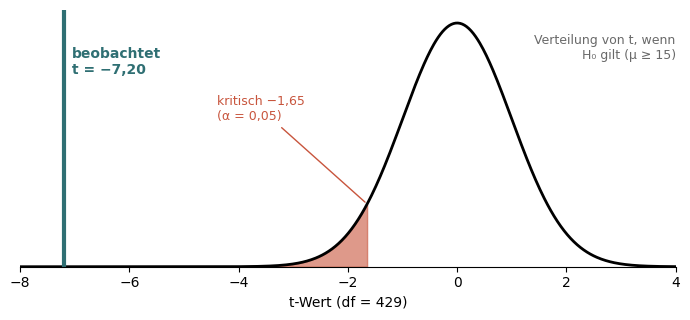

In [42]:
n = len(downtown)  # Stichprobengröße (430 Besuche am Standort Downtown)
x_bar = downtown.mean()  # Stichprobenmittelwert
s = downtown.std(ddof=1)  # Stichproben-Standardabweichung (ddof=1 = durch n-1 geteilt)
df_t = n - 1  # Freiheitsgrade des Ein-Stichproben-t-Tests
alpha = 0.05  # vorab festgelegtes Signifikanzniveau
t_krit = stats.t.ppf(alpha, df_t)  # linker kritischer Wert (einseitig, H1: mu < 15)

print(f"n = {n}, Mittelwert = {x_bar:.2f}, sd = {s:.2f}")
print(f"t = {t_stat:.3f}, p (zweiseitig) = {p_two:.13f}, p (einseitig) = {p_one:.13f}")
print(f"df = {df_t}, alpha = {alpha}, kritisches t = {t_krit:.3f}")

# ------------------------------------------------------------
# Diagramm: t-Verteilung unter H0 (df = 429), Ablehnungsbereich links und beobachtetes t
# Einseitiger Test (H1: mu < 15) -> der Ablehnungsbereich liegt nur am LINKEN Rand (Fläche = alpha = 5 %).
# ------------------------------------------------------------
# Kontrolle: Diese Werte stehen im Diagramm und im Text (assert bricht bei Abweichung ab)
assert df_t == 429  # Freiheitsgrade
assert round(t_stat, 2) == -7.20  # beobachtete Teststatistik
assert round(t_krit, 2) == -1.65  # kritischer Wert bei alpha = 0,05 (genau -1,648)
assert t_stat < t_krit  # t liegt im Ablehnungsbereich -> H0 wird verworfen

t_gitter = np.linspace(-8, 4, 600)  # x-Achse: mögliche t-Werte
dichte_t = stats.t.pdf(
    t_gitter, df_t
)  # Dichte der t-Verteilung mit 429 Freiheitsgraden

fig, ax = plt.subplots(figsize=(7.0, 3.3))
ax.plot(
    t_gitter, dichte_t, color="black", lw=2
)  # Verteilung von t, wenn H0 gilt (mu = 15)
links = t_gitter <= t_krit
ax.fill_between(
    t_gitter[links], dichte_t[links], color="#C8553D", alpha=0.6
)  # Ablehnungsbereich: die linken 5 % der Fläche
ax.axvline(t_stat, color="#2F6F73", lw=3)  # beobachteter t-Wert
ax.text(
    t_stat + 0.15,
    0.36,
    f"beobachtet\nt = {t_stat:.2f}".replace(".", ",").replace("-", "−"),
    color="#2F6F73",
    fontsize=10,
    fontweight="bold",
    va="top",
)
ax.annotate(
    f"kritisch {t_krit:.2f}\n(α = 0,05)".replace(".", ",").replace("-", "−"),
    xy=(t_krit, stats.t.pdf(t_krit, df_t)),
    xytext=(-4.4, 0.24),
    color="#C8553D",
    fontsize=9,
    arrowprops=dict(arrowstyle="-", color="#C8553D"),
)  # Beschriftung des kritischen Werts
ax.text(
    4,
    0.38,
    "Verteilung von t, wenn\nH₀ gilt (μ ≥ 15)",
    ha="right",
    va="top",
    color="dimgrey",
    fontsize=9,
)
ax.set_xlim(-8, 4)
ax.set_ylim(0, 0.42)
ax.set_yticks([])  # Dichte-Werte sind hier ohne Bedeutung, nur die Lage zählt
ax.set_xlabel(f"t-Wert (df = {df_t})")
for kante in ("top", "right", "left"):
    ax.spines[kante].set_visible(False)
plt.tight_layout()
plt.show()

**Kernaussage:** Ein t von −7,20 liegt weit im kritischen Bereich. Wenn der wahre Mittelwert bei 15 oder darüber läge, wäre ein so extremer Wert praktisch ausgeschlossen.

Beantworte die fünf Fragen unten. Jede Antwort umfasst ein oder zwei Sätze — keine Berechnung. Jede Aufgabe enthält einen Hilfe-Toggle und einen Lösung-Toggle.

## Aufgabe 1 — Was behaupten die beiden Hypothesen tatsächlich?

Formuliere beide Hypothesen ohne Symbole in normaler Sprache. Sage anschließend, welche Hypothese der Test schützt und was das für ein nicht signifikantes Ergebnis bedeutet.

Hilfe:
Ein Hypothesentest ist kein fairer Wettkampf zwischen zwei gleichberechtigten Behauptungen. Eine davon wird so lange als wahr angenommen, bis die Evidenz nur noch schwer anders zu erklären ist. Frage dich: Wenn die Daten mehrdeutig gewesen wären, welche Aussage hätte standardmäßig überlebt? Genau diese schützt der Test.

### Lösung Aufgabe 1

**Hypothesen in normaler Sprache:**
- **H0:** Das Versprechen wird nicht eingehalten – im Durchschnitt warten Patientinnen und Patienten in Downtown 15 Minuten oder länger.
- **H1:** Das Versprechen wird eingehalten – im Durchschnitt warten sie weniger als 15 Minuten.

**Was der Test schützt:** Der Test schützt **H0**; sie gilt so lange, bis die Daten nur noch schwer damit vereinbar sind. Bei einem *nicht signifikanten* Ergebnis wird H0 **vorläufig beibehalten**: Die Daten reichen nicht aus, um das Versprechen zu belegen. Es heißt **nicht**, dass das Versprechen bewiesen verfehlt wird (fehlender Beleg ist kein Beleg des Gegenteils). Bei einem *statistisch signifikanten* Ergebnis wird H0 verworfen.

In [43]:
# Beleg zu Aufgabe 1: "nicht signifikant" bedeutet NICHT "H0 ist wahr".
# Wir behandeln die 430 Downtown-Werte als "Wahrheit" (Mittelwert ca. 12,2 min, also H1 trifft zu),
# ziehen daraus viele kleine Zufalls-Stichproben (n = 15) und testen jede gegen 15.
rng = np.random.default_rng(42)  # fester Startwert -> reproduzierbare Ergebnisse
werte = downtown.to_numpy()
n_klein, n_sim = 15, 5000

signifikant = 0
for _ in range(n_sim):
    probe = rng.choice(
        werte, size=n_klein, replace=False
    )  # kleine Stichprobe ohne Zurücklegen
    p = stats.ttest_1samp(
        probe, 15, alternative="less"
    ).pvalue  # einseitiger Test wie oben
    if p < 0.05:
        signifikant += 1

print(f"Signifikant:        {signifikant / n_sim:.1%} der Stichproben")
print(f"Nicht signifikant:  {1 - signifikant / n_sim:.1%} der Stichproben")
# Ergebnis: Obwohl H1 hier tatsächlich stimmt, bleibt der Test bei kleiner Stichprobe oft "nicht signifikant".
# Ein nicht signifikantes Ergebnis ist also keine Bestätigung von H0, sondern nur fehlende Evidenz.

Signifikant:        45.8% der Stichproben
Nicht signifikant:  54.2% der Stichproben


## Aufgabe 2 — Was bedeutet das Signifikanzniveau hier?

Formuliere, was α=0.05 in diesem konkreten Test bedeutet. Sage anschließend, was sich ändern würde, wenn Operations stattdessen auf α=0.01 bestanden hätte.

Hilfe:
Das Signifikanzniveau ist eine Entscheidung, die du vor dem Blick auf die Daten triffst, keine Eigenschaft der Daten. Es ist die Fehlerrate, mit der du in einer konkreten Richtung zu leben bereit bist. Frage dich: Welchen der beiden möglichen Fehler kontrolliert es — zu behaupten, das Versprechen werde eingehalten, obwohl das nicht stimmt, oder eine echte Verbesserung zu übersehen? Wenn du das geklärt hast, folgt daraus direkt, was ein strengerer Schwellenwert bewirkt.

### Lösung Aufgabe 2

**Bedeutung von α = 0,05:** Wir akzeptieren eine Wahrscheinlichkeit von höchstens 5 %, fälschlich zu behaupten, das Versprechen werde eingehalten (Wartezeit unter 15 Minuten), obwohl die wahre Durchschnittswartezeit in Wirklichkeit 15 Minuten oder mehr beträgt (Fehler 1. Art). α kontrolliert also den Fehler „Versprechen fälschlich bestätigt" und wird vor dem Blick auf die Daten festgelegt.

**Mit α = 0,01:** Die Hürde wird strenger (kritisches t von −1,648 auf −2,335), die Evidenz muss stärker sein. Hier ändert sich die Entscheidung nicht (t = −7,20, p ≈ 1,3·10⁻¹²), aber das Risiko, eine echte Verbesserung zu übersehen (Fehler 2. Art), steigt.

In [44]:
# Beleg zu Aufgabe 2: Was kontrollieren alpha = 0,05 und alpha = 0,01?

# (a) Kritische Werte und Entscheidung bei beiden Niveaus
for a in (0.05, 0.01):
    t_k = stats.t.ppf(a, df_t)
    print(
        f"alpha = {a}: kritisches t = {t_k:.3f} | t = {t_stat:.3f} -> "
        f"{'H0 verwerfen' if t_stat < t_k else 'H0 vorläufig beibehalten'} | p_einseitig < alpha: {p_one < a}"
    )

# (b) Fehler 1. Art: Wir bauen eine Welt, in der H0 gerade noch stimmt (wahrer Mittelwert genau 15),
#     indem wir die Daten so verschieben, dass ihr Mittelwert 15 ist, und ziehen viele Stichproben (n = 430).
rng = np.random.default_rng(42)
werte_h0 = downtown.to_numpy() - (downtown.mean() - 15)
n_sim = 5000
for a in (0.05, 0.01):
    ablehnungen = sum(
        stats.ttest_1samp(
            rng.choice(werte_h0, size=n, replace=True), 15, alternative="less"
        ).pvalue
        < a
        for _ in range(n_sim)
    )
    print(
        f"Fehler 1. Art bei alpha = {a}: H0 zu Unrecht verworfen in {ablehnungen / n_sim:.1%} der Fälle"
    )
# Ergebnis: in der Nähe von 5 % bzw. 1 %, das ist es, was alpha kontrolliert. Die Raten liegen leicht
# darüber, weil die Wartezeiten stark rechtsschief sind (Schiefe ca. 2,1) und der t-Test dann etwas liberal ist.
# Mit n = 430 ist die Abweichung klein und für die Entscheidung (t = -7,2) unerheblich.

# (c) Fehler 2. Art: Wahrheit = Downtown-Daten (H1 stimmt), kleine Stichproben (n = 15)
werte = downtown.to_numpy()
for a in (0.05, 0.01):
    erkannt = sum(
        stats.ttest_1samp(
            rng.choice(werte, size=15, replace=False), 15, alternative="less"
        ).pvalue
        < a
        for _ in range(n_sim)
    )
    print(
        f"alpha = {a}: echte Verbesserung erkannt in {erkannt / n_sim:.1%} der Fälle "
        f"(übersehen: {1 - erkannt / n_sim:.1%})"
    )
# Ergebnis: Das strengere alpha = 0,01 übersieht die echte Verbesserung häufiger.

alpha = 0.05: kritisches t = -1.648 | t = -7.201 -> H0 verwerfen | p_einseitig < alpha: True
alpha = 0.01: kritisches t = -2.335 | t = -7.201 -> H0 verwerfen | p_einseitig < alpha: True
Fehler 1. Art bei alpha = 0.05: H0 zu Unrecht verworfen in 6.2% der Fälle
Fehler 1. Art bei alpha = 0.01: H0 zu Unrecht verworfen in 1.5% der Fälle
alpha = 0.05: echte Verbesserung erkannt in 44.4% der Fälle (übersehen: 55.6%)
alpha = 0.01: echte Verbesserung erkannt in 26.1% der Fälle (übersehen: 73.9%)


## Aufgabe 3 — Welche Verteilung und warum diese?

Benenne die Verteilung, aus der der p-Wert berechnet wird, und erkläre, warum es diese und nicht die Normalverteilung ist. Erkläre außerdem, welche Rolle df=429 spielt.

Hilfe:
Sieh dir an, was der Test schätzen musste. Der Stichprobenmittelwert wird mit 15 verglichen, aber der Vergleich muss danach skaliert werden, wie stark die Daten streuen — und diese Streuung war nicht im Voraus bekannt. Sie wurde aus denselben 430 Beobachtungen berechnet. Diese zusätzliche Unsicherheit muss irgendwo berücksichtigt werden.

### Lösung Aufgabe 3

**Verteilung:** Der p-Wert stammt aus der **t-Verteilung** (Student-t) mit 429 Freiheitsgraden, nicht aus der Normalverteilung. Der Grund: Die Standardabweichung der Wartezeiten ist nicht im Voraus bekannt, sondern wurde aus denselben 430 Beobachtungen geschätzt. Diese zusätzliche Unsicherheit macht die Teststatistik breiter und mit schwereren Rändern als eine Normalverteilung.

**Rolle von df = 429:** Die Freiheitsgrade (n − 1) geben an, wie viel unabhängige Information in die Schätzung der Streuung einfloss (ein Freiheitsgrad geht für den Mittelwert „verloren"). Sie bestimmen die Form der t-Verteilung: je weniger Freiheitsgrade, desto schwerere Ränder. Bei 429 ist die t-Verteilung der Normalverteilung schon sehr ähnlich, deshalb ändert sich hier die Entscheidung nicht, bei kleinen Stichproben wäre der Unterschied wichtig.

In [45]:
# Beleg zu Aufgabe 3: Warum t- und nicht Normalverteilung, und was macht df?

# (a) Die t-Statistik von Hand: (Mittelwert - 15) geteilt durch den Standardfehler s / Wurzel(n)
standardfehler = s / np.sqrt(n)
t_manuell = (x_bar - 15) / standardfehler
print(f"t von Hand = {t_manuell:.4f}  |  t von scipy = {t_stat:.4f}")

# (b) p-Wert einseitig aus der t-Verteilung (df = 429) und zum Vergleich aus der Normalverteilung
p_t = stats.t.cdf(t_manuell, df_t)  # Fläche links von t unter der t-Verteilung
p_norm = stats.norm.cdf(t_manuell)  # Fläche links von t unter der Normalverteilung
print(
    f"p aus t-Verteilung:      {p_t:.3e}   (identisch mit p_one: {np.isclose(p_t, p_one)})"
)
print(
    f"p aus Normalverteilung:  {p_norm:.3e}   -> kleiner, die Normalverteilung ist hier zu optimistisch"
)

# (c) Rolle der Freiheitsgrade: kritischer Wert bei alpha = 0,05 (einseitig)
print("\nKritischer Wert (alpha = 0,05, einseitig):")
for k in (5, 10, 30, 429):
    print(f"  t-Verteilung, df = {k:>3}: {stats.t.ppf(0.05, k):.3f}")
print(f"  Normalverteilung        : {stats.norm.ppf(0.05):.3f}")
# Ergebnis: Je kleiner df, desto weiter außen liegt die Schwelle (schwerere Ränder).
# Bei df = 429 liegt sie fast bei der Normalverteilung (-1,648 gegen -1,645).

t von Hand = -7.2010  |  t von scipy = -7.2010
p aus t-Verteilung:      1.349e-12   (identisch mit p_one: True)
p aus Normalverteilung:  2.988e-13   -> kleiner, die Normalverteilung ist hier zu optimistisch

Kritischer Wert (alpha = 0,05, einseitig):
  t-Verteilung, df =   5: -2.015
  t-Verteilung, df =  10: -1.812
  t-Verteilung, df =  30: -1.697
  t-Verteilung, df = 429: -1.648
  Normalverteilung        : -1.645


## Aufgabe 4 — Ein Rand oder zwei, und warum?

Der Code teilt den zweiseitigen p-Wert durch 2. Erkläre, warum für diese Frage ein Rand die richtige Wahl ist und was daran falsch gewesen wäre, stattdessen den zweiseitigen p-Wert zu berichten. Nenne anschließend die eine Bedingung, unter der die Division durch 2 zu einer stark falschen Antwort geführt hätte.

Hilfe:
Lies die Alternativhypothese noch einmal. Sagt sie, dass sich der Mittelwert von 15 unterscheidet, oder dass er kleiner als 15 ist? Ein Test darf nur Evidenz in der Richtung zählen, in die seine Alternative gezeigt hat — und diese Richtung muss festgestanden haben, bevor die Daten eingetroffen sind. Denke dann an den Halbierungs-Trick: Er teilt den p-Wert gleichmäßig auf zwei Ränder auf. Was passiert, wenn der Stichprobenmittelwert auf der anderen Seite von 15 gelandet wäre?

### Lösung Aufgabe 4

**Warum ein Rand:** Die Alternativhypothese ist gerichtet (μ < 15), und Operations will wissen, ob die Wartezeit *unter* 15 Minuten liegt. Nur ein Mittelwert unterhalb von 15 würde das Versprechen stützen. Deshalb zählt der Test nur Evidenz am linken Rand. Der zweiseitige p-Wert (≈ 2,7·10⁻¹²) beantwortet eine andere Frage („unterscheidet sich μ von 15?"), zählt auch Abweichungen nach oben und würde auch bei längerer Wartezeit „signifikant" melden. Er ist doppelt so groß und beantwortet die falsche Frage.

**Die eine Bedingung:** Die Division durch 2 stimmt nur, wenn die Teststatistik auf der Seite von H1 liegt (hier t < 0, also Stichprobenmittelwert < 15), und die Richtung muss vorher festgestanden haben. Läge der Mittelwert auf der anderen Seite von 15, wäre p_zweiseitig / 2 immer noch winzig, obwohl die Daten gegen H1 sprechen, und der korrekte einseitige p-Wert läge nahe bei 1.

In [46]:
# Beleg zu Aufgabe 4: Ein Rand statt zwei, und wann die Halbierung versagt.

# (a) Einseitiger p-Wert auf drei Wegen: Halbierung, t-Verteilung, scipy-Argument "alternative"
p_halbiert = p_two / 2
p_cdf = stats.t.cdf(t_stat, df_t)
p_scipy = stats.ttest_1samp(downtown, 15, alternative="less").pvalue
print(
    f"zweiseitig: {p_two:.3e} | einseitig halbiert: {p_halbiert:.3e} | "
    f"cdf: {p_cdf:.3e} | scipy: {p_scipy:.3e}"
)

# (b) Gegenbeispiel: Wir spiegeln die Daten, sodass der Mittelwert ÜBER 15 liegt (Wartezeit deutlich zu lang).
#     Die Verteilung bleibt gleich (gleiche Streuung), nur die Richtung dreht sich.
gespiegelt = 30 - downtown
t_g, p_two_g = stats.ttest_1samp(gespiegelt, 15)
print(f"\nGespiegelte Daten: Mittelwert = {gespiegelt.mean():.2f} min, t = {t_g:.3f}")
print(
    f"  falsch (p_zweiseitig / 2):                {p_two_g / 2:.3e}   -> sähe 'statistisch signifikant' aus"
)
print(
    f"  richtig (alternative='less'):             {stats.ttest_1samp(gespiegelt, 15, alternative='less').pvalue:.6f}   -> praktisch 1"
)
# Ergebnis: Ist t nicht auf der Seite von H1, führt die Halbierung zu einer stark falschen Antwort.
# Darum steht im Code der Kommentar "t_stat is on the H1 side".

zweiseitig: 2.699e-12 | einseitig halbiert: 1.349e-12 | cdf: 1.349e-12 | scipy: 1.349e-12

Gespiegelte Daten: Mittelwert = 17.82 min, t = 7.201
  falsch (p_zweiseitig / 2):                1.349e-12   -> sähe 'statistisch signifikant' aus
  richtig (alternative='less'):             1.000000   -> praktisch 1


## Aufgabe 5 — Den p-Wert interpretieren und die Schlussfolgerung formulieren

Formuliere in einem präzisen Satz, was =p=0.0000000000013 bedeutet. Gib anschließend die Schlussfolgerung an, die Operations mitgeteilt werden sollte — einschließlich dessen, was der p-Wert ihnen nicht sagt.

Hilfe:
Ein p-Wert ist eine bedingte Wahrscheinlichkeit, und die Bedingung richtig zu benennen ist die gesamte Übung. Er beginnt mit einer Annahme. Mit welcher? Und wovon ist er genau die Wahrscheinlichkeit — vom beobachteten Ergebnis oder von etwas Umfassenderem? Danach getrennt: Dieser p-Wert ist astronomisch klein. Sagt seine Kleinheit irgendetwas darüber aus, wie groß die Verbesserung ist?

### Lösung Aufgabe 5

**Bedeutung von p = 0,0000000000013:** Wenn die wahre durchschnittliche Wartezeit in Downtown genau 15 Minuten betrüge (der Grenzfall von H0), läge die Wahrscheinlichkeit, einen Stichprobenmittelwert von 12,18 Minuten oder einen noch extremeren Wert nach unten zu beobachten, bei etwa 1,3 zu einer Billion.

**Schlussfolgerung für Operations:** Das Ergebnis ist statistisch signifikant (α = 0,05): Die Nullhypothese (mittlere Wartezeit in Downtown 15 Minuten oder mehr) wird verworfen. Die Daten dieses Quartals sind mit dieser Nullhypothese kaum vereinbar und stützen das Versprechen. Das Stichprobenmittel liegt bei 12,2 Minuten, das zweiseitige 95-%-Konfidenzintervall bei 11,41 bis 12,95 Minuten (also nicht beim Wert 15). Für den linksseitigen Test ist außerdem die einseitige 95-%-Obergrenze von **12,82 Minuten** maßgeblich: Auch sie liegt unter 15 Minuten und passt zur Verwerfung von H₀. Der p-Wert sagt **nicht**, wie groß die Verbesserung ist (rund 2,8 Minuten unter 15, ein kleiner bis mittlerer Effekt), nicht, wie wahrscheinlich H0 ist, nicht, dass jede einzelne Person unter 15 Minuten wartet, und nichts über künftige Quartale.

In [47]:
# Beleg zu Aufgabe 5: Was der p-Wert sagt und was nicht.

# (a) Das Versprechen betrifft den DURCHSCHNITT. Der p-Wert sagt nichts über die Größe der Verbesserung,
#     dafür brauchen wir Effektgröße und Konfidenzintervall.
differenz = x_bar - 15
ki_unten, ki_oben = stats.t.interval(
    0.95, df_t, loc=x_bar, scale=standardfehler
)  # 95-%-Konfidenzintervall
cohen_d = differenz / s  # standardisierte Effektgröße
print(f"Mittelwert: {x_bar:.2f} min | Differenz zu 15: {differenz:.2f} min")
print(f"95-%-Konfidenzintervall für mu: [{ki_unten:.2f}; {ki_oben:.2f}] min")
# Einseitige 95-%-Obergrenze (passt zum linksseitigen Test H1: mu < 15): Mittelwert + t(0,95; df) * Standardfehler
ki_ober_einseitig = x_bar + stats.t.ppf(0.95, df_t) * standardfehler
print(
    f"Einseitige 95-%-Obergrenze für mu: {ki_ober_einseitig:.2f} min  (liegt unter 15 -> passt zur Verwerfung von H0 bei alpha = 0,05)"
)
assert round(ki_ober_einseitig, 2) == 12.82 and ki_ober_einseitig < 15
print(
    f"Cohen's d = {cohen_d:.2f}  (klein bis mittel: |d| = 0,2 klein, 0,5 mittel, 0,8 groß)"
)

# (b) Der Mittelwert sagt nichts über einzelne Besuche: Anteil der Besuche über 15 Minuten
anteil_ueber_15 = (downtown > 15).mean()
print(
    f"\nAnteil der Besuche mit mehr als 15 min Wartezeit: {anteil_ueber_15:.1%} (Median: {downtown.median():.2f} min)"
)
# Das Versprechen gilt im Durchschnitt, trotzdem warten viele einzelne Patientinnen und Patienten länger als 15 Minuten.

# (c) Der p-Wert ist KEINE Wahrscheinlichkeit für H0. Er beginnt mit der Annahme "mu = 15":
#     Wir simulieren diese Welt und zählen, wie oft eine t-Statistik <= beobachtetes t vorkommt.
rng = np.random.default_rng(42)
werte_h0 = downtown.to_numpy() - (x_bar - 15)  # Welt, in der mu genau 15 ist
n_sim = 20000
t_sim = np.array(
    [
        stats.ttest_1samp(rng.choice(werte_h0, size=n, replace=True), 15).statistic
        for _ in range(n_sim)
    ]
)
print(
    f"\nIn {n_sim} simulierten H0-Welten war t <= {t_stat:.2f} in {(t_sim <= t_stat).sum()} Fällen "
    f"(theoretischer p-Wert: {p_one:.1e} -> bei 20000 Läufen praktisch nie zu erwarten)."
)
print(
    f"Zum Vergleich: kritisches t <= {t_krit:.3f} kam in {(t_sim <= t_krit).mean():.1%} der Läufe vor (erwartet ca. 5 %, leicht darüber wegen der Rechtsschiefe der Daten)."
)

# (d) Entscheidungssatz aus dem Code erzeugen: Die Formulierung folgt dem Ergebnis, nicht umgekehrt.
#     p_one und alpha stammen aus den Zellen oben; ki_unten/ki_oben aus (a).
if p_one < alpha:
    satz = (
        f"Statistisch signifikant (p = {p_one:.1e} < alpha = {alpha}): "
        f"Die Nullhypothese (mu >= 15) wird verworfen."
    )
else:
    satz = (
        f"Nicht signifikant (p = {p_one:.3f} >= alpha = {alpha}): "
        f"Die Nullhypothese (mu >= 15) wird vorläufig beibehalten."
    )
print("\n" + satz)
print(
    f"Stichprobenmittel {x_bar:.2f} min, 95-%-KI [{ki_unten:.2f}; {ki_oben:.2f}] -> "
    f"15 liegt {'außerhalb' if not (ki_unten <= 15 <= ki_oben) else 'innerhalb'} des Intervalls."
)

Mittelwert: 12.18 min | Differenz zu 15: -2.82 min
95-%-Konfidenzintervall für mu: [11.41; 12.95] min
Einseitige 95-%-Obergrenze für mu: 12.82 min  (liegt unter 15 -> passt zur Verwerfung von H0 bei alpha = 0,05)
Cohen's d = -0.35  (klein bis mittel: |d| = 0,2 klein, 0,5 mittel, 0,8 groß)

Anteil der Besuche mit mehr als 15 min Wartezeit: 27.9% (Median: 10.39 min)

In 20000 simulierten H0-Welten war t <= -7.20 in 0 Fällen (theoretischer p-Wert: 1.3e-12 -> bei 20000 Läufen praktisch nie zu erwarten).
Zum Vergleich: kritisches t <= -1.648 kam in 6.0% der Läufe vor (erwartet ca. 5 %, leicht darüber wegen der Rechtsschiefe der Daten).

Statistisch signifikant (p = 1.3e-12 < alpha = 0.05): Die Nullhypothese (mu >= 15) wird verworfen.
Stichprobenmittel 12.18 min, 95-%-KI [11.41; 12.95] -> 15 liegt außerhalb des Intervalls.


---
## Antworten zur Projektabgabe – Checkpoint 2 (Kurzfassung in Alltagssprache)

Die Projektabgabe verlangt zu Checkpoint 2 kurze Antworten ohne Formeln und ohne unerklärte Symbole. Sie stehen hier **an einer Stelle**. Die ausführliche Begründung und der Code stehen in den Aufgaben 1 bis 5 oben. Jede Zahl wird in der Code-Zelle darunter aus den Daten neu berechnet.

#### 1. Die beiden Hypothesen (Aufgabe 1)

Die Nullhypothese sagt: Das Serviceversprechen wird nicht eingehalten, die Patienten in Downtown warten im Durchschnitt 15 Minuten oder länger. Die Alternativhypothese sagt: Das Versprechen wird eingehalten, im Durchschnitt wird weniger als 15 Minuten gewartet.

#### 2. Welche Hypothese der Test schützt (Aufgabe 1)

Der Test schützt die **Nullhypothese**. Sie wird nur verworfen, wenn die Daten kaum noch mit ihr vereinbar sind. Reichen die Daten dafür nicht aus, bleibt sie vorläufig bestehen. Das heißt nicht, dass bewiesen wäre, dass das Versprechen verfehlt wird, sondern nur: Der Beleg fehlt. Die Simulation mit kleinen Stichproben in Aufgabe 1 zeigt das, denn dort bleibt der Test trotz echter Verbesserung oft nicht signifikant.

#### 3. Was das Signifikanzniveau von 5 % bedeutet und was sich bei 1 % ändert (Aufgabe 2)

Wir legen vor der Auswertung fest, dass der Test höchstens in 5 von 100 Fällen fälschlich melden darf, das Versprechen werde eingehalten, obwohl die wahre Durchschnittswartezeit 15 Minuten oder mehr beträgt. Bei 1 % ist die Hürde höher: Der t-Wert (die Teststatistik) muss weiter unten liegen, nämlich unter −2,335 statt unter −1,648. Hier ändert sich die Entscheidung nicht, denn der beobachtete t-Wert liegt bei −7,20, der Test ist auch bei 1 % statistisch signifikant. Der Preis eines strengeren Niveaus: Eine echte Verbesserung wird häufiger übersehen.

#### 4. Die Verteilung und die Freiheitsgrade (Aufgabe 3)

Der p-Wert stammt aus der **t-Verteilung** (Student-t) mit 429 Freiheitsgraden, nicht aus der Normalverteilung. Die Streuung der Wartezeiten kennen wir nicht im Voraus, wir schätzen sie aus denselben 430 Besuchen. Diese zusätzliche Unsicherheit macht die Verteilung breiter, mit schwereren Rändern. Die 429 Freiheitsgrade sind die 430 Besuche minus 1, weil ein Freiheitsgrad für den Mittelwert verbraucht wird. Sie geben an, wie viel unabhängige Information in die Schätzung der Streuung eingeht. Bei 429 ist die t-Verteilung der Normalverteilung fast gleich (kritischer Wert −1,648 gegenüber −1,645). Bei kleinen Stichproben wäre der Unterschied wichtig.

#### 5. Warum der Test einseitig ist und der zweiseitige p-Wert nicht passt (Aufgabe 4)

Die Frage lautet nicht, ob die Wartezeit von 15 Minuten abweicht, sondern ob sie **darunter** liegt. Nur ein Mittelwert unter 15 Minuten würde das Versprechen stützen. Die Richtung steht damit durch die Fragestellung fest, bevor die Daten angesehen werden. Der zweiseitige p-Wert (rund 2,7 zu einer Billion) beantwortet eine andere Frage, nämlich ob die Wartezeit überhaupt von 15 Minuten abweicht. Er zählt auch Abweichungen nach oben mit und würde bei zu langer Wartezeit ebenfalls „signifikant“ melden. Deshalb passt er nicht zum vorab festgelegten einseitigen Test. Er ist doppelt so groß und beantwortet die falsche Frage.

#### 6. Zusatz: Was der p-Wert bedeutet und was Operations mitgeteilt wird (Aufgabe 5)

Wäre die wahre Durchschnittswartezeit genau 15 Minuten, wäre ein Stichprobenmittel von 12,2 Minuten oder weniger äußerst unwahrscheinlich (etwa 1,3 zu einer Billion). Das Ergebnis ist **statistisch signifikant**, die Nullhypothese wird verworfen: Die Daten dieses Quartals stützen das Versprechen im Durchschnitt (12,2 Minuten, mit den Daten vereinbar sind 11,41 bis 12,95 Minuten). Der p-Wert sagt **nicht**, wie wahrscheinlich die Nullhypothese ist, und nicht, dass jede einzelne Person unter 15 Minuten wartet (28 % warten länger). Über künftige Quartale sagt er nichts.


In [48]:
# ------------------------------------------------------------
# Prüfung der Zahlen in den Kurzantworten zu Checkpoint 2
# Alles, was im Text oben steht, wird hier aus den Daten neu berechnet (assert bricht bei Abweichung ab).
# ------------------------------------------------------------
dt2 = df[df["clinic_site"] == "Downtown"][
    "wait_time_min"
].dropna()  # Wartezeiten Downtown (bereinigte Datenbasis)
n2 = len(dt2)
t2, p_zwei = stats.ttest_1samp(dt2, 15)
p_ein = (
    p_zwei / 2
)  # t liegt auf der Seite von H1 (Mittelwert < 15), deshalb ist die Halbierung hier zulässig

# (3) Signifikanzniveau: kritische Werte bei 5 % und 1 %, beobachteter t-Wert
assert n2 == 430 and n2 - 1 == 429  # 430 Besuche, 429 Freiheitsgrade
assert (
    round(stats.t.ppf(0.05, n2 - 1), 3) == -1.648
    and round(stats.t.ppf(0.01, n2 - 1), 3) == -2.335
)
assert round(t2, 2) == -7.20 and t2 < stats.t.ppf(
    0.01, n2 - 1
)  # auch bei 1 % verwerfen

# (4) Verteilung: kritischer Wert t-Verteilung gegen Normalverteilung
assert round(stats.norm.ppf(0.05), 3) == -1.645

# (5) und (6): zweiseitiger und einseitiger p-Wert, Mittelwert, Intervall, Anteil über 15 Minuten
assert (
    abs(p_zwei - 2.7e-12) < 0.05e-12 and abs(p_ein - 1.3e-12) < 0.1e-12
)  # "2,7 bzw. 1,3 zu einer Billion"
assert round(dt2.mean(), 1) == 12.2
lo2, hi2 = stats.t.interval(0.95, n2 - 1, loc=dt2.mean(), scale=stats.sem(dt2))
assert round(lo2, 2) == 11.41 and round(hi2, 2) == 12.95
assert round(100 * (dt2 > 15).mean()) == 28

print("Alle Zahlen in den Kurzantworten zu Checkpoint 2 stimmen mit den Daten überein.")
print(
    f"n = {n2}, t = {t2:.2f}, p einseitig = {p_ein:.2e}, p zweiseitig = {p_zwei:.2e}, 95-%-Intervall [{lo2:.2f}; {hi2:.2f}]"
)

Alle Zahlen in den Kurzantworten zu Checkpoint 2 stimmen mit den Daten überein.
n = 430, t = -7.20, p einseitig = 1.35e-12, p zweiseitig = 2.70e-12, 95-%-Intervall [11.41; 12.95]


# Checkpoint 3 – Einen zweiseitigen Vergleich lesen

**Sprint 3: Fehler, Teststärke und statistische Entscheidungen**

**Ausgangslage:** Der Standortleiter von Riverside behauptet, dass die Patienten in Riverside nicht länger warten als in Downtown und dass jede sichtbare Differenz nur Rauschen aus einer kleineren Stichprobe sei. Regional Operations will das klären, bevor zwei Mitarbeitende versetzt werden.

**Aufgabe:** Die Analyse ist bereits durchgeführt – wir *lesen* sie. Die vorgegebenen Hypothesen:

- H0: μR = μD – beide Standorte haben dieselbe wahre mittlere Wartezeit.
- H1: μR ≠ μD – die wahren mittleren Wartezeiten unterscheiden sich.

**Arbeitsweise in diesem Notebook:** Zu jeder Aufgabe gibt es (1) den Aufgabentext, (2) den **Hilfe**-Teil, (3) Code, der jede Behauptung aus der Antwort *nachprüft*, und (4) die **Lösung** in ganzen Sätzen. Wo im Text etwas behauptet wird (z. B. „der gepoolte Test verzerrt die Fehlerquote"), steht direkt darüber oder darunter der Code, der es belegt.

**Bezug zu Checkpoint 1:** Die Bereinigungsregeln stammen von dort (nur exakte Duplikate entfernen; no-show-Besuche mit Wartezeit sind ein Widerspruch und werden als Variante mitgeführt). Die vorgegebene Ausgabe der Aufgabe wird zuerst auf den Rohdaten exakt reproduziert (Teil 0.2 und 0.3). Alle weiteren Auswertungen laufen auf der bereinigten Datenbasis (Teil 0.4, ohne die 9 exakten Duplikate); die weiteren Bereinigungsvarianten stehen als Robustheitsprüfung in Teil 0.

In [49]:
# ------------------------------------------------------------
# Checkpoint-3-Setup: Zufalls-Startwert und Ausgabeformat (Bibliotheken, ALPHA und Daten: zentrales Setup oben)
# ------------------------------------------------------------
rng = np.random.default_rng(42)  # fester Seed -> Simulationen sind reproduzierbar
pd.reset_option("display.float_format")  # Format aus Checkpoint 1 zurücksetzen
pd.set_option("display.precision", 4)  # Tabellen mit 4 Nachkommastellen

## Teil 0 – Daten laden und die vorgegebene Ausgabe nachbauen

Bevor wir die Analyse *lesen*, prüfen wir, ob wir sie mit unseren Daten exakt reproduzieren können. Stimmen die Zahlen nicht, wäre jede Interpretation wertlos.

### 0.1 Rohdaten kurz inspizieren

In [50]:
# ------------------------------------------------------------
# 0.1  Rohdaten kurz inspizieren (die Aufgabe liefert ihre Ausgabe auf den ROHDATEN)
# ------------------------------------------------------------
print("Zeilen, Spalten (roh):", df_roh.shape)
print("Standorte:", df_roh["clinic_site"].unique().tolist())
print("Fehlende Werte in wait_time_min:", df_roh["wait_time_min"].isna().sum())

# Datenqualität (wie in Checkpoint 1): Doppelte Besuche?
print("\nDoppelte visit_id:", df_roh["visit_id"].duplicated().sum())
print("Komplett identische Zeilen:", df_roh.duplicated().sum())
print("Doppelte Besuche je Standort:")
print(df_roh[df_roh["visit_id"].duplicated()]["clinic_site"].value_counts())

Zeilen, Spalten (roh): (1209, 14)
Standorte: ['Downtown', 'Northgate', 'Eastview', 'Riverside']
Fehlende Werte in wait_time_min: 0

Doppelte visit_id: 9
Komplett identische Zeilen: 9
Doppelte Besuche je Standort:
clinic_site
Riverside    4
Northgate    3
Eastview     2
Name: count, dtype: int64


### 0.2 Die Analyse aus der Aufgabe

In [51]:
# ------------------------------------------------------------
# 0.2  Die Analyse aus der Aufgabe, 1:1 übernommen (auf den Rohdaten)
# ------------------------------------------------------------
riverside = df_roh[df_roh["clinic_site"] == "Riverside"]["wait_time_min"].dropna()
downtown = df_roh[df_roh["clinic_site"] == "Downtown"]["wait_time_min"].dropna()

# equal_var=False  ->  Welch-Test (Details in Aufgabe 2)
t_stat, p_value = stats.ttest_ind(riverside, downtown, equal_var=False)

# Kennzahlen, die wir später immer wieder brauchen
n_r, n_d = len(riverside), len(downtown)
m_r, m_d = riverside.mean(), downtown.mean()
s_r, s_d = riverside.std(ddof=1), downtown.std(
    ddof=1
)  # ddof=1 -> Stichproben-Standardabweichung
diff = m_r - m_d  # beobachtete Mittelwertdifferenz

# Zusätzlich nötig für die Zeilen "95% CI" und "Cohen's d" der erwarteten Ausgabe
# (im Originalcode der Aufgabe werden sie NICHT berechnet):
v_r, v_d = s_r**2 / n_r, s_d**2 / n_d  # Varianz der Mittelwerte je Gruppe
se_welch = np.sqrt(v_r + v_d)  # Standardfehler der Differenz
df_welch = (v_r + v_d) ** 2 / (
    v_r**2 / (n_r - 1) + v_d**2 / (n_d - 1)
)  # Welch-Satterthwaite-Freiheitsgrade
t_krit_zwei = stats.t.ppf(1 - ALPHA / 2, df_welch)  # kritischer t-Wert, zweiseitig
ci_low, ci_high = (
    diff - t_krit_zwei * se_welch,
    diff + t_krit_zwei * se_welch,
)  # 95-%-KI der Differenz
sp = np.sqrt(
    ((n_r - 1) * s_r**2 + (n_d - 1) * s_d**2) / (n_r + n_d - 2)
)  # gepoolte Standardabweichung
cohens_d = diff / sp  # Effektgröße

# Ausgabe im Format der "erwarteten Ausgabe" aus der Aufgabenstellung
print(f"Riverside   n = {n_r}    mean = {m_r:.2f}    sd = {s_r:.2f}")
print(f"Downtown    n = {n_d}    mean = {m_d:.2f}    sd = {s_d:.2f}")
print()
print(f"difference = {diff:.2f} minutes")
print(
    f"t = {t_stat:.2f}        p (two-tailed) = {p_value:.38f}"
)  # 38 Nachkommastellen wie in der Aufgabe
print(f"95% CI for the difference = {ci_low:.2f} to {ci_high:.2f} minutes")
print(f"Cohen's d = {cohens_d:.2f}        alpha = {ALPHA}")

Riverside   n = 290    mean = 20.72    sd = 8.45
Downtown    n = 430    mean = 12.18    sd = 8.12

difference = 8.54 minutes
t = 13.51        p (two-tailed) = 0.00000000000000000000000000000000000155
95% CI for the difference = 7.30 to 9.78 minutes
Cohen's d = 1.03        alpha = 0.05


### 0.3 Abgleich mit den Zahlen aus der Aufgabenstellung

In [52]:
# ------------------------------------------------------------
# 0.3  Abgleich mit den Zahlen aus der Aufgabenstellung
#      (assert bricht mit Fehler ab, wenn etwas NICHT stimmt)
# ------------------------------------------------------------
assert (n_r, n_d) == (290, 430)
assert round(m_r, 2) == 20.72 and round(m_d, 2) == 12.18
assert round(s_r, 2) == 8.45 and round(s_d, 2) == 8.12
assert round(diff, 2) == 8.54
assert round(t_stat, 2) == 13.51
assert 1.5e-36 < p_value < 1.6e-36
assert round(ci_low, 2) == 7.30 and round(ci_high, 2) == 9.78  # 95-%-KI laut Aufgabe
assert round(cohens_d, 2) == 1.03  # Cohen's d laut Aufgabe
print("Alle Kennzahlen stimmen mit der Aufgabenstellung überein.")


# ------------------------------------------------------------
# Robustheit: Wirkung der Bereinigung (Regeln aus Checkpoint 1)
#   (a) roh                            = Analyse der Aufgabe
#   (b) ohne exakte Duplikate          = df.drop_duplicates() (alle Spalten identisch, 9 Zeilen)
#   (c) zusätzlich ohne no-show        = no-show-Besuche haben trotzdem eine Wartezeit (Widerspruch aus Checkpoint 1)
#   (d) zusätzlich ohne Wartezeit-Ausreißer (Tukey-Regel: Q3 + 1,5 x IQR, Quartile aus (b))
# ------------------------------------------------------------
def welch_zusammenfassung(daten, label):
    """Welch-Test Riverside gegen Downtown für eine Datenvariante: n, Differenz, t, p und 95-%-KI."""
    r_ = daten[daten["clinic_site"] == "Riverside"]["wait_time_min"].dropna()
    d_ = daten[daten["clinic_site"] == "Downtown"]["wait_time_min"].dropna()
    res = stats.ttest_ind(r_, d_, equal_var=False)
    dif = r_.mean() - d_.mean()
    vr, vd = r_.var(ddof=1) / len(r_), d_.var(ddof=1) / len(d_)
    se_ = np.sqrt(vr + vd)
    dfw = (vr + vd) ** 2 / (vr**2 / (len(r_) - 1) + vd**2 / (len(d_) - 1))
    tk = stats.t.ppf(1 - ALPHA / 2, dfw)
    return {
        "Variante": label,
        "n Riverside": len(r_),
        "n Downtown": len(d_),
        "Differenz (Min.)": round(dif, 2),
        "t": round(res.statistic, 2),
        "p": f"{res.pvalue:.2g}",
        "95-%-KI": f"[{dif - tk * se_:.2f}; {dif + tk * se_:.2f}]",
    }


df_b = df_roh.drop_duplicates()  # (b) CP1-Regel: nur exakte Duplikate entfernen
df_c = df_b[df_b["no_show"] == 0]  # (c) ohne no-show
q1, q3 = df_b["wait_time_min"].quantile([0.25, 0.75])
zaun = q3 + 1.5 * (q3 - q1)  # oberer Zaun der Tukey-Regel
print(
    f"Wartezeit-Ausreißer nach 1,5 x IQR (Zaun {zaun:.2f} Min.): roh {(df_roh['wait_time_min'] > zaun).sum()} "
    f"| ohne Duplikate {(df_b['wait_time_min'] > zaun).sum()}   (Checkpoint 1: 34 roh bzw. 32 ohne Duplikate)"
)
df_d = df_c[df_c["wait_time_min"] <= zaun]  # (d) zusätzlich ohne Ausreißer

robust = pd.DataFrame(
    [
        welch_zusammenfassung(df_roh, "(a) roh (Analyse der Aufgabe)"),
        welch_zusammenfassung(df_b, "(b) ohne exakte Duplikate"),
        welch_zusammenfassung(df_c, "(c) zusätzlich ohne no-show"),
        welch_zusammenfassung(df_d, "(d) zusätzlich ohne Ausreißer"),
    ]
)
print()
print(robust.to_string(index=False))
print(
    "\n-> In allen Varianten: gleiche Richtung, Differenz zwischen etwa 8 und 9 Min., KI enthält 0 nicht."
)

Alle Kennzahlen stimmen mit der Aufgabenstellung überein.
Wartezeit-Ausreißer nach 1,5 x IQR (Zaun 35.77 Min.): roh 34 | ohne Duplikate 32   (Checkpoint 1: 34 roh bzw. 32 ohne Duplikate)

                     Variante  n Riverside  n Downtown  Differenz (Min.)     t       p       95-%-KI
(a) roh (Analyse der Aufgabe)          290         430              8.54 13.51 1.6e-36  [7.30; 9.78]
    (b) ohne exakte Duplikate          286         430              8.58 13.56   1e-36  [7.33; 9.82]
  (c) zusätzlich ohne no-show          259         380              8.83 13.07 4.3e-34 [7.51; 10.16]
(d) zusätzlich ohne Ausreißer          243         372              8.14 15.11 9.3e-43  [7.08; 9.20]

-> In allen Varianten: gleiche Richtung, Differenz zwischen etwa 8 und 9 Min., KI enthält 0 nicht.


### 0.4 Hauptanalyse auf der bereinigten Datenbasis

Ab hier rechnen wir mit `df` (ohne die exakten Duplikate). Die Variablen `riverside`, `downtown`, `n_r`, `diff`, `ci_low`, … werden überschrieben. Alle folgenden Aufgaben und Simulationen beziehen sich daher auf die **bereinigte** Analyse. Die Rohdaten-Analyse aus 0.2 bleibt nur als Nachweis stehen, dass wir die vorgegebene Ausgabe der Aufgabe exakt reproduzieren. Der Unterschied ist klein (vier der neun Duplikate liegen in Riverside), aber er ist sichtbar, und er ist bei den Zahlen unten immer gemeint.

In [53]:
# ------------------------------------------------------------
# 0.2  Die Analyse aus der Aufgabe, 1:1 übernommen
# ------------------------------------------------------------
riverside = df[df["clinic_site"] == "Riverside"]["wait_time_min"].dropna()
downtown = df[df["clinic_site"] == "Downtown"]["wait_time_min"].dropna()

# equal_var=False  ->  Welch-Test (Details in Aufgabe 2)
t_stat, p_value = stats.ttest_ind(riverside, downtown, equal_var=False)

# Kennzahlen, die wir später immer wieder brauchen
n_r, n_d = len(riverside), len(downtown)
m_r, m_d = riverside.mean(), downtown.mean()
s_r, s_d = riverside.std(ddof=1), downtown.std(
    ddof=1
)  # ddof=1 -> Stichproben-Standardabweichung
diff = m_r - m_d  # beobachtete Mittelwertdifferenz

# Zusätzlich nötig für die Zeilen "95% CI" und "Cohen's d" der erwarteten Ausgabe
# (im Originalcode der Aufgabe werden sie NICHT berechnet):
v_r, v_d = s_r**2 / n_r, s_d**2 / n_d  # Varianz der Mittelwerte je Gruppe
se_welch = np.sqrt(v_r + v_d)  # Standardfehler der Differenz
df_welch = (v_r + v_d) ** 2 / (
    v_r**2 / (n_r - 1) + v_d**2 / (n_d - 1)
)  # Welch-Satterthwaite-Freiheitsgrade
t_krit_zwei = stats.t.ppf(1 - ALPHA / 2, df_welch)  # kritischer t-Wert, zweiseitig
ci_low, ci_high = (
    diff - t_krit_zwei * se_welch,
    diff + t_krit_zwei * se_welch,
)  # 95-%-KI der Differenz
sp = np.sqrt(
    ((n_r - 1) * s_r**2 + (n_d - 1) * s_d**2) / (n_r + n_d - 2)
)  # gepoolte Standardabweichung
cohens_d = diff / sp  # Effektgröße

# Ausgabe im Format der "erwarteten Ausgabe" aus der Aufgabenstellung
print(f"Riverside   n = {n_r}    mean = {m_r:.2f}    sd = {s_r:.2f}")
print(f"Downtown    n = {n_d}    mean = {m_d:.2f}    sd = {s_d:.2f}")
print()
print(f"difference = {diff:.2f} minutes")
print(
    f"t = {t_stat:.2f}        p (two-tailed) = {p_value:.38f}"
)  # 38 Nachkommastellen wie in der Aufgabe
print(f"95% CI for the difference = {ci_low:.2f} to {ci_high:.2f} minutes")
print(f"Cohen's d = {cohens_d:.2f}        alpha = {ALPHA}")

# Abgleich: Die bereinigte Hauptanalyse (nach Entfernen exakter Duplikate)
assert (n_r, n_d) == (286, 430)
assert round(m_r, 2) == 20.76 and round(m_d, 2) == 12.18
assert round(diff, 2) == 8.58 and round(t_stat, 2) == 13.56
assert round(df_welch, 2) == 596.78 and 1.0e-36 < p_value < 1.1e-36
assert (
    round(ci_low, 2) == 7.33
    and round(ci_high, 2) == 9.82
    and round(cohens_d, 2) == 1.04
)
print(
    "\nBereinigte Hauptanalyse bestätigt (Duplikate entfernt): n = 286 / 430, Differenz 8,58 Min., KI 7,33 bis 9,82, d = 1,04."
)

Riverside   n = 286    mean = 20.76    sd = 8.40
Downtown    n = 430    mean = 12.18    sd = 8.12

difference = 8.58 minutes
t = 13.56        p (two-tailed) = 0.00000000000000000000000000000000000102
95% CI for the difference = 7.33 to 9.82 minutes
Cohen's d = 1.04        alpha = 0.05

Bereinigte Hauptanalyse bestätigt (Duplikate entfernt): n = 286 / 430, Differenz 8,58 Min., KI 7,33 bis 9,82, d = 1,04.


---
## Aufgabe 1 – Die Hypothesen und warum dieser Test zweiseitig ist

> Formuliere beide Hypothesen in verständlichem Deutsch. Erkläre anschließend, warum dieser Test zweiseitig ist, obwohl Checkpoint 2 einen einseitigen Test verwendete – schließlich *vermutete* der Analyst eindeutig, dass Riverside langsamer ist.

**▶ Hilfe**
> Die Zahl der Seiten wird von der **Fragestellung** bestimmt und nicht von einer Vermutung. Frage dich, was Regional Operations mit jedem möglichen Ergebnis tun würde. Wenn Riverside sich als *schneller* als Downtown herausstellen würde, wäre das ein uninteressantes Nicht-Ergebnis oder würde es die Personalentscheidung genauso stark verändern?

Wir prüfen die Hilfe-Frage direkt mit Code: Was passiert mit einem **einseitigen** und einem **zweiseitigen** Test, wenn die Realität in die *andere* Richtung zeigt?

### 1.1 Zweiseitig vs. einseitig auf den echten Daten


In [54]:
# ------------------------------------------------------------
# 1.1  Zweiseitig vs. einseitig auf den echten Daten
#      alternative="two-sided" -> H1: muR != muD
#      alternative="greater"   -> H1: muR >  muD  (Riverside langsamer)
#      alternative="less"      -> H1: muR <  muD  (Riverside schneller)
# ------------------------------------------------------------
p_two = stats.ttest_ind(
    riverside, downtown, equal_var=False, alternative="two-sided"
).pvalue
p_gr = stats.ttest_ind(
    riverside, downtown, equal_var=False, alternative="greater"
).pvalue
p_le = stats.ttest_ind(riverside, downtown, equal_var=False, alternative="less").pvalue

print(f"zweiseitig  (muR != muD): p = {p_two:.3g}")
print(
    f"einseitig   (muR >  muD): p = {p_gr:.3g}   <- genau die Hälfte des zweiseitigen p-Werts"
)
print(f"einseitig   (muR <  muD): p = {p_le:.3g}")
print("p_einseitig == p_zweiseitig / 2 ?", np.isclose(p_gr, p_two / 2))

zweiseitig  (muR != muD): p = 1.02e-36
einseitig   (muR >  muD): p = 5.12e-37   <- genau die Hälfte des zweiseitigen p-Werts
einseitig   (muR <  muD): p = 1
p_einseitig == p_zweiseitig / 2 ? True


### 1.2 Gedankenexperiment: Riverside wäre in Wirklichkeit SCHNELLER

In [55]:
# ------------------------------------------------------------
# 1.2  Gedankenexperiment: Riverside wäre in Wirklichkeit SCHNELLER
#      Wir vertauschen dafür die Rollen der beiden Gruppen:
#      "fake_R" hat die Downtown-Werte (kurze Wartezeit), "fake_D" die Riverside-Werte.
# ------------------------------------------------------------
fake_R, fake_D = downtown, riverside

res_one = stats.ttest_ind(
    fake_R, fake_D, equal_var=False, alternative="greater"
)  # einseitig "Riverside langsamer"
res_two = stats.ttest_ind(fake_R, fake_D, equal_var=False, alternative="two-sided")

print("Realität: Riverside ist ~8,5 Min. SCHNELLER.")
print(
    f"einseitiger Test 'Riverside langsamer': t = {res_one.statistic:.2f}, p = {res_one.pvalue:.3f}  -> nicht signifikant, Befund übersehen"
)
print(
    f"zweiseitiger Test:                      t = {res_two.statistic:.2f}, p = {res_two.pvalue:.3g}  -> statistisch signifikant, Richtung steht im Vorzeichen von t"
)

Realität: Riverside ist ~8,5 Min. SCHNELLER.
einseitiger Test 'Riverside langsamer': t = -13.56, p = 1.000  -> nicht signifikant, Befund übersehen
zweiseitiger Test:                      t = -13.56, p = 1.02e-36  -> statistisch signifikant, Richtung steht im Vorzeichen von t


### 1.3  Ablehnungsbereiche bei alpha = 0.05 (Welch-Freiheitsgrade, siehe Aufgabe 2)

Freiheitsgrade (Welch): 596.8
kritischer Wert zweiseitig: +/-1.964 | einseitig: 1.647


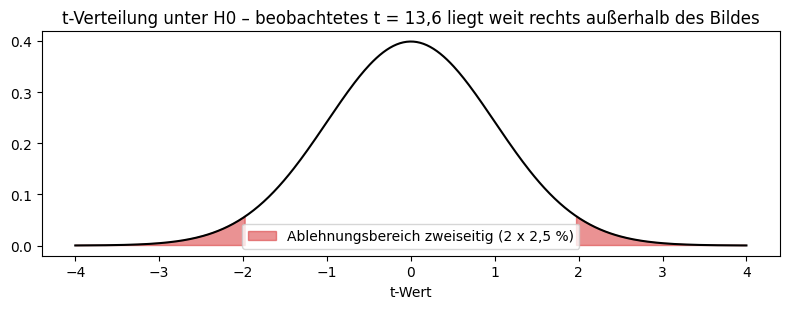

In [56]:
# ------------------------------------------------------------
# 1.3  Ablehnungsbereiche bei alpha = 0.05 (Welch-Freiheitsgrade, siehe Aufgabe 2)
#      zweiseitig: 2,5 % pro Rand | einseitig: 5 % an einem Rand
# ------------------------------------------------------------
# df_welch (Welch-Freiheitsgrade) und t_krit_zwei wurden schon in 0.2 berechnet
t_krit_ein = stats.t.ppf(1 - ALPHA, df_welch)  # Grenze einseitig (5 % an einem Rand)
print(f"Freiheitsgrade (Welch): {df_welch:.1f}")
print(f"kritischer Wert zweiseitig: +/-{t_krit_zwei:.3f} | einseitig: {t_krit_ein:.3f}")

x = np.linspace(-4, 4, 400)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(x, stats.t.pdf(x, df_welch), color="black")
ax.fill_between(
    x,
    stats.t.pdf(x, df_welch),
    where=(x <= -t_krit_zwei) | (x >= t_krit_zwei),
    color="tab:red",
    alpha=0.5,
    label="Ablehnungsbereich zweiseitig (2 x 2,5 %)",
)
ax.set_title(
    "t-Verteilung unter H0 – beobachtetes t = 13,6 liegt weit rechts außerhalb des Bildes"
)
ax.set_xlabel("t-Wert")
ax.legend()
plt.tight_layout()
plt.show()

**Kernaussage:** Wenn es keinen Unterschied gibt (H0), liegen 95 % der t-Werte im Normalbereich zwischen etwa −1,96 und +1,96; das beobachtete t = 13,6 liegt weit außerhalb davon im Ablehnungsbereich.

### ✅ Lösung – Aufgabe 1

**H0 (Nullhypothese):** Die *wahre* mittlere Wartezeit ist in Riverside und Downtown gleich. Was wir in den Stichproben sehen, ist reine Zufallsschwankung.

**H1 (Alternativhypothese):** Die wahren mittleren Wartezeiten der beiden Standorte sind verschieden – ohne Festlegung, welcher Standort länger wartet.

**Warum zweiseitig?** Die Seitenzahl folgt aus der **Entscheidung, die am Ende steht**, nicht aus der Vermutung des Analysten. Regional Operations will Personal dorthin versetzen, wo es gebraucht wird. Wäre Riverside *schneller* als Downtown, würde das die Entscheidung genauso verändern (dann müsste man eher in Downtown nachsehen) – es wäre also kein „uninteressantes Nicht-Ergebnis". Ein einseitiger Test „Riverside langsamer" könnte diesen Fall gar nicht als Befund erkennen (Code 1.2: p ≈ 1,0 trotz riesigem Unterschied). Beim zweiseitigen Test zeigt dagegen das **Vorzeichen von t** die Richtung an. In Checkpoint 2 lautete die Frage, ob Downtown das Versprechen „im Durchschnitt unter 15 Minuten“ einhält (H1: μ < 15). Nur ein Mittelwert *unter* 15 hätte das Versprechen gestützt – die Richtung stand durch die Fragestellung fest. Hier wird dagegen ein Standort mit einem anderen verglichen, und jede Abweichung hat Folgen für die Personalentscheidung. Dass der Analyst eine Richtung *vermutet*, reicht für einen einseitigen Test nicht aus.

Zusätzlich gilt: Die Richtung darf nicht *nach* dem Blick auf die Daten gewählt werden – sonst halbiert man den p-Wert nachträglich (Code 1.1) und erhöht die Fehlalarmquote.

---
## Aufgabe 2 – Welche Verteilung und warum `equal_var=False`?

> Benenne die Verteilung und den konkreten Test, der ausgeführt wird. Erkläre anschließend, was `equal_var=False` verändert und warum dies der sicherere Standard ist, obwohl die beiden Stichprobenstandardabweichungen ähnlich aussehen.

**▶ Hilfe**
> Es gibt zwei Varianten des Zwei-Stichproben-t-Tests. Die ältere nimmt an, dass beide Gruppen aus Populationen mit gleicher Streuung gezogen wurden, und fasst ihre Varianzen zu einer gemeinsamen Schätzung zusammen. Die andere macht diese Annahme nicht. Sieh dir die beiden Stichprobengrößen an – 290 gegenüber 430 – und frage dich, was passiert, wenn die *ungleich großen* Gruppen zusätzlich unterschiedliche Varianzen haben.

Wir gehen in mehreren Schritten vor: (a) Welch-Test von Hand nachrechnen, (b) die gepoolte Variante daneben stellen, (c) „Sind die Varianzen gleich?" prüfen, (d) per Simulation zeigen, was bei ungleichen n *und* ungleichen Varianzen passiert, (e) die Voraussetzungen kontrollieren.

### 2a  Welch-Test von Hand: stimmt er mit scipy überein?

In [57]:
# ------------------------------------------------------------
# 2a  Welch-Test von Hand: stimmt er mit scipy überein?
#     Teststatistik: t = (mR - mD) / SE   mit  SE = sqrt(sR^2/nR + sD^2/nD)
#     Freiheitsgrade: Welch-Satterthwaite-Näherung (KEIN n1+n2-2)
# ------------------------------------------------------------
se_welch = np.sqrt(
    v_r + v_d
)  # Standardfehler der Differenz (jede Gruppe mit EIGENER Varianz)
t_welch = diff / se_welch
p_welch = 2 * stats.t.sf(
    abs(t_welch), df_welch
)  # zweiseitiger p-Wert aus der t-Verteilung

print(f"Standardfehler der Differenz: {se_welch:.4f} Min.")
print(f"t (von Hand) = {t_welch:.4f}   | t (scipy) = {t_stat:.4f}")
print(f"p (von Hand) = {p_welch:.3g}   | p (scipy) = {p_value:.3g}")
print(f"Freiheitsgrade (Welch) = {df_welch:.1f}  (gepoolt wären es {n_r + n_d - 2})")
print(
    "Von Hand == scipy ?", np.isclose(t_welch, t_stat) and np.isclose(p_welch, p_value)
)

Standardfehler der Differenz: 0.6324 Min.
t (von Hand) = 13.5622   | t (scipy) = 13.5622
p (von Hand) = 1.02e-36   | p (scipy) = 1.02e-36
Freiheitsgrade (Welch) = 596.8  (gepoolt wären es 714)
Von Hand == scipy ? True


### 2b  Die ältere, "gepoolte" Variante (equal_var=True) zum Vergleich

In [58]:
# ------------------------------------------------------------
# 2b  Die ältere, "gepoolte" Variante (equal_var=True) zum Vergleich
#     Gemeinsame Varianz: sp^2 = ((nR-1)sR^2 + (nD-1)sD^2) / (nR+nD-2)
# ------------------------------------------------------------
sp = np.sqrt(((n_r - 1) * s_r**2 + (n_d - 1) * s_d**2) / (n_r + n_d - 2))  # gepoolte SD
se_pooled = sp * np.sqrt(1 / n_r + 1 / n_d)
t_pooled = diff / se_pooled
p_pooled = 2 * stats.t.sf(abs(t_pooled), n_r + n_d - 2)

res_pooled = stats.ttest_ind(riverside, downtown, equal_var=True)
print(f"gepoolte SD sp = {sp:.3f}")
print(
    f"gepoolt: t = {t_pooled:.3f}, p = {p_pooled:.3g} (scipy: t = {res_pooled.statistic:.3f}, p = {res_pooled.pvalue:.3g})"
)
print(f"Welch:   t = {t_welch:.3f}, p = {p_welch:.3g}")
print(
    "-> Bei diesen Daten kommen beide zum selben Ergebnis; der Unterschied zeigt sich erst in der Fehlerquote (2d)."
)

gepoolte SD sp = 8.234
gepoolt: t = 13.652, p = 7.16e-38 (scipy: t = 13.652, p = 7.16e-38)
Welch:   t = 13.562, p = 1.02e-36
-> Bei diesen Daten kommen beide zum selben Ergebnis; der Unterschied zeigt sich erst in der Fehlerquote (2d).


### 2c  Haben die beiden Standorte wirklich gleiche Varianz?

In [59]:
# ------------------------------------------------------------
# 2c  Haben die beiden Standorte wirklich gleiche Varianz?
#     Levene-Test: H0 = gleiche Varianzen (center="median" = Brown-Forsythe, robuster bei Schiefe)
# ------------------------------------------------------------
print(
    f"Verhältnis der SDs: {s_r / s_d:.3f}   | Verhältnis der Varianzen: {(s_r / s_d)**2:.3f}"
)
print(f"Verhältnis der Stichprobengrößen: {n_d / n_r:.2f} : 1")

lev_mean = stats.levene(riverside, downtown, center="mean")
lev_median = stats.levene(riverside, downtown, center="median")
print(f"Levene (Mittelwert): W = {lev_mean.statistic:.3f}, p = {lev_mean.pvalue:.3f}")
print(
    f"Brown-Forsythe (Median): W = {lev_median.statistic:.3f}, p = {lev_median.pvalue:.3f}"
)
print(
    "-> nicht signifikant: kein NACHWEIS ungleicher Varianzen - aber auch kein Beweis, dass sie gleich sind."
)

Verhältnis der SDs: 1.033   | Verhältnis der Varianzen: 1.068
Verhältnis der Stichprobengrößen: 1.50 : 1
Levene (Mittelwert): W = 2.686, p = 0.102
Brown-Forsythe (Median): W = 1.845, p = 0.175
-> nicht signifikant: kein NACHWEIS ungleicher Varianzen - aber auch kein Beweis, dass sie gleich sind.


### 2d  Simulation: Was passiert bei ungleichen n UND ungleichen Varianzen?

In [60]:
# ------------------------------------------------------------
# 2d  Simulation: Was passiert bei ungleichen n UND ungleichen Varianzen?
#     H0 ist hier per Konstruktion WAHR (beide Mittelwerte = 0).
#     Ein korrekter Test sollte in ca. 5 % der Fälle fälschlich "signifikant" melden (Typ-I-Fehler).
#     Wir nutzen die echten Stichprobengrößen 290 / 430.
# ------------------------------------------------------------
def typ1_rate(sd_R, sd_D, n1=290, n2=430, n_sim=10_000):
    X = rng.normal(0, sd_R, size=(n_sim, n1))  # n_sim Stichproben "Riverside"
    Y = rng.normal(0, sd_D, size=(n_sim, n2))  # n_sim Stichproben "Downtown"
    p_welch = stats.ttest_ind(X, Y, axis=1, equal_var=False).pvalue
    p_pooled = stats.ttest_ind(X, Y, axis=1, equal_var=True).pvalue
    return (p_welch < ALPHA).mean(), (p_pooled < ALPHA).mean()


szenarien = {
    "A) gleiche Varianz (SD 8 / 8)": (8, 8),
    "B) kleine Gruppe streut MEHR (SD 12 / 6)": (12, 6),
    "C) kleine Gruppe streut WENIGER (SD 6 / 12)": (6, 12),
}
rows = []
for name, (sdR, sdD) in szenarien.items():
    w, p = typ1_rate(sdR, sdD)
    rows.append(
        {"Szenario": name, "Fehlalarmquote Welch": w, "Fehlalarmquote gepoolt": p}
    )
sim_tab = pd.DataFrame(rows).set_index("Szenario")
print(
    sim_tab.map(lambda v: f"{v:.1%}")
    if hasattr(sim_tab, "map")
    else sim_tab.applymap(lambda v: f"{v:.1%}")
)
print(
    "\nSoll: 5,0 %.  Welch hält die 5 % in allen Szenarien ein; der gepoolte Test nur bei gleicher Varianz."
)

                                            Fehlalarmquote Welch  \
Szenario                                                           
A) gleiche Varianz (SD 8 / 8)                               5.1%   
B) kleine Gruppe streut MEHR (SD 12 / 6)                    4.7%   
C) kleine Gruppe streut WENIGER (SD 6 / 12)                 4.9%   

                                            Fehlalarmquote gepoolt  
Szenario                                                            
A) gleiche Varianz (SD 8 / 8)                                 5.2%  
B) kleine Gruppe streut MEHR (SD 12 / 6)                      7.8%  
C) kleine Gruppe streut WENIGER (SD 6 / 12)                   2.6%  

Soll: 5,0 %.  Welch hält die 5 % in allen Szenarien ein; der gepoolte Test nur bei gleicher Varianz.


### 2e  Voraussetzungen des t-Tests: Sind die MITTELWERTE näherungsweise normalverteilt?

Schiefe Riverside: 1.06 | Downtown: 2.07  (0 = symmetrisch)
Shapiro-Wilk Riverside p = 8.8e-11 | Downtown p = 2.1e-19
-> Einzelwerte NICHT normalverteilt (rechtsschief). Entscheidend ist aber die Verteilung des MITTELWERTS / der Differenz:
Schiefe der Bootstrap-Differenzen: 0.021  -> praktisch symmetrisch, Normalnäherung trägt


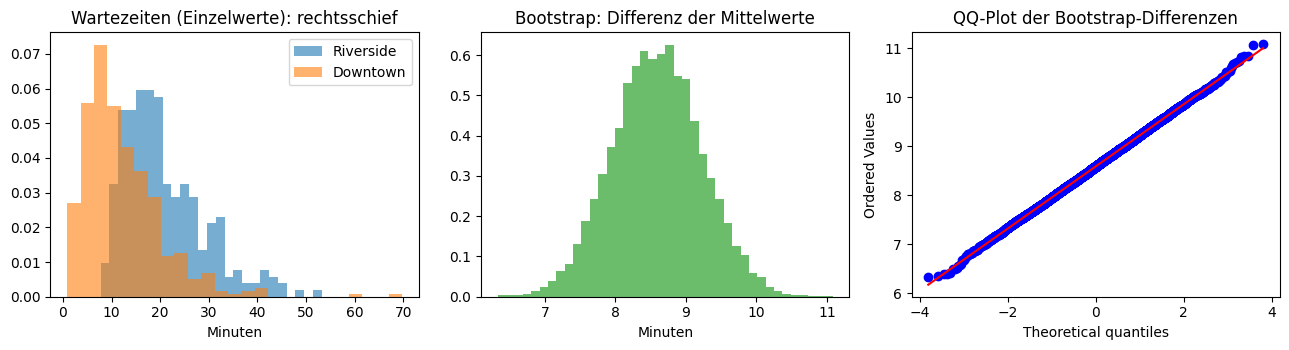

In [61]:
# ------------------------------------------------------------
# 2e  Voraussetzungen des t-Tests: Sind die MITTELWERTE näherungsweise normalverteilt?
#     Die Einzelwerte sind es nicht (rechtsschief), aber bei n = 290 / 430 greift der zentrale Grenzwertsatz.
# ------------------------------------------------------------
print(
    f"Schiefe Riverside: {stats.skew(riverside):.2f} | Downtown: {stats.skew(downtown):.2f}  (0 = symmetrisch)"
)
print(
    f"Shapiro-Wilk Riverside p = {stats.shapiro(riverside).pvalue:.2g} | Downtown p = {stats.shapiro(downtown).pvalue:.2g}"
)
print(
    "-> Einzelwerte NICHT normalverteilt (rechtsschief). Entscheidend ist aber die Verteilung des MITTELWERTS / der Differenz:"
)

# Bootstrap: Differenz der Mittelwerte 10 000 mal neu "ziehen" (mit Zurücklegen)
boot_diff = np.array(
    [
        rng.choice(riverside.values, n_r).mean()
        - rng.choice(downtown.values, n_d).mean()
        for _ in range(10_000)
    ]
)
print(
    f"Schiefe der Bootstrap-Differenzen: {stats.skew(boot_diff):.3f}  -> praktisch symmetrisch, Normalnäherung trägt"
)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].hist(riverside, bins=25, alpha=0.6, label="Riverside", density=True)
axes[0].hist(downtown, bins=25, alpha=0.6, label="Downtown", density=True)
axes[0].set_title("Wartezeiten (Einzelwerte): rechtsschief")
axes[0].set_xlabel("Minuten")
axes[0].legend()
axes[1].hist(boot_diff, bins=40, color="tab:green", alpha=0.7, density=True)
axes[1].set_title("Bootstrap: Differenz der Mittelwerte")
axes[1].set_xlabel("Minuten")
stats.probplot(boot_diff, dist="norm", plot=axes[2])
axes[2].set_title("QQ-Plot der Bootstrap-Differenzen")
plt.tight_layout()
plt.show()

**Kernaussage:** Die Einzelwerte beider Standorte sind rechtsschief, aber die Bootstrap-Differenz der Mittelwerte (um 8,6 Minuten) ist praktisch symmetrisch und folgt im QQ-Plot einer Geraden, sodass die Normalnäherung für den Mittelwertvergleich trägt.

### 2f  Gegenprobe ohne Normalitätsannahme: Mann-Whitney-U und Permutationstest

Mann-Whitney-U: U = 98918, p = 2.31e-43
Permutationstest: p = 0.00010  (kleinstmöglicher Wert bei 10000 Mischungen: 0.00010)
Größte Differenz unter H0 (Zufall): 3.10 Min.  vs.  beobachtet: 8.58 Min.


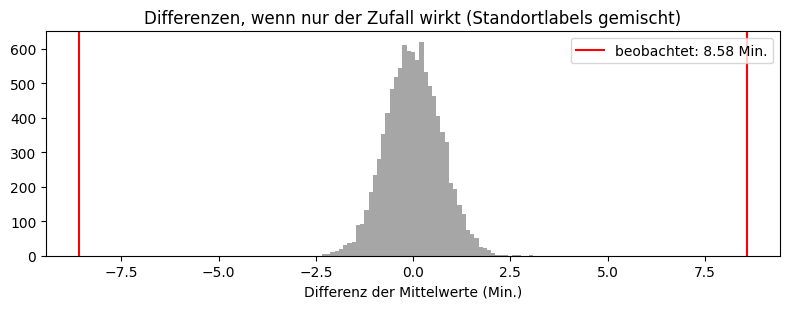

In [62]:
# ------------------------------------------------------------
# 2f  Gegenprobe ohne Normalitätsannahme: Mann-Whitney-U und Permutationstest
#     Permutationstest: Standortlabels 10 000 mal zufällig mischen -> wie oft ist die Differenz so groß wie beobachtet?
# ------------------------------------------------------------
mw = stats.mannwhitneyu(riverside, downtown, alternative="two-sided")
print(f"Mann-Whitney-U: U = {mw.statistic:.0f}, p = {mw.pvalue:.3g}")

werte = np.concatenate(
    [riverside.values, downtown.values]
)  # alle Wartezeiten beider Standorte
n_perm = 10_000
perm_diffs = np.empty(n_perm)
for i in range(n_perm):
    rng.shuffle(werte)  # Labels zufällig neu zuordnen = "H0 wahr"
    perm_diffs[i] = werte[:n_r].mean() - werte[n_r:].mean()
p_perm = (np.sum(np.abs(perm_diffs) >= abs(diff)) + 1) / (n_perm + 1)

print(
    f"Permutationstest: p = {p_perm:.5f}  (kleinstmöglicher Wert bei {n_perm} Mischungen: {1/(n_perm+1):.5f})"
)
print(
    f"Größte Differenz unter H0 (Zufall): {perm_diffs.max():.2f} Min.  vs.  beobachtet: {diff:.2f} Min."
)

plt.figure(figsize=(8, 3.2))
plt.hist(perm_diffs, bins=50, color="grey", alpha=0.7)
plt.axvline(diff, color="red", label=f"beobachtet: {diff:.2f} Min.")
plt.axvline(-diff, color="red")
plt.title("Differenzen, wenn nur der Zufall wirkt (Standortlabels gemischt)")
plt.xlabel("Differenz der Mittelwerte (Min.)")
plt.legend()
plt.tight_layout()
plt.show()

**Kernaussage:** Wenn nur der Zufall wirkt (Standortlabels gemischt), erreicht die Differenz höchstens etwa 3,1 Minuten – die beobachteten 8,58 Minuten liegen weit außerhalb.

### ✅ Lösung – Aufgabe 2

**Test und Verteilung:** Ausgeführt wird der **Welch-t-Test** (Zwei-Stichproben-t-Test für unabhängige Stichproben mit ungleichen Varianzen). Unter H0 folgt die Teststatistik näherungsweise einer **Student-t-Verteilung**; die Freiheitsgrade werden nach Welch–Satterthwaite geschätzt (hier ≈ 596,8 statt n₁+n₂−2 = 714).

**Was `equal_var=False` verändert:** Es gibt keine gemeinsame („gepoolte") Varianz. Jede Gruppe geht mit *ihrer eigenen* Varianz in den Standardfehler ein, und die Freiheitsgrade werden entsprechend angepasst (Code 2a und 2b).

**Warum das der sicherere Standard ist, obwohl die SDs ähnlich aussehen (8,40 und 8,12):**
1. „Gleiche Varianz" ist eine Annahme über die *Populationen*, nicht über die Stichproben. Ähnliche Stichproben-SDs und ein nicht signifikanter Levene-Test (Code 2c) sind kein Beweis dafür.
2. Bei **ungleich großen Gruppen** (286 gegenüber 430) *und* ungleichen Varianzen verzerrt der gepoolte Test die Fehlalarmquote: Streut die kleinere Gruppe mehr, liegt sie über den 5 % (im Code ≈ 8 %); streut sie weniger, ist der Test zu vorsichtig (≈ 2,6 %). Welch hält in allen Szenarien ≈ 5 % (Code 2d).
3. Welch kostet bei gleichen Varianzen praktisch nichts (Szenario A) – also gibt es kaum einen Grund, auf die Absicherung zu verzichten.

**Voraussetzungen:** unabhängige Beobachtungen (die 9 doppelten Besuche, die no-show-Besuche und die Ausreißer ändern nichts am Ergebnis, Code 0.3) und ein näherungsweise normalverteilter Mittelwert. Die Einzelwerte sind rechtsschief, aber bei n = 286/430 trägt der zentrale Grenzwertsatz (Code 2e). Mann-Whitney und Permutationstest (Code 2f) kommen ohne Normalitätsannahme zum selben Schluss.

---
## Aufgabe 3 – Typ-I- und Typ-II-Fehler bei dieser Entscheidung

> Benenne für diese konkrete Situation, was ein Typ-I-Fehler und was ein Typ-II-Fehler wäre – was jeder für die Personalentscheidung bedeutet und welche Kosten damit verbunden sind. Sage anschließend, welchen der beiden Fehler dieser Test kontrollieren soll und wie.

**▶ Hilfe**
> Baue eine Zwei-mal-zwei-Matrix: Was ist in der Realität wahr – die Standorte unterscheiden sich wirklich oder nicht – gegenüber dem, was der Test schlussfolgert. Zwei der vier Felder sind korrekt und zwei sind Fehler. Benenne die Fehler in den Begriffen des Standortleiters – Personal versetzen oder nicht versetzen – statt in statistischer Sprache. Frage dann, für welchen Fehler das Signifikanzniveau eine Obergrenze setzt und zu welchem diese Ausgabe überhaupt keine Information enthält.

In [63]:
# ------------------------------------------------------------
# 3a  Die Zwei-mal-zwei-Matrix in den Begriffen von Regional Operations
# ------------------------------------------------------------
matrix = pd.DataFrame(
    {
        "Test: signifikant (H0 verworfen)": [
            "TYP-I-FEHLER: 2 Mitarbeitende werden versetzt, obwohl es keinen Unterschied gibt",
            "RICHTIG: Versetzung ist berechtigt",
        ],
        "Test: nicht signifikant (H0 vorläufig beibehalten)": [
            "RICHTIG: keine Versetzung nötig",
            "TYP-II-FEHLER: echter Unterschied wird übersehen, Riverside bleibt unterbesetzt",
        ],
    },
    index=["Realität: KEIN Unterschied (H0 wahr)", "Realität: Unterschied (H1 wahr)"],
)
pd.set_option("display.max_colwidth", None)
matrix

,Test: signifikant (H0 verworfen),Test: nicht signifikant (H0 vorläufig beibehalten)
Realität: KEIN Unterschied (H0 wahr),"TYP-I-FEHLER: 2 Mitarbeitende werden versetzt, obwohl es keinen Unterschied gibt",RICHTIG: keine Versetzung nötig
Realität: Unterschied (H1 wahr),RICHTIG: Versetzung ist berechtigt,"TYP-II-FEHLER: echter Unterschied wird übersehen, Riverside bleibt unterbesetzt"


In [64]:
# ------------------------------------------------------------
# 3b  Was kostet ein Typ-II-Fehler? Beschreibende Zahlen aus den Daten
#     (nur Beschreibung, KEIN Kausalbeweis - die Kosten sind Argumente für die Abwägung)
# ------------------------------------------------------------
kosten = (
    df.groupby("clinic_site")
    .agg(
        besuche=("visit_id", "size"),
        mittl_wartezeit=("wait_time_min", "mean"),
        anteil_ueber_15min=("wait_time_min", lambda s: (s > 15).mean()),
        anteil_ueber_30min=("wait_time_min", lambda s: (s > 30).mean()),
        zufriedenheit=(
            "patient_satisfaction",
            "mean",
        ),  # NaN werden von mean() ignoriert
        no_show_quote=("no_show", "mean"),
    )
    .sort_values("mittl_wartezeit", ascending=False)
)
print(kosten.round(3))

sat = df.dropna(subset=["patient_satisfaction"])
r_sat = stats.pearsonr(sat["wait_time_min"], sat["patient_satisfaction"])
print(
    f"\nKorrelation Wartezeit <-> Zufriedenheit: r = {r_sat.statistic:.2f} (p = {r_sat.pvalue:.2g})"
)
print(
    "-> Längere Wartezeit geht mit geringerer Zufriedenheit einher; Riverside hat die niedrigste Zufriedenheit."
)
print(
    "-> Die No-Show-Quote unterscheidet sich kaum - die Kosten eines Typ-II-Fehlers liegen hier eher bei der Zufriedenheit."
)

             besuche  mittl_wartezeit  anteil_ueber_15min  anteil_ueber_30min  \
clinic_site                                                                     
Riverside        286           20.756               0.727               0.150   
Eastview         220           12.621               0.318               0.036   
Downtown         430           12.179               0.279               0.030   
Northgate        264           11.951               0.273               0.034   

             zufriedenheit  no_show_quote  
clinic_site                                
Riverside            3.850          0.094  
Eastview             4.193          0.127  
Downtown             4.191          0.116  
Northgate            4.155          0.091  

Korrelation Wartezeit <-> Zufriedenheit: r = -0.39 (p = 4.4e-40)
-> Längere Wartezeit geht mit geringerer Zufriedenheit einher; Riverside hat die niedrigste Zufriedenheit.
-> Die No-Show-Quote unterscheidet sich kaum - die Kosten eines Typ-II-Fehle

In [65]:
# ------------------------------------------------------------
# 3c  Typ-I-Fehler kontrollieren: Die Fehlalarmquote entspricht alpha.
#     Wir machen H0 "wahr", indem wir die Riverside- und Downtown-Werte zusammenwerfen
#     und zufällig in Gruppen von 290 und 430 aufteilen (echte, schiefe Daten!).
# ------------------------------------------------------------
werte = np.concatenate([riverside.values, downtown.values])
n_sim = 5_000
fehlalarme = 0
for _ in range(n_sim):
    rng.shuffle(werte)
    p = stats.ttest_ind(werte[:n_r], werte[n_r:], equal_var=False).pvalue
    fehlalarme += p < ALPHA

print(
    f"Fehlalarmquote bei wahrer H0: {fehlalarme / n_sim:.3f}  (Soll: alpha = {ALPHA})"
)

Fehlalarmquote bei wahrer H0: 0.056  (Soll: alpha = 0.05)


In [66]:
# ------------------------------------------------------------
# 3d  Typ-II-Fehler: Dazu enthält die Ausgabe (t, p, KI, d) KEINE Information.
#     beta hängt von wahrer Effektgröße, Streuung, n und alpha ab -> Teststärke (Power) = 1 - beta
#     Analytisch über die nichtzentrale t-Verteilung:
# ------------------------------------------------------------
def power_zwei_stichproben(delta, sd, n1, n2, alpha=ALPHA):
    """Power des zweiseitigen Zwei-Stichproben-t-Tests für eine WAHRE Differenz delta (Minuten).
    Näherung mit gepoolter SD und n1+n2-2 Freiheitsgraden; die Simulation mit Welch weiter unten bestätigt sie.
    """
    se = sd * np.sqrt(1 / n1 + 1 / n2)  # Standardfehler der Differenz
    dfp = n1 + n2 - 2
    nc = delta / se  # Nichtzentralitätsparameter
    t_krit = stats.t.ppf(1 - alpha / 2, dfp)
    return stats.nct.sf(t_krit, dfp, nc) + stats.nct.cdf(-t_krit, dfp, nc)


# Kleinster Effekt, den der Test mit 80 % Power noch findet (Minimum Detectable Effect)
mde = brentq(lambda dl: power_zwei_stichproben(dl, sp, n_r, n_d) - 0.80, 0.01, 5)
print(
    f"Kleinste nachweisbare Differenz bei 80 % Power: {mde:.2f} Min. (d = {mde / sp:.2f})"
)


# Kontrolle per Simulation mit den ECHTEN Daten:
#   Riverside-Werte werden so verschoben, dass die wahre Differenz = delta ist (delta = 0 -> H0 wahr)
def power_simulation(delta, n_sim=2_000):
    treffer = 0
    for _ in range(n_sim):
        a = (
            rng.choice(riverside.values, n_r) - diff + delta
        )  # Differenz auf delta setzen
        b = rng.choice(downtown.values, n_d)
        treffer += stats.ttest_ind(a, b, equal_var=False).pvalue < ALPHA
    return treffer / n_sim


deltas = [0, 1, 2, 3, 5, round(diff, 2)]
power_tab = pd.DataFrame(
    {
        "wahre Differenz (Min.)": deltas,
        "Power analytisch": [power_zwei_stichproben(dl, sp, n_r, n_d) for dl in deltas],
        "Power simuliert": [power_simulation(dl) for dl in deltas],
    }
)
power_tab["Typ-II-Risiko (1 - Power) analytisch"] = 1 - power_tab["Power analytisch"]
print(power_tab.round(3).to_string(index=False))
print(
    "\nBei delta = 0 ist 'Power' = alpha (Fehlalarmquote). Die letzte Zeile (beobachteter Effekt, 8,5 Min.) ist nur ein Referenzpunkt: Eine 'beobachtete Teststärke' ist bloß eine Umrechnung des p-Werts und sagt nichts Neues; belastbar sind nur extern festgelegte Differenzen."
)

Kleinste nachweisbare Differenz bei 80 % Power: 1.76 Min. (d = 0.21)
 wahre Differenz (Min.)  Power analytisch  Power simuliert  Typ-II-Risiko (1 - Power) analytisch
                   0.00             0.050            0.055                                 0.950
                   1.00             0.356            0.352                                 0.644
                   2.00             0.889            0.884                                 0.111
                   3.00             0.998            0.994                                 0.002
                   5.00             1.000            1.000                                 0.000
                   8.58               NaN            1.000                                   NaN

Bei delta = 0 ist 'Power' = alpha (Fehlalarmquote). Die letzte Zeile (beobachteter Effekt, 8,5 Min.) ist nur ein Referenzpunkt: Eine 'beobachtete Teststärke' ist bloß eine Umrechnung des p-Werts und sagt nichts Neues; belastbar sind nur extern festgel

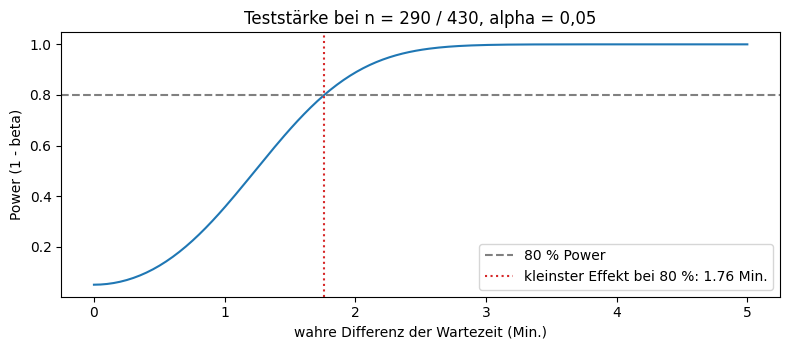

In [67]:
# ------------------------------------------------------------
# 3e  Powerkurve: Wie gut erkennt der Test welche Differenz?
# ------------------------------------------------------------
xs = np.linspace(0, 5, 200)
plt.figure(figsize=(8, 3.6))
plt.plot(xs, [power_zwei_stichproben(x_, sp, n_r, n_d) for x_ in xs], color="tab:blue")
plt.axhline(0.80, color="grey", ls="--", label="80 % Power")
plt.axvline(
    mde, color="tab:red", ls=":", label=f"kleinster Effekt bei 80 %: {mde:.2f} Min."
)
plt.xlabel("wahre Differenz der Wartezeit (Min.)")
plt.ylabel("Power (1 - beta)")
plt.title("Teststärke bei n = 290 / 430, alpha = 0,05")
plt.legend()
plt.tight_layout()
plt.show()

**Kernaussage:** Bei 286 und 430 Besuchen (α = 0,05) erkennt der Test eine wahre Wartezeit-Differenz ab etwa 1,76 Minuten mit 80 % Wahrscheinlichkeit; bei kleineren Unterschieden wird er zunehmend unsicher.

### ✅ Lösung – Aufgabe 3

**Typ-I-Fehler (Fehlalarm):** Der Test meldet einen Unterschied, aber in Wahrheit warten beide Standorte gleich lang. Folge: **Zwei Mitarbeitende werden nach Riverside versetzt, obwohl dort kein Mehrbedarf besteht.** Kosten: Downtown (aktuell ≈ 12 Min. Wartezeit) wird unnötig geschwächt, dazu Aufwand und Unruhe durch die Versetzung – ohne Nutzen.

**Typ-II-Fehler (verpasster Effekt):** Der Test meldet keinen Unterschied, aber Riverside wartet in Wahrheit tatsächlich länger. Folge: **Es wird nicht versetzt, Riverside bleibt unterbesetzt.** Kosten: Patienten warten weiter deutlich länger. In den Daten gehen längere Wartezeiten mit geringerer Zufriedenheit einher (r ≈ −0,39; Riverside hat mit ≈ 3,85 die niedrigste mittlere Zufriedenheit, Code 3b). Die Kosten sind ungleich verteilt: Unter der Annahme, dass sich eine Versetzung vergleichsweise leicht rückgängig machen lässt, während anhaltend schlechter Service schleichend wirkt, wäre der Typ-II-Fehler eher der teurere. Wie schwer jeder Fehler wiegt, ist eine **Geschäftsabwägung**, keine statistische Frage.

**Welchen Fehler kontrolliert der Test?** Den **Typ-I-Fehler**. Das Signifikanzniveau **α = 0,05**, *vor* der Auswertung festgelegt, setzt eine Obergrenze: Ist H0 wahr, wird sie in höchstens 5 % der Fälle fälschlich verworfen (Code 3c, Fehlalarmquote ≈ 5 %). Dass diese Quote wirklich eingehalten wird, sichert die Wahl des Welch-Tests (Aufgabe 2).

**Und der Typ-II-Fehler?** Zu **β** enthält die Ausgabe (t, p-Wert, Konfidenzintervall, Cohen's d) **keine Information**. β hängt von der wahren Effektgröße, der Streuung, den Stichprobengrößen und α ab und wird über die **Teststärke (1 − β)** *vor* der Datenerhebung geplant. Bei n = 286/430 erkennt der Test eine wahre Differenz von ≈ 1,8 Min. mit 80 % Power (Code 3d, 3e). Die betriebliche Mindestdifferenz von 5 Minuten (Aufgabe 4g, nachträglich festgelegt) liegt weit darüber: Das Design war für einen relevanten Unterschied geeignet. Den beobachteten Effekt setzen wir bewusst nicht in eine Poweranalyse ein, denn die so berechnete „beobachtete Teststärke“ wäre nur eine Umrechnung des p-Werts. Da das Ergebnis hier statistisch signifikant ist, ist ein Typ-II-Fehler für *dieses* Ergebnis ohnehin nicht das Risiko; er wäre nur relevant, wenn der Test nicht signifikant gewesen wäre.

---
## Aufgabe 4 – Der p-Wert, das Intervall und die Effektgröße

> Der p-Wert liegt ungefähr bei 10⁻³⁶. Erkläre, was diese Zahl belegt und was nicht. Sage anschließend, welche der drei Zahlen in der Ausgabe – p-Wert, Konfidenzintervall, Cohen's d – du Regional Operations zeigen würdest und warum.

**▶ Hilfe**
> Drei Zahlen, drei unterschiedliche Fragen: *Ist der Effekt real?*, *Wie groß ist er und mit welcher Unsicherheit?* und *Wie groß ist er relativ dazu, wie stark die Werte zwischen Personen variieren?* Ordne zuerst jeder Zahl ihre Frage zu und entscheide dann, welche davon auf die Folie gehört. Eine Führungskraft, die entscheiden muss, ob zwei Personen versetzt werden, braucht eine dieser Zahlen deutlich mehr als die anderen beiden.

### 4a  Was der p-Wert BELEGT: Daten wären unter H0 extrem unwahrscheinlich

In [68]:
# ------------------------------------------------------------
# 4a  Was der p-Wert BELEGT: Daten wären unter H0 extrem unwahrscheinlich
#     p = P(|T| >= |t_beobachtet| | H0)  -> Fläche in beiden Rändern der t-Verteilung
# ------------------------------------------------------------
p_manuell = 2 * stats.t.sf(abs(t_welch), df_welch)
print(f"p-Wert (t-Verteilung): {p_manuell:.3g}")
print(
    f"Der Zufall allein erzeugt eine Differenz von {diff:.1f} Min. praktisch nie: "
    f"in {n_perm} gemischten Datensätzen lag das Maximum bei {perm_diffs.max():.2f} Min. (Code 2f)."
)

# ... und was er NICHT belegt: Die vielen Nullen sind nicht belastbar.
#     Drei Verfahren, drei verschiedene p-Werte - aber dieselbe Aussage "weit unter 0,05":
print("\nVergleich der p-Werte verschiedener Verfahren (gleiche Daten):")
print(f"  Welch-t-Test:          {p_value:.3g}")
print(f"  gepoolter t-Test:      {res_pooled.pvalue:.3g}")
print(f"  Mann-Whitney-U:        {mw.pvalue:.3g}")
print(
    f"  Permutationstest:      < {1/(n_perm+1):.5f} (feiner geht es mit 10 000 Mischungen nicht)"
)

p-Wert (t-Verteilung): 1.02e-36
Der Zufall allein erzeugt eine Differenz von 8.6 Min. praktisch nie: in 10000 gemischten Datensätzen lag das Maximum bei 3.10 Min. (Code 2f).

Vergleich der p-Werte verschiedener Verfahren (gleiche Daten):
  Welch-t-Test:          1.02e-36
  gepoolter t-Test:      7.16e-38
  Mann-Whitney-U:        2.31e-43
  Permutationstest:      < 0.00010 (feiner geht es mit 10 000 Mischungen nicht)


### 4b  Der p-Wert sagt nichts über die GRÖSSE: kleiner p-Wert bei winzigem Effekt

In [69]:
# ------------------------------------------------------------
# 4b  Der p-Wert sagt nichts über die GRÖSSE: kleiner p-Wert bei winzigem Effekt
#     Beispiel (konstruiert, aus Kennzahlen): Differenz nur 0,5 Min., SD 8,3, je 5 000 Patienten
# ------------------------------------------------------------
demo = stats.ttest_ind_from_stats(
    mean1=0.5, std1=8.3, nobs1=5000, mean2=0.0, std2=8.3, nobs2=5000, equal_var=False
)
print(
    f"Winziger Effekt, große Stichprobe: p = {demo.pvalue:.4f} (statistisch signifikant!), d = {0.5 / 8.3:.2f} (praktisch bedeutungslos)"
)
print(
    "Umgekehrt: Ein großer Effekt kann bei kleinem n nicht signifikant sein. p-Wert = Beweiskraft, nicht Bedeutung."
)

Winziger Effekt, große Stichprobe: p = 0.0026 (statistisch signifikant!), d = 0.06 (praktisch bedeutungslos)
Umgekehrt: Ein großer Effekt kann bei kleinem n nicht signifikant sein. p-Wert = Beweiskraft, nicht Bedeutung.


### 4c  Das 95-%-Konfidenzintervall der Differenz (Welch): diff +/- t_krit * SE

In [70]:
# ------------------------------------------------------------
# 4c  Das 95-%-Konfidenzintervall der Differenz (Welch): diff +/- t_krit * SE
# ------------------------------------------------------------
# (t_krit_zwei = t.ppf(1 - ALPHA/2, df): 95 % = 1 - alpha, daher 0,975 bei zweiseitigem alpha = 0,05)
ci_low = diff - t_krit_zwei * se_welch
ci_high = diff + t_krit_zwei * se_welch
print(
    f"Differenz = {diff:.2f} Min.,  95-%-KI = [{ci_low:.2f}; {ci_high:.2f}] Min.   (Rohdaten laut Aufgabe: 7,30 bis 9,78; bereinigt: 7,33 bis 9,82)"
)
assert round(ci_low, 2) == 7.33 and round(ci_high, 2) == 9.82  # bereinigte Hauptanalyse

# Gegenprobe ohne Normalitätsannahme: Bootstrap-Intervall (Perzentile der 10 000 Bootstrap-Differenzen aus 2e)
bs_low, bs_high = np.percentile(boot_diff, [2.5, 97.5])
print(f"Bootstrap-95-%-KI = [{bs_low:.2f}; {bs_high:.2f}] Min.  -> praktisch identisch")
print(
    f"Das Intervall enthält 0 nicht -> passt zum signifikanten Test: {not (ci_low <= 0 <= ci_high)}"
)
print(f"Relativ: Riverside wartet im Schnitt {m_r / m_d - 1:.0%} länger als Downtown.")

# Entscheidung: p-Wert gegen das vorab festgelegte Signifikanzniveau alpha
print(f"\nalpha = {ALPHA}")
print(
    f"p = {p_value:.3g} < alpha ? {p_value < ALPHA}  ->  Nullhypothese wird verworfen (statistisch signifikant)"
)

Differenz = 8.58 Min.,  95-%-KI = [7.33; 9.82] Min.   (Rohdaten laut Aufgabe: 7,30 bis 9,78; bereinigt: 7,33 bis 9,82)
Bootstrap-95-%-KI = [7.37; 9.83] Min.  -> praktisch identisch
Das Intervall enthält 0 nicht -> passt zum signifikanten Test: True
Relativ: Riverside wartet im Schnitt 70% länger als Downtown.

alpha = 0.05
p = 1.02e-36 < alpha ? True  ->  Nullhypothese wird verworfen (statistisch signifikant)


### 4d  Cohen's d: Differenz geteilt durch die gepoolte Standardabweichung (einheitenlos)

In [71]:
# ------------------------------------------------------------
# 4d  Cohen's d: Differenz geteilt durch die gepoolte Standardabweichung (einheitenlos)
# ------------------------------------------------------------
cohens_d = diff / sp
print(
    f"Cohen's d = {cohens_d:.2f}        alpha = {ALPHA}   (Rohdaten laut Aufgabe: d = 1,03; bereinigt: d = 1,04; alpha = 0,05)"
)
assert round(cohens_d, 2) == 1.04  # bereinigte Hauptanalyse

# Intuitive Übersetzung: Wahrscheinlichkeit, dass ein zufälliger Riverside-Patient länger wartet
# als ein zufälliger Downtown-Patient (= U / (n1 * n2) aus dem Mann-Whitney-Test)
p_ueberlegen = mw.statistic / (n_r * n_d)
print(
    f"P(zufälliger Riverside-Patient wartet länger als zufälliger Downtown-Patient) = {p_ueberlegen:.1%}"
)
print(
    "Faustregel (Cohen): 0,2 klein | 0,5 mittel | 0,8 groß -> hier groß. Die Regel ist nur eine grobe Orientierung."
)

Cohen's d = 1.04        alpha = 0.05   (Rohdaten laut Aufgabe: d = 1,03; bereinigt: d = 1,04; alpha = 0,05)
P(zufälliger Riverside-Patient wartet länger als zufälliger Downtown-Patient) = 80.4%
Faustregel (Cohen): 0,2 klein | 0,5 mittel | 0,8 groß -> hier groß. Die Regel ist nur eine grobe Orientierung.


### 4e  Anteil Patienten mit > 15 Min. Wartezeit und Chi-Quadrat-Test

In [72]:
# ------------------------------------------------------------
# 4e  Anteil Patienten mit > 15 Min. Wartezeit und Chi-Quadrat-Test
#     H0: Der Anteil "wartet > 15 Min." ist an beiden Standorten gleich.
# ------------------------------------------------------------
tab = pd.crosstab(
    df[df["clinic_site"].isin(["Riverside", "Downtown"])]["clinic_site"],
    df[df["clinic_site"].isin(["Riverside", "Downtown"])]["wait_time_min"] > 15,
)
tab.columns = ["wartet <= 15 Min.", "wartet > 15 Min."]
print(tab)

chi2, p_chi, dof, erwartet = stats.chi2_contingency(
    tab
)  # 2x2: scipy wendet standardmäßig Yates-Korrektur an
print(
    f"\nAnteil > 15 Min.: Riverside {tab.loc['Riverside', 'wartet > 15 Min.'] / tab.loc['Riverside'].sum():.1%} "
    f"vs. Downtown {tab.loc['Downtown', 'wartet > 15 Min.'] / tab.loc['Downtown'].sum():.1%}"
)
print(f"Chi-Quadrat = {chi2:.1f}, Freiheitsgrade = {dof}, p = {p_chi:.3g}")
print(
    f"Kleinste erwartete Häufigkeit = {erwartet.min():.1f} (Faustregel: >= 5 -> Voraussetzung erfüllt)"
)

             wartet <= 15 Min.  wartet > 15 Min.
clinic_site                                     
Downtown                   310               120
Riverside                   78               208

Anteil > 15 Min.: Riverside 72.7% vs. Downtown 27.9%
Chi-Quadrat = 137.2, Freiheitsgrade = 1, p = 1.09e-31
Kleinste erwartete Häufigkeit = 131.0 (Faustregel: >= 5 -> Voraussetzung erfüllt)


### 4f  Übersicht: Welche Zahl beantwortet welche Frage - und was kommt auf die Folie?

In [73]:
# ------------------------------------------------------------
# 4f  Übersicht: Welche Zahl beantwortet welche Frage - und was kommt auf die Folie?
# ------------------------------------------------------------
uebersicht = pd.DataFrame(
    {
        "Zahl": [
            f"p-Wert = {p_value:.2g}",
            f"95-%-KI = [{ci_low:.1f}; {ci_high:.1f}] Min.",
            f"Cohen's d = {cohens_d:.2f}",
        ],
        "Beantwortet die Frage": [
            "Wie gut sind die Daten mit H0 (kein Unterschied) vereinbar?",
            "Wie groß ist er und wie sicher ist die Schätzung?",
            "Wie groß ist er relativ zur Streuung zwischen Patienten?",
        ],
        "Einheit": ["Wahrscheinlichkeit", "Minuten", "einheitenlos"],
        "Auf die Folie?": [
            "nur als Fußnote (signifikant, p < 0,001)",
            "JA - Hauptzahl",
            "nur als Einordnung",
        ],
    }
)
uebersicht

,Zahl,Beantwortet die Frage,Einheit,Auf die Folie?
0,p-Wert = 1e-36,Wie gut sind die Daten mit H0 (kein Unterschied) vereinbar?,Wahrscheinlichkeit,"nur als Fußnote (signifikant, p < 0,001)"
1,95-%-KI = [7.3; 9.8] Min.,Wie groß ist er und wie sicher ist die Schätzung?,Minuten,JA - Hauptzahl
2,Cohen's d = 1.04,Wie groß ist er relativ zur Streuung zwischen Patienten?,einheitenlos,nur als Einordnung


### 4g – Praktische Relevanz: betriebliche Mindestdifferenz (nachträglich festgelegt)

Signifikant heißt: Der Unterschied ist real. Ob er für den Betrieb **groß genug** ist, um zu handeln, beantwortet erst eine Mindestdifferenz.

**Festlegung:** `MINDESTDIFFERENZ_MIN = 5` Minuten, ein Drittel des Serviceversprechens von 15 Minuten (Checkpoint 2). Das ist eine begründete **Annahme**, keine Kostenrechnung: Die tatsächlichen Kosten einer Versetzung sind in den Daten nicht enthalten.

**Wichtig:** Diese Schwelle wurde **nach Abschluss der beiden Tests** festgelegt. Sie ist keine ursprüngliche Vorabfestlegung und ändert nichts an den vorab getroffenen Entscheidungen (α = 0,05, einseitig bzw. zweiseitig).

**Maßstab:** Das 95-%-Konfidenzintervall der Differenz. Liegt es ganz über der Schwelle, ist der Unterschied praktisch relevant. Liegt die Schwelle im Intervall, bleibt es unklar. Liegt es ganz darunter, ist er nicht relevant. Die Tabelle zeigt, wie empfindlich das Urteil gegenüber der Wahl der Schwelle ist.

In [74]:
# ------------------------------------------------------------
# 4g  Betriebliche Mindestdifferenz - NACHTRÄGLICH festgelegt (nach den abgeschlossenen Tests)
#     Maßstab: 95-%-Konfidenzintervall der Differenz (ci_low, ci_high aus 4c)
# ------------------------------------------------------------
MINDESTDIFFERENZ_MIN = (
    5.0  # Minuten; Annahme: ein Drittel des Serviceversprechens von 15 Min.
)


def urteil_zur_schwelle(schwelle, unten, oben):
    """Ordnet das Konfidenzintervall [unten; oben] einer Schwelle zu."""
    if unten > schwelle:
        return "ganzes KI darüber -> praktisch relevant"
    if oben < schwelle:
        return "ganzes KI darunter -> nicht relevant"
    return "Schwelle liegt im KI -> unklar"


print(f"Differenz = {diff:.2f} Min.,  95-%-KI = [{ci_low:.2f}; {ci_high:.2f}] Min.")
print(f"Festgelegte Mindestdifferenz (nachträglich): {MINDESTDIFFERENZ_MIN:.1f} Min.")
print(
    f"  Differenz liegt {diff - MINDESTDIFFERENZ_MIN:.2f} Min. über der Schwelle, "
    f"die KI-Untergrenze {ci_low - MINDESTDIFFERENZ_MIN:.2f} Min."
)
print(f"  Urteil: {urteil_zur_schwelle(MINDESTDIFFERENZ_MIN, ci_low, ci_high)}")

# Empfindlichkeit: Bleibt das Urteil bei anderen Schwellen gleich?
schwellen = [2, 3, 5, 7, 9]
empfindlichkeit = pd.DataFrame(
    {
        "Schwelle (Min.)": schwellen,
        "Urteil": [urteil_zur_schwelle(s, ci_low, ci_high) for s in schwellen],
    }
)
print()
print(empfindlichkeit.to_string(index=False))

# Prüfung der Aussagen im Lösungstext:
assert ci_low > MINDESTDIFFERENZ_MIN  # bei 5 Min. liegt das ganze KI darüber
assert all(
    ci_low > s for s in [2, 3, 5, 7]
)  # Urteil gleich für jede Schwelle bis 7 Min.
assert ci_low < 9 < ci_high  # bei 9 Min. liegt die Schwelle im KI -> unklar
assert ci_high < 10  # oberhalb von 9,8 Min. wäre die Differenz nicht relevant
# Teststärke für die EXTERN festgelegte Mindestdifferenz (nicht für den beobachteten Effekt!)
power_schwelle = power_zwei_stichproben(MINDESTDIFFERENZ_MIN, sp, n_r, n_d)
print(
    f"\nKleinste nachweisbare Differenz bei 80 % Power: {mde:.2f} Min.  |  "
    f"Power bei {MINDESTDIFFERENZ_MIN:.0f} Min.: {power_schwelle:.3f}"
)
assert (
    mde < MINDESTDIFFERENZ_MIN
)  # die Schwelle liegt über der kleinsten nachweisbaren Differenz
assert (
    power_schwelle > 0.99
)  # das Design hätte einen Unterschied von 5 Min. praktisch sicher gefunden

print("\nAussagen im Lösungstext durch den Code bestätigt.")

Differenz = 8.58 Min.,  95-%-KI = [7.33; 9.82] Min.
Festgelegte Mindestdifferenz (nachträglich): 5.0 Min.
  Differenz liegt 3.58 Min. über der Schwelle, die KI-Untergrenze 2.33 Min.
  Urteil: ganzes KI darüber -> praktisch relevant

 Schwelle (Min.)                                  Urteil
               2 ganzes KI darüber -> praktisch relevant
               3 ganzes KI darüber -> praktisch relevant
               5 ganzes KI darüber -> praktisch relevant
               7 ganzes KI darüber -> praktisch relevant
               9          Schwelle liegt im KI -> unklar

Kleinste nachweisbare Differenz bei 80 % Power: 1.76 Min.  |  Power bei 5 Min.: 1.000

Aussagen im Lösungstext durch den Code bestätigt.


### ✅ Lösung – Aufgabe 4g

**Bei 5 Minuten** liegt das gesamte Konfidenzintervall (7,3 bis 9,8 Minuten) über der Schwelle: Der Unterschied ist nicht nur signifikant, sondern auch **praktisch relevant**.

**Das Urteil hängt nicht an der Wahl der Schwelle.** Für jede Schwelle bis 7 Minuten bleibt es gleich. Erst zwischen etwa 7,3 und 9,8 Minuten wird die Aussage unklar, und oberhalb von 9,8 Minuten wäre die Differenz nicht relevant.

**Teststärke und Schwelle:** Das Design erkennt eine wahre Differenz ab etwa 1,8 Minuten mit 80 % Power. Bei der Schwelle von 5 Minuten liegt die Power praktisch bei 100 %. Beide Werte beziehen sich auf extern festgelegte Differenzen. Der beobachtete Effekt (8,6 Minuten) wird nicht für eine Poweranalyse benutzt: Die „beobachtete Teststärke“ ist nur eine Umrechnung des p-Werts und enthält keine zusätzliche Information.

**Einschränkung:** Die 5 Minuten sind eine Annahme und wurden nachträglich festgelegt. Ob eine Versetzung bei dieser Größenordnung wirtschaftlich sinnvoll ist, hängt von Kosten ab, die diese Analyse nicht kennt.

### ✅ Lösung – Aufgabe 4

**Was p ≈ 10⁻³⁶ belegt:** Wenn H0 stimmt (kein Unterschied), wäre eine Differenz von mindestens 8,6 Minuten in Zufallsstichproben dieser Größe praktisch ausgeschlossen. Die Behauptung „nur Rauschen aus einer kleineren Stichprobe" ist damit **nicht haltbar**: Die Nullhypothese wird verworfen, der Unterschied ist **statistisch signifikant**. Auch der Permutationstest bestätigt das (kein einziger der 10 000 gemischten Datensätze kam in die Nähe, Code 2f).

**Was die Zahl nicht belegt:**
- **Nicht die Größe oder Wichtigkeit.** Ein winziger Effekt kann bei großem n ebenfalls einen kleinen p-Wert liefern (Code 4b: 0,5 Min., p ≈ 0,003).
- **Nicht die Wahrscheinlichkeit, dass H0 stimmt.** p ist die Wahrscheinlichkeit, unter H0 Daten *mindestens so extrem wie die beobachteten* zu sehen, nicht die Wahrscheinlichkeit von H0 selbst.
- **Nicht die Ursache.** Es sind Beobachtungsdaten; *warum* Riverside länger wartet, zeigt der Test nicht.
- **Nicht die vielen Nullen.** Im äußersten Rand der Verteilung ist die Näherung der t-Verteilung ungenau; Mann-Whitney liefert eine andere Zahl (≈ 10⁻⁴³), der Permutationstest kann nicht unter ≈ 0,0001 gehen (Code 4a). Belastbar ist nur die Aussage „weit unter 0,05".

**Drei Zahlen, drei Fragen:**

| Zahl | Frage | Wert |
|---|---|---|
| p-Wert | Wie gut sind die Daten mit H₀ vereinbar? | ≈ 1,0 · 10⁻³⁶ |
| 95-%-Konfidenzintervall | Wie groß ist er, mit welcher Unsicherheit? | 7,3 bis 9,8 Minuten |
| Cohen's d | Wie groß relativ zur Streuung? | 1,04 (groß) |

**Auf die Folie für Regional Operations: das Konfidenzintervall** – in Minuten, einer Einheit, die jede Führungskraft versteht. Es zeigt die Größe (≈ 8,6 Min. längere Wartezeit, plausibel zwischen 7,3 und 9,8) *und* die Unsicherheit; dass 0 nicht enthalten ist, beantwortet nebenbei die Frage des p-Werts. Der p-Wert gehört höchstens als Fußnote dazu („statistisch signifikant"), denn die Entscheidung hängt nicht daran, *ob* es einen Unterschied gibt, sondern *wie groß* er ist. Cohen's d ist einheitenlos und für Nicht-Statistiker schwer greifbar; es dient nur zur Einordnung (großer Effekt). Als anschauliche Ergänzung eignet sich: **73 % der Riverside-Besuche warten über 15 Minuten, in Downtown 28 %** (Code 4e).

---
## Fazit für Regional Operations (ohne Statistik-Jargon)

**Die Behauptung des Standortleiters ist nicht haltbar.** Patienten in Riverside warten im Schnitt **gut 8 Minuten länger** als in Downtown (20,8 gegenüber 12,2 Minuten). Berücksichtigt man die Unsicherheit der Schätzung, liegt der plausible Bereich für den wahren Unterschied (95-%-Konfidenzintervall) zwischen **7,3 und 9,8 Minuten**. Ein solcher Unterschied lässt sich nicht durch die kleinere Stichprobe erklären. Er bleibt auch ohne die doppelten Datensätze, ohne die no-show-Besuche, ohne Wartezeit-Ausreißer und mit Verfahren ohne Normalitätsannahme bestehen.

**Praktische Relevanz:** Gemessen an einer nachträglich festgelegten Mindestdifferenz von 5 Minuten ist der Unterschied relevant, denn das gesamte Intervall (7,3 bis 9,8 Minuten) liegt darüber. Die Schwelle ist eine Annahme und keine Vorabfestlegung der Tests.

**Einordnung:** Auch Northgate und Eastview liegen bei rund 12 Minuten – Riverside ist der Ausreißer unter den vier Standorten. Im Schnitt geht längere Wartezeit mit geringerer Zufriedenheit einher; Riverside hat die niedrigste.

**Grenzen:** Der Test zeigt, *dass* Riverside langsamer ist, nicht *warum* (z. B. Personal, Terminmix, Räumlichkeiten). Die Daten stützen die Priorität Riverside; wie viel eine Versetzung von zwei Mitarbeitenden tatsächlich bewirkt, sagt diese Analyse nicht.

---
## Antworten zur Projektabgabe – Checkpoint 3 (Kurzfassung in Alltagssprache)

Die Projektabgabe verlangt zu Checkpoint 3 kurze Antworten ohne Formeln und ohne unerklärte Symbole. Sie stehen hier **an einer Stelle**. Die ausführliche Begründung und der Code stehen in den Aufgaben 1 bis 4 oben. Jede Zahl wird in der Code-Zelle darunter aus den Daten neu berechnet.

#### 1. Hypothesen und warum der Test zweiseitig ist (Aufgabe 1)

Die Nullhypothese sagt: Riverside und Downtown haben dieselbe wahre durchschnittliche Wartezeit, was wir in den Stichproben sehen, ist Zufall. Die Alternativhypothese sagt: Die wahren durchschnittlichen Wartezeiten sind verschieden, ohne dass festgelegt wäre, welcher Standort länger wartet. Der Test ist **zweiseitig**, weil die Entscheidung der Regionalleitung (Personal versetzen) in beide Richtungen etwas ändern würde: Wäre Riverside schneller, müsste man in Downtown nachsehen. Beim Serviceversprechen war dagegen nur ein Wert unter 15 Minuten von Interesse. Die Seite folgt also aus der **Fragestellung**, nicht aus den Ergebnissen und nicht daraus, dass der Analyst eine Richtung vermutete.

#### 2. Der Test und die Einstellung `equal_var=False` (Aufgabe 2)

Ausgeführt wird der **Welch-t-Test** für zwei unabhängige Gruppen. Mit `equal_var=False` wird nicht angenommen, dass beide Standorte gleich stark streuen: Jede Gruppe geht mit ihrer eigenen Streuung in den Test ein, und die Freiheitsgrade werden angepasst (rund 596,8 statt 714). Das ist die verlässlichere Standardeinstellung, auch wenn die Streuungen ähnlich aussehen (8,40 und 8,12 Minuten): „Gleiche Streuung“ ist eine Annahme über alle Patienten, nicht über die Stichprobe, und ein nicht signifikanter Test auf gleiche Streuung beweist sie nicht. Bei ungleich großen Gruppen (286 und 430) und ungleicher Streuung schlägt der klassische Test in rund 8 % der Fälle fälschlich Alarm (statt in 5 %) oder ist mit 2,6 % zu vorsichtig. Der Welch-Test bleibt bei rund 5 %, und bei gleicher Streuung kostet er praktisch nichts.

#### 3. Fehler 1. Art und Fehler 2. Art bei dieser Personalentscheidung (Aufgabe 3)

*Fehler 1. Art:* Der Test meldet einen Unterschied, obwohl beide Standorte gleich lange warten. Folge: Zwei Mitarbeitende werden nach Riverside versetzt, ohne dass dort Bedarf besteht. Downtown (aktuell rund 12 Minuten Wartezeit) wird unnötig geschwächt, dazu kommen Aufwand und Unruhe. *Fehler 2. Art:* Der Test meldet keinen Unterschied, obwohl Riverside tatsächlich länger wartet. Folge: Es wird nicht versetzt, Riverside bleibt unterbesetzt, die Patienten warten weiter länger. In den Daten geht längere Wartezeit mit geringerer Zufriedenheit einher (Korrelation −0,39; Riverside hat mit 3,85 die niedrigste mittlere Zufriedenheit). Welcher Fehler schwerer wiegt, ist eine Abwägung des Betriebs. Unter der Annahme, dass sich eine Versetzung leichter rückgängig machen lässt als schleichend schlechter Service, wäre der Fehler 2. Art eher der teurere. Der Test kontrolliert den **Fehler 1. Art** über das Signifikanzniveau von 5 %, das vor der Auswertung festgelegt wurde. Der Fehler 2. Art hängt von Effektgröße, Streuung und Stichprobengröße ab. Bei 286 und 430 Besuchen erkennt der Test eine wahre Differenz ab etwa 1,8 Minuten mit 80 % Wahrscheinlichkeit.

#### 4. Was der sehr kleine p-Wert belegt und was nicht (Aufgabe 4)

*Belegt:* Gäbe es in Wirklichkeit keinen Unterschied, wäre eine Differenz von mindestens 8,6 Minuten in Zufallsstichproben dieser Größe praktisch ausgeschlossen. Die Behauptung des Standortleiters, es sei nur Rauschen aus einer kleineren Stichprobe, ist damit nicht haltbar: Die Nullhypothese wird verworfen, der Unterschied ist statistisch signifikant. *Nicht belegt:* wie groß oder wichtig der Unterschied ist (das zeigen Konfidenzintervall und Effektgröße), wie wahrscheinlich die Nullhypothese ist und warum Riverside länger wartet. Auch die vielen Nullen sind nicht belastbar, denn verschiedene Verfahren liefern völlig verschiedene Zahlen. Belastbar ist nur die Aussage „weit unter 5 %“.

*Zusätzlich zu prüfen (Annahmen des Tests):* Der Test setzt unabhängige Besuche voraus und nimmt die gespeicherten Wartezeiten ernst. In Riverside und Downtown haben nur 7 Patienten mehr als einen Besuch (zusammen 14 Besuche). Wählt man pro Patient nur einen einzigen Besuch aus und rechnet alle möglichen Auswahlen durch, liegt der Unterschied zwischen 8,4 und 8,6 Minuten (statt 8,58) und bleibt statistisch signifikant. Außerdem sind 77 der 716 Besuche No-Shows, und für alle ist eine Wartezeit gespeichert, obwohl wer nicht erscheint, nicht wartet. Ohne diese Besuche liegt der Unterschied bei 8,83 Minuten, ebenfalls weiter statistisch signifikant. Beide Punkte ändern das Ergebnis nicht. Die Bedeutung der No-Show-Wartezeiten muss aber der Datenlieferant klären (siehe „Offene Fragen an den Datenlieferanten“ in Checkpoint 1).

#### 5. Welche Zahl ich der Betriebsleitung zeige (Aufgabe 4)

Das **Konfidenzintervall**: Es ist in Minuten angegeben und zeigt Größe und Unsicherheit des Unterschieds zugleich. Der p-Wert gehört höchstens als Fußnote dazu („statistisch signifikant“), und Cohens d (1,04, ein großer Effekt) dient nur der Einordnung.

#### 6. Das Konfidenzintervall für jemanden, der den Personaleinsatz plant

Riverside wartet in unseren Daten im Schnitt **8,6 Minuten länger** als Downtown. Weil wir nur eine Stichprobe haben, kennen wir den wahren Unterschied nicht auf die Zehntelminute genau. Mit den Daten vereinbar ist ein Bereich von **7,3 bis 9,8 Minuten**. Wiederholte man die Datenerhebung sehr oft, würden rund 95 von 100 solcher Intervalle den wahren Unterschied enthalten. Für die Planung heißt das: Wer Personal nach Riverside versetzen will, kann davon ausgehen, dass die durchschnittliche Mehrwartezeit dort mindestens etwa 7 Minuten beträgt. Mit nur 0 oder 3 Minuten ist nach diesen Daten nicht zu rechnen. Der p-Wert beantwortet nur die Frage „Gibt es einen Unterschied?“, das Intervall sagt zusätzlich, **wie groß** er ungefähr ist. Es sagt nicht, warum Riverside länger wartet und wie viel eine Versetzung bewirkt.


In [75]:
# ------------------------------------------------------------
# Prüfung der Zahlen in den Kurzantworten zu Checkpoint 3
# Alles, was im Text oben steht, wird hier aus den Daten neu berechnet (assert bricht bei Abweichung ab).
# ------------------------------------------------------------
rv = df[df["clinic_site"] == "Riverside"][
    "wait_time_min"
].dropna()  # Wartezeiten Riverside (bereinigte Datenbasis)
dt = df[df["clinic_site"] == "Downtown"][
    "wait_time_min"
].dropna()  # Wartezeiten Downtown

# (2) Welch-Test: Streuungen, Freiheitsgrade, Fehlalarmquoten aus der Simulation 2d
sd_r, sd_d = rv.std(ddof=1), dt.std(ddof=1)
assert round(sd_r, 2) == 8.40 and round(sd_d, 2) == 8.12
v_r_, v_d_ = sd_r**2 / len(rv), sd_d**2 / len(dt)
df_w = (v_r_ + v_d_) ** 2 / (
    v_r_**2 / (len(rv) - 1) + v_d_**2 / (len(dt) - 1)
)  # Welch-Satterthwaite
assert (
    round(df_w, 1) == 596.8
    and len(rv) + len(dt) - 2 == 714
    and (len(rv), len(dt)) == (286, 430)
)
b_gepoolt = float(
    sim_tab.iloc[1, 1]
)  # Szenario B (kleine Gruppe streut mehr), gepoolter Test
c_gepoolt = float(
    sim_tab.iloc[2, 1]
)  # Szenario C (kleine Gruppe streut weniger), gepoolter Test
assert 0.07 < b_gepoolt < 0.09 and 0.02 < c_gepoolt < 0.035  # "rund 8 %" bzw. "2,6 %"
assert all(
    0.04 < float(w) < 0.06 for w in sim_tab.iloc[:, 0]
)  # Welch bleibt bei rund 5 %

# (3) Fehlerarten: Wartezeit Downtown, Korrelation, Zufriedenheit Riverside, kleinste nachweisbare Differenz
assert round(dt.mean()) == 12
sat_ = df.dropna(subset=["patient_satisfaction"])
assert (
    round(stats.pearsonr(sat_["wait_time_min"], sat_["patient_satisfaction"])[0], 2)
    == -0.39
)
assert (
    round(df[df["clinic_site"] == "Riverside"]["patient_satisfaction"].mean(), 2)
    == 3.85
)
assert (
    df.groupby("clinic_site")["patient_satisfaction"].mean().idxmin() == "Riverside"
)  # niedrigste Zufriedenheit
assert round(mde, 1) == 1.8  # kleinste nachweisbare Differenz bei 80 % Power (Zelle 3d)

# (4) und (6): Differenz, Konfidenzintervall, Effektgröße
diff_ = rv.mean() - dt.mean()
se_ = np.sqrt(v_r_ + v_d_)
tk_ = stats.t.ppf(0.975, df_w)
lo_, hi_ = diff_ - tk_ * se_, diff_ + tk_ * se_
sp_ = np.sqrt(
    ((len(rv) - 1) * sd_r**2 + (len(dt) - 1) * sd_d**2) / (len(rv) + len(dt) - 2)
)
assert round(diff_, 1) == 8.6 and round(lo_, 1) == 7.3 and round(hi_, 1) == 9.8
assert lo_ > 7  # "mindestens etwa 7 Minuten"
assert not (lo_ <= 0 <= hi_) and not (
    lo_ <= 3 <= hi_
)  # 0 und 3 Minuten liegen nicht im Intervall
assert round(diff_ / sp_, 2) == 1.04

import itertools  # für alle möglichen Auswahlen je Patient

# (4) Zusätzliche Prüfung der Annahmen (letzter Absatz von Antwort 4): wiederholte Besuche und No-Shows
zwei = df[
    df["clinic_site"].isin(["Riverside", "Downtown"])
]  # nur die beiden verglichenen Standorte
assert len(zwei) == 716  # 286 + 430 Besuche


def diff_und_p(d):
    """Differenz der mittleren Wartezeit (Riverside minus Downtown) und p-Wert des Welch-Tests."""
    r_ = d.loc[d["clinic_site"] == "Riverside", "wait_time_min"].dropna()
    d_ = d.loc[d["clinic_site"] == "Downtown", "wait_time_min"].dropna()
    return r_.mean() - d_.mean(), stats.ttest_ind(r_, d_, equal_var=False).pvalue


# Wiederholte Besuche: wie viele Patienten kommen mehrfach vor, und was ändert sich, wenn pro Patient nur EIN Besuch zählt?
# Statt einen Besuch willkürlich zu wählen (erster oder letzter), rechnen wir ALLE möglichen Auswahlen durch.
besuche_je_patient = zwei["patient_id"].value_counts()
assert (
    int((besuche_je_patient > 1).sum()) == 7
    and int(besuche_je_patient[besuche_je_patient > 1].sum()) == 14
)
mehrfach = besuche_je_patient[besuche_je_patient > 1].index
einmalig = zwei[
    ~zwei["patient_id"].isin(mehrfach)
]  # Patienten mit genau einem Besuch bleiben unverändert
gruppen = [
    g for _, g in zwei[zwei["patient_id"].isin(mehrfach)].groupby("patient_id")
]  # die 7 Patienten mit Mehrfachbesuchen
ergebnisse = []
for auswahl in itertools.product(
    *[range(len(g)) for g in gruppen]
):  # jede Kombination: je Patient ein Besuch
    stichprobe = pd.concat([einmalig] + [g.iloc[[k]] for g, k in zip(gruppen, auswahl)])
    ergebnisse.append(diff_und_p(stichprobe))
diffs_ein_besuch = [e[0] for e in ergebnisse]
assert round(diff_, 2) == 8.58  # Ausgangswert mit allen Besuchen
assert round(min(diffs_ein_besuch), 1) == 8.4 and round(max(diffs_ein_besuch), 1) == 8.6
assert (
    max(e[1] for e in ergebnisse) < 0.001
)  # in jeder Auswahl weiter statistisch signifikant

# No-Shows: alle haben eine gespeicherte Wartezeit; Ergebnis ohne diese Besuche
no_shows = zwei[zwei["no_show"] == 1]
assert len(no_shows) == 77 and no_shows["wait_time_min"].notna().all()
diff_ohne_ns, p_ohne_ns = diff_und_p(zwei[zwei["no_show"] == 0])
assert (
    round(diff_ohne_ns, 2) == 8.83 and p_ohne_ns < 0.001
)  # weiter statistisch signifikant

print("Alle Zahlen in den Kurzantworten zu Checkpoint 3 stimmen mit den Daten überein.")
print(
    f"Differenz {diff_:.2f} Min., 95-%-Intervall [{lo_:.2f}; {hi_:.2f}] Min., Welch-Freiheitsgrade {df_w:.1f}"
)

Alle Zahlen in den Kurzantworten zu Checkpoint 3 stimmen mit den Daten überein.
Differenz 8.58 Min., 95-%-Intervall [7.33; 9.82] Min., Welch-Freiheitsgrade 596.8


# Checkpoint 4 – Sollte dieser Test überhaupt durchgeführt werden?

**Frage:** Solace möchte No-Shows mit einer automatischen SMS-Erinnerung 24 Stunden vor dem Termin senken. Das Operations-Team hat einen Plan geschrieben und ihn „A/B-Test“ genannt. Wir prüfen ihn, **bevor eine einzige Nachricht verschickt wird**.

**Kein Datensatz:** Dies ist eine Design-Review. Die Zahlen im Code stammen entweder **wörtlich aus dem Plan** (290 und 430 Besuche, 2 Prozentpunkte) oder sind ausdrücklich als **Annahme** gekennzeichnet (z. B. die Baseline-Rate). Die Simulationen zeigen, was die Verletzungen bewirken *können*. Sie sind keine Aussage über die echten Solace-Daten.

**Arbeitsweise:** Wir gehen **Voraussetzung für Voraussetzung** vor, nicht den Plan von oben nach unten, denn mehrere Verletzungen stecken im selben Absatz. Jede Bewertung hat dieselben drei Teile: **Bewertung, Beleg (wörtliches Zitat), Begründung**. Im Code prüfen wir, dass jedes Zitat wirklich im Plan steht. Danach folgen das Urteil in einem Satz und der überarbeitete Plan.

**Bewertungsmaßstab:** Eine Voraussetzung nennen wir nur dann **nicht erfüllt**, wenn der Plan sie *belegbar* verletzt (mit Zitat). Fehlen im Plan lediglich Angaben, schreiben wir **nicht nachgewiesen**. Beides unterscheiden wir bewusst.

> 💡 **Merke:** Ein Hypothesentest erzeugt keine Kausalität. Er sagt nur, ob ein Unterschied größer ist als die zu erwartende Zufallsschwankung. Dass ein Unterschied *durch die Maßnahme* entsteht, sichert allein das Design (Zufallszuteilung).

## Aufgabe 1 – Den Plan gegen die sechs Voraussetzungen prüfen

Zuerst Setup, der Plan im Wortlaut mit Zitat-Prüfung und die Hilfsfunktionen für Power und Stichprobengröße.

### Setup für Checkpoint 4 (Design-Review: es wird KEIN Datensatz ausgewertet)

In [76]:
# ------------------------------------------------------------
# Setup für Checkpoint 4 (Design-Review: es wird KEIN Datensatz ausgewertet)
# ------------------------------------------------------------
# Bibliotheken, ALPHA und Daten kommen aus dem zentralen Setup am Anfang des Notebooks.
pd.reset_option("display.float_format")  # Format aus Checkpoint 1 zurücksetzen
pd.set_option("display.max_colwidth", None)
pd.set_option("display.precision", 3)

POWER_ZIEL = 0.80  # gewünschte Teststärke (1 - beta)
Z_ALPHA = stats.norm.isf(ALPHA / 2)  # 1,96
Z_POWER = stats.norm.isf(1 - POWER_ZIEL)  # 0,84
rng = np.random.default_rng(42)  # fester Startwert -> Simulationen sind reproduzierbar

# Zahlen aus dem Plan (Wortlaut siehe nächste Zelle)
N_RIVERSIDE_QUARTAL, N_DOWNTOWN_QUARTAL = (
    290,
    430,
)  # "ungefähr 290 / 430 Besuche pro Quartal"
ERWARTETER_EFFEKT = 0.02  # "etwa 2 Prozentpunkte"
# Der Plan misst nur EINEN Monat (März bzw. Februar). Ein Quartal hat drei Monate:
N_RIVERSIDE_MONAT = round(N_RIVERSIDE_QUARTAL / 3)  # ca. 97 Besuche
N_DOWNTOWN_MONAT = round(N_DOWNTOWN_QUARTAL / 3)  # ca. 143 Besuche
print(
    f"Besuche im Messmonat (Näherung Quartal / 3): Riverside {N_RIVERSIDE_MONAT}, Downtown {N_DOWNTOWN_MONAT}"
)

Besuche im Messmonat (Näherung Quartal / 3): Riverside 97, Downtown 143


In [77]:
# ------------------------------------------------------------
# Der vorgeschlagene Plan im Wortlaut + Zitat-Prüfung
# Jedes Zitat, das wir unten als Beleg verwenden, muss WÖRTLICH im Plan stehen.
# ------------------------------------------------------------
PLAN = {
    "Ziel": "Zeigen, dass die SMS-Erinnerung No-Shows reduziert.",
    "Design": "Riverside erhält im gesamten März die neue SMS-Erinnerung. Downtown behält den aktuellen Prozess ohne Erinnerung bei und dient als Kontrolle. Riverside wurde ausgewählt, weil sich der Site Manager freiwillig gemeldet hat und weil die No-Show-Rate dort am höchsten ist — es gibt also das größte Verbesserungspotenzial.",
    "Messung": "Vergleiche die No-Show-Rate von Riverside im März mit der Rate von Downtown im Februar, weil die Februar-Zahlen für die Quartalsreview bereits bereinigt und geladen wurden.",
    "Stichprobe": "Riverside hat ungefähr 290 Besuche pro Quartal, Downtown ungefähr 430. Das Team erwartet, dass die Erinnerung No-Shows um etwa 2 Prozentpunkte senkt.",
    "Während des Tests": "Nach zwei Wochen hörte das Front-Desk-Team von Riverside, dass die Erinnerungen funktionierten, und begann Patienten ohne hinterlegte Mobilnummer telefonisch anzurufen. Der Manager von Downtown hörte von der Initiative und begann, seinen eigenen Patienten Erinnerungs-E-Mails zu senden.",
    "Berichterstattung": "Wir sehen uns No-Shows an und außerdem Wartezeiten, Zufriedenheit und Umsatz pro Besuch und berichten, was sich davon bewegt.",
}

# (Voraussetzung, Abschnitt im Plan, wörtliches Zitat)
ZITATE = [
    (
        "1 Zufällige Zuteilung",
        "Design",
        "weil sich der Site Manager freiwillig gemeldet hat und weil die No-Show-Rate dort am höchsten ist",
    ),
    (
        "2 Unabhängigkeit",
        "Design",
        "Riverside erhält im gesamten März die neue SMS-Erinnerung. Downtown behält den aktuellen Prozess ohne Erinnerung bei und dient als Kontrolle.",
    ),
    (
        "3 Keine Interferenz",
        "Während des Tests",
        "Der Manager von Downtown hörte von der Initiative und begann, seinen eigenen Patienten Erinnerungs-E-Mails zu senden.",
    ),
    (
        "3 Keine Interferenz",
        "Während des Tests",
        "begann Patienten ohne hinterlegte Mobilnummer telefonisch anzurufen",
    ),
    (
        "4 Gleichzeitigkeit",
        "Messung",
        "No-Show-Rate von Riverside im März mit der Rate von Downtown im Februar",
    ),
    (
        "5 Primäre Kennzahl",
        "Messung",
        "weil die Februar-Zahlen für die Quartalsreview bereits bereinigt und geladen wurden",
    ),
    ("5 Primäre Kennzahl", "Berichterstattung", "berichten, was sich davon bewegt"),
    (
        "6 Power",
        "Stichprobe",
        "Riverside hat ungefähr 290 Besuche pro Quartal, Downtown ungefähr 430.",
    ),
    ("6 Power", "Stichprobe", "um etwa 2 Prozentpunkte senkt"),
]

tab = []
for voraussetzung, abschnitt, zitat in ZITATE:
    gefunden = zitat in PLAN[abschnitt]  # exakter Textvergleich
    assert gefunden, f"Zitat nicht im Plan gefunden: {zitat}"
    tab.append(
        {
            "Voraussetzung": voraussetzung,
            "Abschnitt": abschnitt,
            "Zitat wörtlich im Plan": gefunden,
        }
    )
print(f"Alle {len(ZITATE)} Zitate stehen wörtlich im Plan.")
pd.DataFrame(tab)

Alle 9 Zitate stehen wörtlich im Plan.


,Voraussetzung,Abschnitt,Zitat wörtlich im Plan
0,1 Zufällige Zuteilung,Design,True
1,2 Unabhängigkeit,Design,True
2,3 Keine Interferenz,Während des Tests,True
3,3 Keine Interferenz,Während des Tests,True
4,4 Gleichzeitigkeit,Messung,True
5,5 Primäre Kennzahl,Messung,True
6,5 Primäre Kennzahl,Berichterstattung,True
7,6 Power,Stichprobe,True
8,6 Power,Stichprobe,True


In [78]:
# ------------------------------------------------------------
# Hilfsfunktionen: Zwei-Anteile-Test, Power und Stichprobengröße
# Wir verwenden die Arkussinus-Effektgröße h (Cohen) - sie reproduziert die Referenztabelle exakt (Kontrolle unten).
# Die Werte der Referenztabelle stammen aus der Stichprobengrößen-Tabelle im Lernstoff zum A/B-Testing (Sprint 4).
# ------------------------------------------------------------
def cohens_h(p0, p1):
    """Effektgröße h für zwei Anteile (Arkussinus-Transformation)."""
    return 2 * np.arcsin(np.sqrt(p1)) - 2 * np.arcsin(np.sqrt(p0))


def n_pro_gruppe(p0, p1, alpha=ALPHA, power=POWER_ZIEL):
    """Benötigte Besuche PRO GRUPPE (gleich große Gruppen, zweiseitiger Test)."""
    za, zb = stats.norm.isf(alpha / 2), stats.norm.isf(1 - power)
    return 2 * (za + zb) ** 2 / cohens_h(p0, p1) ** 2


def n_klassisch(p0, p1, alpha=ALPHA, power=POWER_ZIEL):
    """Klassische Formel mit Varianzen p(1-p) - nur als Gegenprobe."""
    za, zb = stats.norm.isf(alpha / 2), stats.norm.isf(1 - power)
    return (za + zb) ** 2 * (p0 * (1 - p0) + p1 * (1 - p1)) / (p1 - p0) ** 2


def power_zwei_anteile(p0, p1, n1, n2, alpha=ALPHA):
    """Teststärke für wahre Anteile p0 (Kontrolle) und p1 (Treatment), n1 und n2 Besuche (auch ungleich groß)."""
    n_eff = n1 * n2 / (n1 + n2)  # effektive Gruppengröße bei ungleichen n
    ncp = abs(cohens_h(p0, p1)) * np.sqrt(n_eff)
    za = stats.norm.isf(alpha / 2)
    return stats.norm.sf(za - ncp) + stats.norm.cdf(-za - ncp)


def mde_reduktion(p0, n1, n2, alpha=ALPHA, power=POWER_ZIEL):
    """Kleinste Senkung (in Prozentpunkten von p0), die der Test mit der gewünschten Power erkennt (nan = nicht erreichbar)."""
    za, zb = stats.norm.isf(alpha / 2), stats.norm.isf(1 - power)
    h = (za + zb) / np.sqrt(n1 * n2 / (n1 + n2))
    arg = np.arcsin(np.sqrt(p0)) - h / 2
    return np.nan if arg < 0 else p0 - np.sin(arg) ** 2


def ztest_zwei_anteile(x1, n1, x2, n2):
    """Zweiseitiger Zwei-Anteile-z-Test (gepoolt), vektorisiert. Gibt (z, p) zurück; z < 0 heißt Gruppe 1 hat den kleineren Anteil."""
    p1, p2 = x1 / n1, x2 / n2
    pb = (x1 + x2) / (n1 + n2)
    se = np.sqrt(pb * (1 - pb) * (1 / n1 + 1 / n2))
    z = np.divide(p1 - p2, se, out=np.zeros_like(se, dtype=float), where=se > 0)
    return z, 2 * stats.norm.sf(np.abs(z))


# Kontrolle: Stimmt unsere Formel mit der Referenztabelle überein? (Baseline 0,28, alpha 0,05, Power 0,80)
# Die Werte der Referenztabelle stammen aus der Stichprobengrößen-Tabelle im Lernstoff zum A/B-Testing (Sprint 4).
# Die Baseline 0,28 ist der Beispielwert dieser Tabelle, kein Wert aus den Solace-Daten.
referenztabelle = {0.02: 8078, 0.03: 3625, 0.05: 1329, 0.08: 532}
kontrolle = pd.DataFrame(
    {
        "MDE (Prozentpunkte)": [d * 100 for d in referenztabelle],
        "Referenztabelle": list(referenztabelle.values()),
        "unsere Formel (h)": [
            round(n_pro_gruppe(0.28, 0.28 + d)) for d in referenztabelle
        ],
        "klassische Formel": [
            round(n_klassisch(0.28, 0.28 + d)) for d in referenztabelle
        ],
    }
)
assert list(kontrolle["Referenztabelle"]) == list(kontrolle["unsere Formel (h)"])
print(
    "Unsere Formel reproduziert die Referenztabelle exakt; die klassische Formel weicht nur um Promille ab (n ~ 1/MDE^2 gilt in beiden)."
)
kontrolle

Unsere Formel reproduziert die Referenztabelle exakt; die klassische Formel weicht nur um Promille ab (n ~ 1/MDE^2 gilt in beiden).


,MDE (Prozentpunkte),Referenztabelle,unsere Formel (h),klassische Formel
0,2.0,8078,8078,8076
1,3.0,3625,3625,3624
2,5.0,1329,1329,1327
3,8.0,532,532,530


**Zur Formel:** Wir berechnen Stichprobengrößen für zwei Anteile mit der Arkussinus-Effektgröße *h* (Cohen). Sie trifft die Referenztabelle **exakt** (Kontrolle oben). Die Werte der Referenztabelle stammen aus der Stichprobengrößen-Tabelle im Lernstoff zum A/B-Testing (Sprint 4). Die klassische Formel mit den Varianzen p(1−p) weicht nur um Promille ab. In beiden gilt: Halber Effekt heißt ungefähr **vierfache** Daten (n ∝ 1/δ²).

### Voraussetzung 1 – Zufällige Zuteilung: **nicht erfüllt**

> **Beleg (Design):** „weil sich der Site Manager freiwillig gemeldet hat und weil die No-Show-Rate dort am höchsten ist“

**Wer oder was hat entschieden, welcher Standort die SMS bekommt?** Die Freiwilligkeit eines Site Managers (Bequemlichkeit, Engagement) und die höchste No-Show-Rate (Bedarf). Beides hängt mit dem Ergebnis zusammen: Ein engagierter Manager setzt vermutlich auch andere Maßnahmen konsequenter um. Und ein Standort, der wegen der höchsten Rate ausgewählt wurde, fällt im nächsten Zeitraum im Schnitt **von allein** zurück („Rückkehr zum Mittelwert“), weil bei der Auswahl auch Zufallsausschläge nach oben mit ausgewählt werden. Genau das schließt Randomisierung aus: Ein Zufallsmechanismus, der keine Information über die Einheit nutzt, kommt im Plan gar nicht vor.

Erst der Beleg zur Rückkehr zum Mittelwert, dann die Frage, was passiert, wenn die Gruppen schon *vor* der SMS verschieden sind.

In [79]:
# ------------------------------------------------------------
# Voraussetzung 1: "weil die No-Show-Rate dort am höchsten ist" -> Rückkehr zum Mittelwert.
# Wer den Standort mit der höchsten beobachteten Rate auswählt, wählt teils auch Zufallsausschläge nach oben aus.
# Im nächsten Zeitraum fällt dieser Standort im Schnitt von allein zurück - ganz ohne Maßnahme.
# ANNAHMEN (keine Daten): vier Standorte mit wahren Raten um 10,75 % (Streuung 2 Pp), Besuchszahlen 290 / 430 / 264 / 220,
# keine Maßnahme in beiden Zeiträumen.
# ------------------------------------------------------------
n_standorte = np.array([290, 430, 264, 220])
mittel, sd = 0.1075, 0.02
kappa = mittel * (1 - mittel) / sd**2 - 1
a_, b_ = mittel * kappa, (1 - mittel) * kappa
n_sim = 20_000
p_wahr = rng.beta(a_, b_, size=(n_sim, 4))  # wahre Raten der vier Standorte
rate_1 = (
    rng.binomial(n_standorte, p_wahr) / n_standorte
)  # beobachtet im Auswahl-Zeitraum
rate_2 = (
    rng.binomial(n_standorte, p_wahr) / n_standorte
)  # beobachtet im Folgezeitraum, gleiche wahre Raten
top = rate_1.argmax(axis=1)  # Standort mit der höchsten beobachteten Rate
i = np.arange(n_sim)
print(
    f"Ausgewählter Standort (höchste Rate): Auswahl-Zeitraum {100 * rate_1[i, top].mean():.1f} %, Folgezeitraum {100 * rate_2[i, top].mean():.1f} %"
)
print(
    f"Rückgang ohne jede Maßnahme: {100 * (rate_1[i, top] - rate_2[i, top]).mean():.1f} Prozentpunkte  (erwarteter SMS-Effekt laut Plan: {100 * ERWARTETER_EFFEKT:.0f} Pp)"
)

Ausgewählter Standort (höchste Rate): Auswahl-Zeitraum 13.6 %, Folgezeitraum 12.3 %
Rückgang ohne jede Maßnahme: 1.3 Prozentpunkte  (erwarteter SMS-Effekt laut Plan: 2 Pp)


In [80]:
# ------------------------------------------------------------
# Voraussetzung 1 + 4: Was passiert, wenn die SMS GAR NICHTS bewirkt (oder wenig), aber die Gruppen schon vorher verschieden sind?
# Der Plan vergleicht Riverside (März, mit SMS) mit Downtown (Februar, ohne SMS). Jeder Unterschied zwischen den beiden
# Gruppen steckt aus "SMS-Effekt" + "Standort-/Monatsunterschied" zusammen.
# ANNAHMEN (keine Daten!): Downtown-No-Show-Rate 10 %. Der "Vorab-Unterschied" ist der Unterschied OHNE SMS (Standort + Monat).
# ------------------------------------------------------------
P_DOWNTOWN = 0.10
N_SIM = 20_000


def simuliere_konfundierung(n_r, n_d, vorab_unterschied, sms_effekt, n_sim=N_SIM):
    p_r = np.clip(
        P_DOWNTOWN + vorab_unterschied - sms_effekt, 0, 1
    )  # wahre Rate Riverside im Test
    x_r = rng.binomial(n_r, p_r, size=n_sim)
    x_d = rng.binomial(n_d, P_DOWNTOWN, size=n_sim)
    z, p = ztest_zwei_anteile(x_r, n_r, x_d, n_d)
    sig = p < ALPHA
    return 100 * (sig & (z < 0)).mean(), 100 * (sig & (z > 0)).mean()


zeilen = []
for name, (n_r, n_d) in {
    "Messmonat (97 / 143)": (N_RIVERSIDE_MONAT, N_DOWNTOWN_MONAT),
    "Quartal (290 / 430)": (N_RIVERSIDE_QUARTAL, N_DOWNTOWN_QUARTAL),
}.items():
    for vorab in (-0.05, 0.0, 0.05):
        for effekt in (0.0, 0.02):
            niedriger, hoeher = simuliere_konfundierung(n_r, n_d, vorab, effekt)
            zeilen.append(
                {
                    "Besuche": name,
                    "Unterschied ohne SMS (Pp)": vorab * 100,
                    "wahrer SMS-Effekt (Pp)": effekt * 100,
                    "signifikant: Riverside NIEDRIGER (%)": niedriger,
                    "signifikant: Riverside HÖHER (%)": hoeher,
                }
            )
konfund = pd.DataFrame(zeilen)
konfund.round(1)

,Besuche,Unterschied ohne SMS (Pp),wahrer SMS-Effekt (Pp),signifikant: Riverside NIEDRIGER (%),signifikant: Riverside HÖHER (%)
0,Messmonat (97 / 143),-5.0,0.0,27.2,0.0
1,Messmonat (97 / 143),-5.0,2.0,56.7,0.0
2,Messmonat (97 / 143),0.0,0.0,2.2,2.8
3,Messmonat (97 / 143),0.0,2.0,6.8,0.6
4,Messmonat (97 / 143),5.0,0.0,0.1,21.5
5,Messmonat (97 / 143),5.0,2.0,0.4,10.6
6,Quartal (290 / 430),-5.0,0.0,70.1,0.0
7,Quartal (290 / 430),-5.0,2.0,97.0,0.0
8,Quartal (290 / 430),0.0,0.0,2.3,2.7
9,Quartal (290 / 430),0.0,2.0,14.2,0.2


**Lesart der Tabelle (Messmonat 97 / 143, Quartal 290 / 430 in Klammern):**
- **Scheinerfolg:** Ist Riverside aus anderen Gründen 5 Prozentpunkte besser (Standort, Monat, Rückkehr zum Mittelwert) und die SMS bewirkt *nichts*, meldet der Test in 27,2 % (70,1 %) der Fälle „Riverside signifikant niedriger“.
- **Verdeckter Effekt:** Wirkt die SMS wirklich (2 Pp), Riverside startet aber 5 Pp höher, bleibt Riverside höher: in 10,6 % (24,6 %) der Fälle sogar „signifikant höher“, die SMS sähe wirkungslos oder schädlich aus.
- Der Test kann beide Fälle **nicht** unterscheiden. Mit mehr Besuchen (Quartal) wird die falsche Antwort *häufiger*, nicht seltener.

### Voraussetzung 2 – Unabhängigkeit der Einheiten: **nicht erfüllt** (belegt, nicht nur unklar)

> **Beleg (Design):** „Riverside erhält im gesamten März die neue SMS-Erinnerung. Downtown behält den aktuellen Prozess ohne Erinnerung bei und dient als Kontrolle.“

Das ist keine bloße Unsicherheit, sondern aus dem Plan selbst belegt: Die **Einheit der Zuteilung ist der Standort**, ein Standort je Arm, also effektiv **1 gegen 1**. Besuche desselben Standorts hängen zusammen (selbes Team, selbe Abläufe, selber Patientenstamm). Der Plan zählt aber 290 und 430 Besuche, als wären sie einzeln zugeteilt worden („Pseudoreplikation“). Der Test unterschätzt dadurch die Unsicherheit. Nach der Kursregel müsste man die **feinste Einheit** wählen, bei der Kontamination noch ausgeschlossen ist, und das ist hier nicht der Standort.

In [81]:
# ------------------------------------------------------------
# Voraussetzung 2: Die Einheit der Zuteilung ist der STANDORT, nicht der Besuch.
# Im Plan gibt es genau einen Standort je Arm. Besuche desselben Standorts teilen Team, Räume, Abläufe und Patientenstamm
# und sind deshalb NICHT unabhängig. Der Test behandelt aber 97 + 143 (bzw. 290 + 430) Besuche wie unabhängige Einheiten.
# Simulation: Die SMS bewirkt NICHTS. Jeder Standort hat nur seine eigene (zufällige) Grund-No-Show-Rate.
# ANNAHME: mittlere Rate 10 %, Streuung der Standort-Raten (SD) 0 bis 4 Prozentpunkte.
# ------------------------------------------------------------
def simuliere_cluster(n_r, n_d, sd_standort, n_sim=N_SIM, mittel=0.10):
    if sd_standort == 0:
        p_r = np.full(n_sim, mittel)
        p_d = np.full(n_sim, mittel)
    else:
        kappa = (
            mittel * (1 - mittel) / sd_standort**2 - 1
        )  # Beta-Verteilung mit gewünschtem Mittel und SD
        a, b = mittel * kappa, (1 - mittel) * kappa
        p_r, p_d = rng.beta(a, b, n_sim), rng.beta(
            a, b, n_sim
        )  # EIN Wert je Standort und Simulation
    x_r, x_d = rng.binomial(n_r, p_r), rng.binomial(n_d, p_d)
    return 100 * (ztest_zwei_anteile(x_r, n_r, x_d, n_d)[1] < ALPHA).mean()


sds = [0.0, 0.01, 0.02, 0.03, 0.04]
cluster = pd.DataFrame(
    {
        "SD der Standort-Raten (Pp)": [s * 100 for s in sds],
        "Fehlalarme Messmonat 97 / 143 (%)": [
            simuliere_cluster(N_RIVERSIDE_MONAT, N_DOWNTOWN_MONAT, s) for s in sds
        ],
        "Fehlalarme Quartal 290 / 430 (%)": [
            simuliere_cluster(N_RIVERSIDE_QUARTAL, N_DOWNTOWN_QUARTAL, s) for s in sds
        ],
    }
)
print(
    "Soll bei einem gültigen Test: etwa 5 % (alpha). Ohne Standortunterschied (SD 0) stimmt das auch:"
)
cluster.round(1)

Soll bei einem gültigen Test: etwa 5 % (alpha). Ohne Standortunterschied (SD 0) stimmt das auch:


,SD der Standort-Raten (Pp),Fehlalarme Messmonat 97 / 143 (%),Fehlalarme Quartal 290 / 430 (%)
0,0.0,4.6,4.6
1,1.0,6.2,9.7
2,2.0,10.5,22.1
3,3.0,17.8,34.8
4,4.0,25.4,46.4


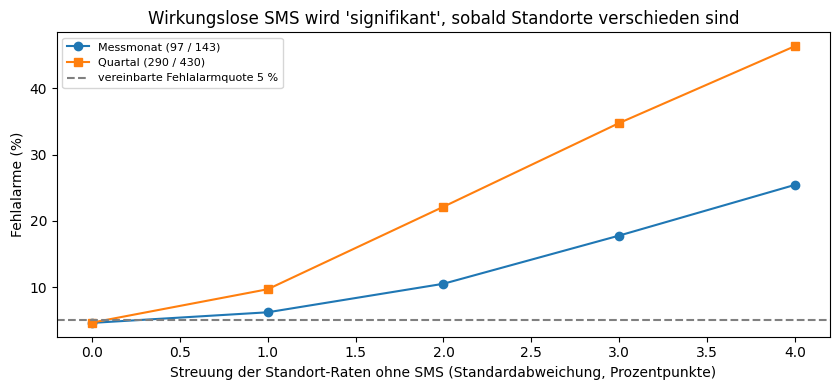

In [82]:
# Diagramm 2: Fehlalarmquote, wenn der Standort die Einheit der Zuteilung ist (SMS wirkungslos)
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(
    cluster["SD der Standort-Raten (Pp)"],
    cluster["Fehlalarme Messmonat 97 / 143 (%)"],
    marker="o",
    label="Messmonat (97 / 143)",
)
ax.plot(
    cluster["SD der Standort-Raten (Pp)"],
    cluster["Fehlalarme Quartal 290 / 430 (%)"],
    marker="s",
    label="Quartal (290 / 430)",
)
ax.axhline(100 * ALPHA, color="grey", ls="--", label="vereinbarte Fehlalarmquote 5 %")
ax.set_xlabel(
    "Streuung der Standort-Raten ohne SMS (Standardabweichung, Prozentpunkte)"
)
ax.set_ylabel("Fehlalarme (%)")
ax.set_title("Wirkungslose SMS wird 'signifikant', sobald Standorte verschieden sind")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Kernaussage:** Wenn die SMS wirkungslos ist und sich Standorte nur um 3 Prozentpunkte in ihrer Grundrate streuen, wird der Plan in 18 % (Messmonat) bis 35 % (Quartal) der Fälle fälschlich „signifikant“ statt in 5 %. Mehr Besuche machen es schlimmer, weil sie den Standortunterschied nur präziser messen.

### Voraussetzung 3 – Keine Interferenz zwischen den Armen: **nicht erfüllt, in beide Richtungen**

> **Beleg 1 (Während des Tests):** „Der Manager von Downtown hörte von der Initiative und begann, seinen eigenen Patienten Erinnerungs-E-Mails zu senden.“

Die Kontrolle erlebt nicht mehr den Status quo. Das ist **Leakage** und damit **Bias, kein Rauschen**: Der messbare Unterschied schrumpft in Richtung null, und mehr Daten machen die falsche Antwort nur präziser. Menschen setzen die Variante um (hier aus Neugier und Fairnessgefühl), deshalb ist Leakage hier kein theoretisches Risiko.

> **Beleg 2 (Während des Tests):** „begann Patienten ohne hinterlegte Mobilnummer telefonisch anzurufen“

Das ist streng genommen kein Leakage in die Kontrolle, sondern eine **Zusatzmaßnahme im Treatment-Arm**: Riverside bekommt nach zwei Wochen SMS **plus** Anrufe und erreicht sogar Patienten, die gar keine SMS erhalten können. Die Behandlung ist über den Test nicht mehr dieselbe, ein Unterschied wäre der SMS nicht mehr zuzuschreiben.

In [83]:
# ------------------------------------------------------------
# Voraussetzung 3: Interferenz = BIAS, nicht nur Rauschen.
# Downtown (Kontrolle) schickt "seinen eigenen Patienten Erinnerungs-E-Mails". Erreicht das einen Anteil x der Kontrolle
# und wirkt eine E-Mail so gut wie die SMS, schrumpft der messbare Unterschied auf  2 Pp * (1 - x).
# ANNAHME (zur Veranschaulichung): E-Mail-Wirkung = SMS-Wirkung; Baseline 10 %.
# ------------------------------------------------------------
p0 = 0.10
zeilen = []
for x in (0.0, 0.25, 0.50, 0.75):
    delta_sichtbar = ERWARTETER_EFFEKT * (1 - x)  # erwartete Differenz im Test
    zeilen.append(
        {
            "Anteil der Kontrolle mit E-Mail x": f"{x:.0%}",
            "sichtbarer Unterschied (Pp)": delta_sichtbar * 100,
            "nötige Besuche pro Gruppe (Power 80 %)": np.ceil(
                n_pro_gruppe(p0, p0 - delta_sichtbar)
            ),
            "Faktor gegenüber x = 0": n_pro_gruppe(p0, p0 - delta_sichtbar)
            / n_pro_gruppe(p0, p0 - ERWARTETER_EFFEKT),
        }
    )
leak = pd.DataFrame(zeilen)
print(
    "Mehr Daten beheben das nicht: Die Differenz zeigt dauerhaft in Richtung 0, die Schätzung wird nur präziser falsch."
)
leak.round(2)

Mehr Daten beheben das nicht: Die Differenz zeigt dauerhaft in Richtung 0, die Schätzung wird nur präziser falsch.


,Anteil der Kontrolle mit E-Mail x,sichtbarer Unterschied (Pp),nötige Besuche pro Gruppe (Power 80 %),Faktor gegenüber x = 0
0,0%,2.0,3205.0,1.00
1,25%,1.5,5848.0,1.82
2,50%,1.0,13488.0,4.21
3,75%,0.5,55244.0,17.24


**Lesart:** Erreichen die E-Mails die Hälfte der Kontrolle und wirken sie so gut wie die SMS (Annahme), sieht man statt 2 nur noch 1 Prozentpunkt Unterschied. Für denselben Nachweis braucht man das **4,2-Fache** an Besuchen (13.488 statt 3.205 pro Gruppe bei 10 % Baseline).

### Voraussetzung 4 – Gleichzeitigkeit: **nicht erfüllt, durch Umschreiben reparierbar**

> **Beleg (Messung):** „No-Show-Rate von Riverside im März mit der Rate von Downtown im Februar“

Der Plan vergleicht zwei **Standorte** in zwei **Monaten**. Saison, Feiertage, Wochentagsverteilung und Monatslänge treffen daher nur einen Arm. Die Tabelle zu Voraussetzung 1 hat das schon gezeigt: Der „Unterschied ohne SMS“ enthält Standort- *und* Monatseffekt, und der Test kann beide nicht von der SMS trennen. **Reparatur:** beide Arme im selben Zeitfenster, in ganzen Wochen.

### Voraussetzung 5 – Vorab deklarierte primäre Kennzahl: **nicht erfüllt, durch Umschreiben reparierbar**

Drei getrennte Mängel:

1. **Nicht identisch gemessen.**
   > **Beleg (Messung):** „weil die Februar-Zahlen für die Quartalsreview bereits bereinigt und geladen wurden“

   Die Downtown-Zahlen kommen aus einer bereits bereinigten Auswertung, die März-Zahlen von Riverside durchlaufen sie nicht. Die Kennzahl muss in beiden Armen dieselbe Definition, Quelle und Aufbereitung haben. Dazu passt der Befund aus Checkpoint 1: Die Definition von `no_show` war in den Daten nicht eindeutig (alle No-Show-Besuche hatten Wartezeit, Dauer und Kosten). Sie muss **vor** dem Test mit dem Datenlieferanten geklärt werden.
2. **Mehrere Kennzahlen, Auswahl nach dem Ergebnis.**
   > **Beleg (Berichterstattung):** „berichten, was sich davon bewegt“

   Vier Kennzahlen (No-Shows, Wartezeit, Zufriedenheit, Umsatz pro Besuch) mit freier Auswahl sind das Problem der Mehrfachtests in anderer Verpackung.
3. Das **Ziel** („Zeigen, dass die SMS-Erinnerung No-Shows reduziert“) nennt zwar No-Shows, legt aber keine einzige Kennzahl mit Test und α vorab fest und formuliert ein *erwünschtes* Ergebnis statt einer prüfbaren Frage.

In [84]:
# ------------------------------------------------------------
# Voraussetzung 5: "berichten, was sich davon bewegt" = vier Kennzahlen, ein Urteil.
# Gibt es in Wahrheit KEINEN Effekt, steigt die Chance auf mindestens einen "Treffer" mit der Zahl der Kennzahlen m.
# ------------------------------------------------------------
m = 4  # No-Shows, Wartezeit, Zufriedenheit, Umsatz pro Besuch
analytisch = 1 - (1 - ALPHA) ** m
bonferroni = ALPHA / m

# Simulation: m unabhängige Kennzahlen ohne echten Unterschied, Gruppen 97 und 143 Besuche, je ein t-Test
n_sim = 10_000
a = rng.normal(size=(n_sim, m, N_RIVERSIDE_MONAT))
b = rng.normal(size=(n_sim, m, N_DOWNTOWN_MONAT))
p_werte = stats.ttest_ind(a, b, axis=2).pvalue  # Form (n_sim, m)
mind_ein_treffer = (p_werte < ALPHA).any(axis=1).mean()
mind_ein_treffer_bonf = (p_werte < bonferroni).any(axis=1).mean()

print(f"Kennzahlen m = {m}")
print(
    f"Chance auf mindestens einen 'signifikanten' Treffer ohne echten Effekt: analytisch {analytisch:.1%}, simuliert {mind_ein_treffer:.1%}"
)
print(
    f"Mit Bonferroni (alpha / m = {bonferroni:.4f}): simuliert {mind_ein_treffer_bonf:.1%}"
)
print(
    "-> Die EINE vorab festgelegte Kennzahl hält die Fehlalarmquote bei alpha; vier Kennzahlen mit freier Auswahl nicht."
)

Kennzahlen m = 4
Chance auf mindestens einen 'signifikanten' Treffer ohne echten Effekt: analytisch 18.5%, simuliert 19.1%
Mit Bonferroni (alpha / m = 0.0125): simuliert 5.0%
-> Die EINE vorab festgelegte Kennzahl hält die Fehlalarmquote bei alpha; vier Kennzahlen mit freier Auswahl nicht.


### Voraussetzung 6 – Ausreichende Power: **nicht nachgewiesen** (und unter allen gerechneten Annahmen klar unzureichend)

> **Beleg (Stichprobe):** „Riverside hat ungefähr 290 Besuche pro Quartal, Downtown ungefähr 430. Das Team erwartet, dass die Erinnerung No-Shows um etwa 2 Prozentpunkte senkt.“

Analyseeinheit ist der **Besuch**. Gemessen wird aber nur **ein Monat**, also rund ein Drittel der Quartalszahlen (ca. 97 und 143 Besuche; Näherung Quartal / 3). Der Plan nennt weder Baseline-Rate noch α noch Mindesteffekt noch Stichprobengröße und kann deshalb nicht erklären, was ein Nullergebnis bedeuten würde. Weil die Baseline nicht bekannt ist, rechnen wir mit mehreren Annahmen. **Die Zahlen sind ein Szenario unter der großzügigen Annahme unabhängiger Besuche:** Bei Zuteilung nach Standort (ein Standort je Arm) ist die tatsächliche Aussagekraft noch geringer, weil die vielen Besuche nur einen Standort je Arm vertreten.

In [85]:
# ------------------------------------------------------------
# Voraussetzung 6: Ist die Teststärke ausreichend?  Analyseeinheit = Besuch.
# Die tatsächliche Baseline-Rate ist im Plan nicht genannt -> wir rechnen mit mehreren Annahmen für die Rate in Downtown.
# (10,75 % ist die Gesamt-No-Show-Quote aus Checkpoint 1 und nur ein Orientierungswert; hier wird kein Datensatz neu ausgewertet.)
# ------------------------------------------------------------
baselines = [0.05, 0.1075, 0.15, 0.20]
designs = {
    "Plan, Messmonat (97 / 143)": (N_RIVERSIDE_MONAT, N_DOWNTOWN_MONAT),
    "Plan, ganzes Quartal (290 / 430)": (N_RIVERSIDE_QUARTAL, N_DOWNTOWN_QUARTAL),
}

zeilen = []
for p0 in baselines:
    zeile = {"angenommene Baseline-Rate": f"{p0:.2%}"}
    for name, (n1, n2) in designs.items():
        zeile[f"Power bei 2 Pp: {name}"] = power_zwei_anteile(
            p0, p0 - ERWARTETER_EFFEKT, n1, n2
        )
        mde = mde_reduktion(p0, n1, n2)
        zeile[f"kleinste Senkung bei 80 % Power (Pp): {name}"] = (
            np.nan if np.isnan(mde) else mde * 100
        )
    zeilen.append(zeile)
power_tab = pd.DataFrame(zeilen).set_index("angenommene Baseline-Rate")
power_tab.round(2)

,"Power bei 2 Pp: Plan, Messmonat (97 / 143)","kleinste Senkung bei 80 % Power (Pp): Plan, Messmonat (97 / 143)","Power bei 2 Pp: Plan, ganzes Quartal (290 / 430)","kleinste Senkung bei 80 % Power (Pp): Plan, ganzes Quartal (290 / 430)"
angenommene Baseline-Rate,,,,
5.00%,0.12,4.83,0.27,3.59
10.75%,0.08,8.52,0.14,5.66
15.00%,0.07,10.51,0.12,6.75
20.00%,0.07,12.40,0.10,7.77


In [86]:
# Gegenprobe der analytischen Power per Simulation (Baseline 10,75 %, Senkung um 2 Pp, Messmonat 97 / 143)
p0 = 0.1075
n_sim = 20_000
x_r = rng.binomial(
    N_RIVERSIDE_MONAT, p0 - ERWARTETER_EFFEKT, n_sim
)  # Riverside MIT SMS
x_d = rng.binomial(N_DOWNTOWN_MONAT, p0, n_sim)  # Downtown ohne SMS
sim_power = (
    ztest_zwei_anteile(x_r, N_RIVERSIDE_MONAT, x_d, N_DOWNTOWN_MONAT)[1] < ALPHA
).mean()
ana_power = power_zwei_anteile(
    p0, p0 - ERWARTETER_EFFEKT, N_RIVERSIDE_MONAT, N_DOWNTOWN_MONAT
)
print(f"Power analytisch {ana_power:.1%} | simuliert {sim_power:.1%}")
print(
    f"-> Selbst wenn alles andere stimmte, würde der Test einen echten 2-Prozentpunkte-Effekt nur in etwa {min(sim_power, ana_power):.0%} bis {max(sim_power, ana_power):.0%} der Fälle finden."
)
print(
    "   (Die beiden Werte unterscheiden sich leicht, weil bei so kleinen Gruppen die Normalnäherung grob ist; die Größenordnung ist dieselbe.)"
)
print(
    "   Ein nicht signifikantes Ergebnis wäre also KEIN Beleg für 'die SMS wirkt nicht'."
)

Power analytisch 8.1% | simuliert 7.0%
-> Selbst wenn alles andere stimmte, würde der Test einen echten 2-Prozentpunkte-Effekt nur in etwa 7% bis 8% der Fälle finden.
   (Die beiden Werte unterscheiden sich leicht, weil bei so kleinen Gruppen die Normalnäherung grob ist; die Größenordnung ist dieselbe.)
   Ein nicht signifikantes Ergebnis wäre also KEIN Beleg für 'die SMS wirkt nicht'.


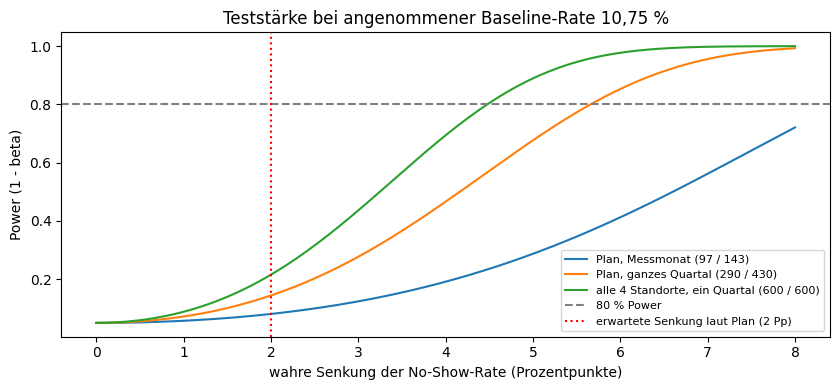

In [87]:
# Diagramm 1: Power in Abhängigkeit von der wahren Senkung (Baseline 10,75 %)
p0 = 0.1075
senkung = np.linspace(0, 0.08, 200)
kurven = {
    "Plan, Messmonat (97 / 143)": (N_RIVERSIDE_MONAT, N_DOWNTOWN_MONAT),
    "Plan, ganzes Quartal (290 / 430)": (N_RIVERSIDE_QUARTAL, N_DOWNTOWN_QUARTAL),
    "alle 4 Standorte, ein Quartal (600 / 600)": (600, 600),
}
fig, ax = plt.subplots(figsize=(8.5, 4))
for name, (n1, n2) in kurven.items():
    ax.plot(
        senkung * 100,
        [power_zwei_anteile(p0, p0 - d, n1, n2) for d in senkung],
        label=name,
    )
ax.axhline(POWER_ZIEL, color="grey", ls="--", label="80 % Power")
ax.axvline(
    ERWARTETER_EFFEKT * 100,
    color="red",
    ls=":",
    label="erwartete Senkung laut Plan (2 Pp)",
)
ax.set_xlabel("wahre Senkung der No-Show-Rate (Prozentpunkte)")
ax.set_ylabel("Power (1 - beta)")
ax.set_title("Teststärke bei angenommener Baseline-Rate 10,75 %")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Kernaussage:** Unter der Annahme unabhängiger Besuche und bei einer angenommenen Baseline von 10,75 % erkennt der Plan eine echte Senkung um 2 Prozentpunkte nur mit etwa 8 % (Messmonat) bzw. 14 % (Quartal) Wahrscheinlichkeit. Die 80-%-Marke erreicht er erst bei einer Senkung um etwa 8,5 bzw. 5,7 Prozentpunkten, ein Test über alle vier Standorte in einem Quartal bei etwa 4,5. Ein **nicht signifikantes Ergebnis wäre daher kein Beleg für „die SMS wirkt nicht“.**

### Übersicht: Sechs Voraussetzungen im Überblick

| # | Voraussetzung | Erfüllt? | Zitat aus dem Plan | Lässt sich durch Umschreiben beheben? |
|---|---|---|---|---|
| 1 | Zufällige Zuteilung | **nein** | „weil sich der Site Manager freiwillig gemeldet hat und weil die No-Show-Rate dort am höchsten ist“ | **nein**, in der Struktur des Vergleichs eingebaut |
| 2 | Unabhängigkeit der Einheiten | **nein** (belegt: Einheit = Standort) | „Riverside erhält im gesamten März die neue SMS-Erinnerung. Downtown behält den aktuellen Prozess ohne Erinnerung bei und dient als Kontrolle.“ | **nein**, Folge von 1: Einheit = Standort (1 gegen 1) |
| 3 | Keine Interferenz | **nein** | „Der Manager von Downtown hörte von der Initiative und begann, seinen eigenen Patienten Erinnerungs-E-Mails zu senden.“ / „begann Patienten ohne hinterlegte Mobilnummer telefonisch anzurufen“ | nur durch Protokoll und anderes Design (Zuteilung unterhalb des Standorts) |
| 4 | Gleichzeitigkeit | **nein** | „No-Show-Rate von Riverside im März mit der Rate von Downtown im Februar“ | **ja**, beide Arme im selben Zeitfenster |
| 5 | Vorab festgelegte primäre Kennzahl | **nein** | „weil die Februar-Zahlen für die Quartalsreview bereits bereinigt und geladen wurden“ / „berichten, was sich davon bewegt“ | **ja**, eine Kennzahl, gleiche Definition, vorab festgelegt |
| 6 | Ausreichende Power | **nicht nachgewiesen** (unter allen gerechneten Annahmen klar unzureichend) | „Riverside hat ungefähr 290 Besuche pro Quartal, Downtown ungefähr 430.“ / „um etwa 2 Prozentpunkte senkt“ | nur teilweise, hängt vom Design und von der Zahl der Einheiten ab |

## Aufgabe 2 – Das Urteil und was sich ändern müsste

### Urteil in einem Satz

**Der Plan darf in dieser Form nicht als A/B-Test durchgeführt werden, weil die SMS-Erinnerung nicht zufällig, sondern nach Standort an einen Standort vergeben wird, der sich freiwillig gemeldet hat und laut Plan die höchste No-Show-Rate hat, sodass der Effekt der SMS vom Standort nicht zu trennen ist, egal wie viele Besuche man auswertet.**

Der zusätzliche Monatsunterschied (Riverside im März gegen Downtown im Februar) verfälscht den Vergleich ebenfalls, ließe sich aber durch Umschreiben beheben (beide Gruppen im selben Zeitfenster). Die Zuteilung nach Standort lässt sich nicht umschreiben.

### Die ausschlaggebende Verletzung: Voraussetzung 1 (mit ihrer strukturellen Folge, Voraussetzung 2)

**Behandlung und Standort fallen zusammen.** Solange genau ein Standort die SMS bekommt und genau einer nicht, ist „hat die SMS erhalten“ nur ein anderes Wort für „ist Riverside“.

**Warum eine bloße Umformulierung das nicht behebt:** Man kann die Kennzahl neu definieren, beide Arme in den März legen und Anrufe und E-Mails verbieten. Der Vergleich bleibt „ein Standort gegen einen Standort“. Auch mehr Daten helfen nicht, denn die Simulationen zeigen, dass die Fehlalarme mit der Besuchszahl *steigen* (Cluster-Tabelle) und der Scheinerfolg häufiger wird (Konfundierungs-Tabelle). Behoben wird das nur durch eine **andere Randomisierungseinheit unterhalb des Standorts**.

### Warum die anderen Verletzungen für sich genommen nicht ausschlaggebend sind

- **Gleichzeitigkeit (4) und Kennzahl (5):** Umschreiben genügt (beide Arme im selben Zeitfenster; eine Kennzahl aus derselben Quelle).
- **Interferenz (3):** Bei Zuteilung auf Patientenebene lässt sie sich mit einem Protokoll (keine zusätzlichen Erinnerungen für beide Gruppen) und einer Zählung von Abweichungen eindämmen.
- **Power (6):** Die Stichprobengröße ist eine Planungsgröße. Sie lässt sich mit mehr Einheiten oder einem größeren Mindesteffekt lösen, **aber nur**, wenn unterhalb des Standorts randomisiert wird. Bei Standortzuteilung erhöhen mehr Besuche nicht die Zahl unabhängiger Einheiten. Power ist zugleich die Voraussetzung, die auch nach dem Neuaufbau noch scheitern kann (siehe unten, Plan B).

### Wo ein signifikantes Ergebnis möglich wäre, ohne die Wirkung der SMS zu belegen

Im **Vergleich selbst**: Riverside (März) gegen Downtown (Februar) kann „signifikant niedriger“ ausfallen, obwohl die SMS nichts bewirkt, durch den Standort- und Monatsunterschied (Konfundierungs-Tabelle: 27 % bis 70 % der Fälle bei 5 Pp Vorab-Unterschied), durch die Rückkehr zum Mittelwert (ca. 1,3 Pp ohne jede Maßnahme, fast so viel wie die erwarteten 2 Pp) und durch die Berichterstattung „was sich bewegt“ (19 % Chance auf mindestens einen Treffer bei vier Kennzahlen ohne echten Effekt). Ein kleiner p-Wert zeigt nur, **dass** sich die Gruppen unterscheiden, nicht **warum**.

### Eine Frage, die sich mit den vorliegenden Daten nicht beantworten lässt

*„Senkt die SMS-Erinnerung die No-Show-Rate, und um wie viel?“* `solace_visits.csv` enthält keine Angabe, ob ein Patient eine Erinnerung erhalten hat (Prüfung der Spaltenköpfe unten). Die Frage ist deshalb mit keiner Analyse dieser Daten beantwortbar, auch nicht mit dem Standortvergleich aus Checkpoint 3.

In [88]:
# Prüfung zur Aussage "der Datensatz enthält keine Angabe zu Erinnerungen": Wir sehen NUR die Spaltennamen
# des zentral geladenen Datensatzes (keine Auswertung, kein erneutes Einlesen der CSV).
spalten = df_roh.columns.tolist()
print("Spalten:", spalten)
treffer = [
    c
    for c in spalten
    if any(
        w in c.lower()
        for w in ("remind", "sms", "erinner", "notif", "message", "contact")
    )
]
print("Spalten mit Bezug zu Erinnerungen:", treffer if treffer else "keine")
assert not treffer

Spalten: ['visit_id', 'patient_id', 'appointment_date', 'clinic_site', 'appointment_type', 'insurance_type', 'day_of_week', 'no_show', 'wait_time_min', 'patient_satisfaction', 'scheduled_duration_min', 'actual_duration_min', 'visit_cost', 'zip_code']
Spalten mit Bezug zu Erinnerungen: keine


### Der überarbeitete Versuchsplan

**Natürliche Randomisierungseinheit:** nicht der Standort, sondern der **Patient** mit einem Termin im Testfenster (Alternative aus dem Kurs: der einzelne Termin). Ein Patient bekommt eine Zuweisung, die für alle seine Termine im Fenster gilt, damit niemand beide Arme erlebt. Patienten desselben Wartezimmers beeinflussen sich bei einer SMS nicht, die Einheit ist fein genug und die Kontamination dennoch ausgeschlossen.

| Feld | Festlegung (vor dem Start schriftlich) |
|---|---|
| **Frage** | Senkt eine SMS-Erinnerung 24 Stunden vor dem Termin den Anteil nicht wahrgenommener Termine? |
| **H₀ / H₁** | H₀: Der Anteil der No-Shows ist in beiden Gruppen gleich. H₁: Er ist verschieden. **Zweiseitig**, weil auch eine Verschlechterung eine Entscheidung auslösen würde; die Seite folgt aus der Fragestellung und steht vor den Daten fest. |
| **Zuteilung** | **Die Standorte selbst werden nicht als Treatment oder Kontrolle randomisiert.** Innerhalb jedes teilnehmenden Standorts werden die geeigneten Patienten per Zufallszahlengenerator im Terminsystem im Verhältnis 1:1 (P = 0,5) der Treatment- oder Kontrollgruppe zugeteilt, die Zuteilung wird vor dem Test gespeichert. Keine Entscheidung durch Personal, keine Zuteilung nach Wochentag oder ID-Ziffer. **Alle vier Standorte** nehmen teil. |
| **Zeitfenster** | Beide Gruppen **gleichzeitig**, in ganzen Wochen. Nicht vorzeitig beenden (kein Peeking): Die Stoppregel ist die vorab festgelegte Stichprobengröße. |
| **Kontrolle** | Bisheriger Prozess ohne Erinnerung. **Protokoll:** In beiden Gruppen keine zusätzlichen Erinnerungen (keine Anrufe, keine E-Mails). Abweichungen werden gezählt. |
| **Teilnehmende** | Nur Patienten mit hinterlegter Mobilnummer (vorab festgelegt). Der Anteil ohne Nummer wird berichtet. Das Ergebnis gilt nur für Patienten mit Nummer. |
| **Primäre Kennzahl** | No-Show (0/1) je Termin, Anteil je Gruppe. In beiden Gruppen gleich definiert, aus derselben Quelle, die Definition ist vorab mit dem Datenlieferanten geklärt. |
| **Guardrails** | Wartezeit, Zufriedenheit (Rücklaufquote beachten), Umsatz pro Besuch. Vorab benannt, nur beschreibend, nie nachträglich Teil des Urteils. |
| **α und Power** | α = 0,05 (zweiseitig), Power 80 %. |
| **Mindesteffekt (MDE)** | Legt Operations vorab fest (kleinste Senkung, die eine Einführung rechtfertigt). Szenarien: 2, 3 und 5 Prozentpunkte. |
| **Analyse** | **Ein** Zwei-Anteile-Test auf die primäre Kennzahl, dazu das Konfidenzintervall der Differenz. |

**Wie der neue Plan die sechs Voraussetzungen erfüllt:** (1) Zufallszahlengenerator, (2) Einheit Patient, (3) Protokoll gegen Zusatzkontakte plus Zählung, (4) gleichzeitig, (5) eine vorab festgelegte Kennzahl, (6) n aus MDE, α und Power. Zur Stichprobengröße:

In [89]:
# ------------------------------------------------------------
# Überarbeiteter Versuchsplan: Wie viele Besuche braucht ein gültiger Test, und passt das in ein Quartal?
# Einheit = Patient/Termin, Zuteilung per Zufall, alle vier Standorte gleichzeitig.
# Verfügbare Termine: 1.200 pro Quartal an allen vier Standorten (Gesamtzahl aus Checkpoint 1; hier nicht neu ausgewertet).
# Untergrenze für die Dauer: Nicht alle Patienten haben eine hinterlegte Mobilnummer - der Anteil ist unbekannt (Annahme 100 %).
# ------------------------------------------------------------
TERMINE_PRO_QUARTAL = 1200
zeilen = []
for p0 in (0.05, 0.1075, 0.15, 0.20):
    for mde in (0.02, 0.03, 0.05):
        n_arm = int(np.ceil(n_pro_gruppe(p0, p0 - mde)))
        zeilen.append(
            {
                "Baseline-Rate": f"{p0:.2%}",
                "MDE (Pp)": mde * 100,
                "Besuche pro Gruppe": n_arm,
                "Besuche gesamt": 2 * n_arm,
                "Dauer in Quartalen (1.200 Termine / Quartal)": 2
                * n_arm
                / TERMINE_PRO_QUARTAL,
            }
        )
plan_n = pd.DataFrame(zeilen)
plan_n.round(2)

,Baseline-Rate,MDE (Pp),Besuche pro Gruppe,Besuche gesamt,Dauer in Quartalen (1.200 Termine / Quartal)
0,5.00%,2.0,1484,2968,2.47
1,5.00%,3.0,562,1124,0.94
2,5.00%,5.0,78,156,0.13
3,10.75%,2.0,3445,6890,5.74
4,10.75%,3.0,1456,2912,2.43
5,10.75%,5.0,465,930,0.78
6,15.00%,2.0,4720,9440,7.87
7,15.00%,3.0,2031,4062,3.38
8,15.00%,5.0,681,1362,1.14
9,20.00%,2.0,6036,12072,10.06


In [90]:
# Umgekehrt gefragt: Was kann ein Test mit allen vier Standorten in EINEM Quartal (600 je Gruppe) überhaupt erkennen?
zeilen = []
for p0 in (0.05, 0.1075, 0.15, 0.20):
    mde = mde_reduktion(p0, 600, 600)
    zeilen.append(
        {
            "Baseline-Rate": f"{p0:.2%}",
            "kleinste erkennbare Senkung (Pp)": mde * 100,
            "relativ zur Baseline": f"{mde / p0:.0%}",
        }
    )
pd.DataFrame(zeilen).round(2)

,Baseline-Rate,kleinste erkennbare Senkung (Pp),relativ zur Baseline
0,5.00%,2.92,58%
1,10.75%,4.48,42%
2,15.00%,5.29,35%
3,20.00%,6.05,30%


**Was die Zahlen für den Plan bedeuten:**
- **Die 2 Prozentpunkte aus dem Plan passen nicht in ein Quartal.** Bei einer Baseline von 10,75 % braucht man 3.445 Besuche pro Gruppe, zusammen 6.890 Termine. Bei etwa 1.200 Terminen pro Quartal an allen vier Standorten sind das rund **5,7 Quartale**, also etwa anderthalb Jahre.
- **Was in einem Quartal möglich ist:** Mit 600 Besuchen pro Gruppe erkennt der Test erst eine Senkung ab etwa **4,5 Prozentpunkten** (42 % der Baseline). Ein Nullergebnis hieße dann nur: „Ein Effekt dieser Größe ist unwahrscheinlich“, nicht „es gibt keinen Effekt“.
- Operations muss deshalb **vorab entscheiden**: einen größeren MDE akzeptieren (5 Pp brauchen etwa 0,8 Quartale), länger laufen lassen oder Plan B wählen. Die Dauer ist eine **Untergrenze**, weil der Anteil der Patienten mit Mobilnummer unbekannt ist.
- Die Baseline ist eine Annahme. Je höher sie ist, desto mehr Besuche braucht man (bei 20 % und 2 Pp über 12.000 Termine).

### Plan B – falls der gültige Test unmöglich oder zu teuer ist

Der Kurs nennt als Fehlsituation: Eine Population zu klein für die Power, oder das Vorenthalten kostet zu viel. Dann ist das **Instrument** ausgeschlossen, nicht die Frage. Mein Vorschlag:

1. **Einführen und überwachen** statt testen: SMS an allen Standorten einführen, aber **gestaffelt mit zufällig ausgelosten Startterminen je Standort**. Die No-Show-Rate wird wöchentlich mit derselben Definition und Quelle überwacht (Vorquartale als Vergleich), die Guardrails laufen mit.
2. **Falls auch das nicht möglich ist:** eine Beobachtungsanalyse (z. B. Vorher-Nachher je Standort) und ihre Ergebnisse ausdrücklich als **Zusammenhang** formulieren, nicht als nachgewiesene Wirkung der SMS.
3. **Aussagegrenze offen benennen:** Das liefert einen *Hinweis*, keinen kausalen Beleg. Zeit- und Standorteffekte bleiben, und bei nur vier Standorten ist die Staffelung statistisch schwach.
4. **Entscheidungsgrundlage verschieben:** Ist die SMS billig und unwahrscheinlich schädlich (Annahme, Kosten stehen nicht in den Unterlagen), kann die Einführung auch **ohne Nachweis eines 2-Prozentpunkte-Effekts** begründet sein. Dann braucht Operations keinen Test, sondern eine Kosten-Nutzen-Rechnung und die Überwachung.

### Aussagegrenzen dieser Prüfung

- Es ist eine **Design-Review**: Wir haben keinen Datensatz ausgewertet. Baseline-Raten, Standortstreuung, E-Mail-Wirkung und die Besuchszahlen der beiden anderen Standorte sind **Annahmen** und als solche im Code gekennzeichnet.
- „Ein Monat ≈ ein Drittel des Quartals“ ist eine Näherung. Die Power-Zahlen hängen stark von der angenommenen Baseline ab. Die Aussage „viel zu klein“ gilt aber für jede der vier gerechneten Baselines.
- Die Simulationen zeigen, was die Verletzungen bewirken **können**, nicht was in Riverside und Downtown tatsächlich passiert wäre.
- Offen für Operations: der Mindesteffekt, der Anteil der Patienten mit Mobilnummer und die Definition von `no_show`.

### Entscheidungsprotokoll Checkpoint 4

| # | Entscheidung | Nicht gewählte Alternative | Begründung | Geprüft durch |
|---|---|---|---|---|
| 1 | Plan nicht durchführen, neu aufbauen | Plan beibehalten und nur Kennzahl und Zeitfenster korrigieren | Zuteilung nach Standort lässt sich nicht umschreiben | Konfundierungs- und Cluster-Simulation |
| 2 | Randomisierungseinheit Patient | Standort (Cluster) oder einzelner Termin | Standort: nur 4 Einheiten, kaum Power. Termin: derselbe Patient könnte beide Arme erleben | Cluster-Simulation (Standort-Einheit) |
| 3 | Mindesteffekt offen lassen, Szenarien 2 / 3 / 5 Pp | 2 Pp aus dem Plan als feste MDE | Der MDE ist eine Entscheidung nach Nutzen und Kosten, die Operations treffen muss | Stichprobentabelle, Dauer |
| 4 | Baseline als Spanne (5 bis 20 %) | Einzelwert aus den Daten | Aufgabe verlangt eine Review ohne Datenauswertung | Power-Tabelle |
| 5 | Formel mit Cohens *h* | Klassische Varianzformel | Reproduziert die Referenztabelle exakt (Stichprobengrößen-Tabelle aus dem Lernstoff zum A/B-Testing, Sprint 4) | Kontrolle gegen die Referenztabelle |
| 6 | Voraussetzung 2 als „nicht erfüllt“ werten | „nicht ausreichend abgesichert“ | Der Plan weist je Arm einen Standort zu (1 gegen 1): belegt, nicht nur unklar | Cluster-Simulation |
| 7 | Zweiseitiger Test | Einseitig („SMS senkt“) | Auch eine Verschlechterung hätte Folgen, die Seite folgt aus der Fragestellung | – |

---

# Abschließende Einordnung – Zusammenfassung, Aussagegrenzen und Konsequenzen

Dieser Abschnitt führt die vier Checkpoints zusammen. Er ist für Leserinnen und Leser gedacht, die das Notebook nicht gelesen haben. Alle Zahlen werden in der nächsten Code-Zelle gegen die Auswertung geprüft.

### 1. Was wollte Solace wissen, und wie verlässlich waren die Daten?

Solace wollte drei Dinge wissen: (a) Hält Downtown sein Serviceversprechen „im Durchschnitt weniger als 15 Minuten Wartezeit“ ein? (b) Wartet man in Riverside tatsächlich länger als in Downtown, wie der Standortleiter bestreitet? (c) Senkt eine SMS-Erinnerung die No-Shows?

Die Besuchsdaten (1.209 Zeilen, ein Quartal, vier Standorte) waren **brauchbar, aber nicht blind verwendbar**: 9 exakte Duplikate, bei 10,2 % der Besuche fehlt die Zufriedenheit (vor allem bei Urgent), 14 Dauerwerte liegen beim 5,7- bis 13-Fachen der geplanten Zeit, und alle 129 No-Show-Besuche haben trotzdem Wartezeit, Dauer und Kosten. Keines dieser Probleme ändert die beiden Testergebnisse; sie begrenzen aber, was wir über Dauer, Zufriedenheit und No-Shows sagen können.

### 2. Was die beiden abgeschlossenen Tests belegen und was nicht

**Serviceversprechen (Downtown):** Patienten in Downtown warten im Schnitt **12,2 Minuten**. Das Intervall, das mit den Daten vereinbar ist, reicht von 11,41 bis 12,95 Minuten; für den einseitigen Test liegt die Obergrenze bei 12,8 Minuten. Die Nullhypothese „15 Minuten oder mehr“ wird verworfen, das Ergebnis ist statistisch signifikant. *Belegt:* Im Durchschnitt wird das Versprechen in diesem Quartal eingehalten. *Nicht belegt:* dass jede einzelne Person unter 15 Minuten wartet (28 % warten länger), und nichts über künftige Quartale.

**Standortvergleich:** Riverside wartet im Schnitt **20,8 Minuten**, Downtown 12,2 Minuten, also **8,6 Minuten länger**. Der plausible Bereich für den wahren Unterschied liegt zwischen 7,3 und 9,8 Minuten (Effektgröße d = 1,04, groß). Die Behauptung des Standortleiters ist nicht haltbar. Gemessen an der nachträglich festgelegten Mindestdifferenz von 5 Minuten ist der Unterschied auch praktisch relevant. *Nicht belegt:* **warum** Riverside länger wartet und ob zusätzliches Personal das Problem löst. Der Vergleich ist beobachtend, kein Experiment.

### 3. Entscheidungen im Daten-Audit (mit der nicht gewählten Alternative)

- **Duplikate:** Nur die 9 exakt identischen Zeilen entfernen, und zwar vor allen Auswertungen. *Nicht gewählt:* Patient + Datum als Regel, die 58 Zeilen markiert und 40 echte Besuche zerstört hätte.
- **Dauer-Fehler:** Die 14 abgesetzten Dauerwerte markieren statt löschen oder korrigieren. *Nicht gewählt:* löschen oder durch 10 teilen, denn die Ursache ist nur vermutet und muss der Datenlieferant bestätigen.
- **Kennzahl für die Folie:** Median der Besuchskosten (157). *Nicht gewählt:* Mittelwert (191), der eher die Frage „Was kosten die Besuche insgesamt?“ beantwortet.

### 4. Urteil zum vorgeschlagenen SMS-Test

**Der Plan darf in dieser Form nicht als A/B-Test durchgeführt werden, weil die SMS-Erinnerung nicht zufällig, sondern nach Standort an einen Standort vergeben wird, der sich freiwillig gemeldet hat und laut Plan die höchste No-Show-Rate hat, sodass ihr Effekt vom Standort nicht zu trennen ist, egal wie viele Besuche man auswertet.** Der zusätzliche Monatsunterschied (März gegen Februar) ließe sich durch Umschreiben beheben, die Zuteilung nach Standort nicht. Geeignet wäre eine Zufallszuteilung auf Patientenebene innerhalb aller vier Standorte, im selben Zeitfenster, mit einer vorab festgelegten Kennzahl (No-Show je Termin) und einem Mindesteffekt, aus dem sich die Besuchszahl ergibt. Die erwarteten 2 Prozentpunkte würden bei dem Datenvolumen von Solace etwa anderthalb Jahre Laufzeit benötigen. Ist das nicht vertretbar, bleibt die gestaffelte Einführung mit Überwachung, deren Ergebnis nur als Hinweis gilt.

### 5. Was sich mit diesen Daten nicht beantworten lässt

- **Wirkt die SMS-Erinnerung, und um wie viel?** Der Datensatz enthält keine Angabe zu Erinnerungen.
- **Warum wartet man in Riverside länger?** Die Daten zeigen den Unterschied, nicht die Ursache.
- **Was ist ein No-Show?** Alle 129 No-Show-Besuche haben Wartezeit, Dauer und Kosten. Das muss der Datenlieferant klären, bevor eine No-Show-Auswertung belastbar ist.

In [91]:
# ------------------------------------------------------------
# Zahlen-Check für den Schlussabschnitt: jede genannte Zahl wird hier aus den Daten neu berechnet
# ------------------------------------------------------------
dt = df[df.clinic_site == "Downtown"].wait_time_min.dropna()
rv = df[df.clinic_site == "Riverside"].wait_time_min.dropna()

assert (len(df_roh), len(df), int(df.no_show.sum())) == (
    1209,
    1200,
    129,
)  # Zeilen, Duplikate, No-Shows
assert df_roh.duplicated().sum() == 9  # 9 exakte Duplikate
assert (
    abs(100 * df.patient_satisfaction.isna().sum() / len(df) - 10.25) < 1e-9
)  # fehlende Zufriedenheit: 123 von 1.200 = 10,25 % (im Text 10,2 % wie in den Diagrammen)
assert round(dt.mean(), 1) == 12.2 and round(rv.mean(), 1) == 20.8  # Mittelwerte
assert round(rv.mean() - dt.mean(), 1) == 8.6  # Differenz
assert (
    round(ci_low, 1) == 7.3 and round(ci_high, 1) == 9.8 and round(cohens_d, 2) == 1.04
)  # KI und Effektgröße
lo, hi = stats.t.interval(0.95, len(dt) - 1, loc=dt.mean(), scale=stats.sem(dt))
assert round(lo, 2) == 11.41 and round(hi, 2) == 12.95  # zweiseitiges KI Downtown
assert round(ki_ober_einseitig, 1) == 12.8  # einseitige Obergrenze
assert round(100 * (dt > 15).mean()) == 28  # Anteil über 15 Minuten
assert (
    round(df.visit_cost.median()) == 157 and round(df.visit_cost.mean()) == 191
)  # Median / Mittelwert

# Duplikat-Regel: Patient + Datum als Alternative
markiert = int(df_roh.duplicated(["patient_id", "appointment_date"], keep=False).sum())
exakt = int(df_roh.duplicated(keep=False).sum())
assert markiert == 58 and markiert - exakt == 40

# Dauer-Fehler: Verhältnis tatsächliche / geplante Dauer
verh = df.actual_duration_min / df.scheduled_duration_min
assert int((verh > 5).sum()) == 14 and round(verh[verh > 5].min(), 1) == 5.7

# No-Show-Widerspruch: alle No-Show-Besuche haben trotzdem Wartezeit, Dauer und Kosten
ns = df[df.no_show == 1]
assert (
    ns.wait_time_min.notna().all()
    and (ns.actual_duration_min > 0).all()
    and (ns.visit_cost > 0).all()
)
print("Alle Zahlen im Schlussabschnitt stimmen mit den Daten überein.")

Alle Zahlen im Schlussabschnitt stimmen mit den Daten überein.
